<a href="https://colab.research.google.com/github/ECE-2005/vs-code/blob/vs-codes/project_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HETERODIFFROUTE-NET
Device: cpu

Configuration loaded successfully.

Generating synthetic training circuits...
Training circuits: 120
Node feature shape: (120, 24, 8)
Adjacency shape: (120, 24, 24)
Target placement shape: (120, 24, 2)

Training Graph Transformer...
Epoch 01/25 | Loss: 0.051183
Epoch 02/25 | Loss: 0.024538
Epoch 03/25 | Loss: 0.014987
Epoch 04/25 | Loss: 0.013408
Epoch 05/25 | Loss: 0.012508
Epoch 06/25 | Loss: 0.011836
Epoch 07/25 | Loss: 0.011469
Epoch 08/25 | Loss: 0.011502
Epoch 09/25 | Loss: 0.011355
Epoch 10/25 | Loss: 0.011308
Epoch 11/25 | Loss: 0.011479
Epoch 12/25 | Loss: 0.011138
Epoch 13/25 | Loss: 0.011242
Epoch 14/25 | Loss: 0.011252
Epoch 15/25 | Loss: 0.010961
Epoch 16/25 | Loss: 0.010815
Epoch 17/25 | Loss: 0.011007
Epoch 18/25 | Loss: 0.010937
Epoch 19/25 | Loss: 0.010795
Epoch 20/25 | Loss: 0.010895
Epoch 21/25 | Loss: 0.010851
Epoch 22/25 | Loss: 0.010810
Epoch 23/25 | Loss: 0.010762
Epoch 24/25 | Loss: 0.010763
Epoch 25/25 | Loss: 0.010556

Generati

,Circuit,Baseline HPWL,Proposed HPWL,Placement MAE,Average Displacement,Baseline Density Peak,Proposed Density Peak,Congestion MSE,Congestion MAE,Baseline Wirelength,Proposed Wirelength,Baseline Overflow,Proposed Overflow,Successful Routes
0,Circuit 1,20.7891,17.3702,0.0858,0.0614,4.0,2.0,1.7369,0.8208,641.0,547.0,181.0,174.0,36
1,Circuit 2,26.0351,22.1570,0.0731,0.0653,2.0,2.0,1.8370,0.8786,811.0,685.0,282.0,296.0,36
2,Circuit 3,19.7858,16.3451,0.0843,0.0666,2.0,3.0,1.7014,0.7502,606.0,507.0,167.0,159.0,36
3,Circuit 4,21.8435,18.4607,0.0937,0.0479,2.0,4.0,2.0041,0.8164,682.0,572.0,221.0,225.0,36
4,Circuit 5,20.2109,17.3143,0.0908,0.0595,2.0,3.0,1.0663,0.6873,626.0,538.0,154.0,132.0,36



AVERAGE PERFORMANCE


,Metric,Average Value
0,Baseline HPWL,21.7329
1,Proposed HPWL,18.3295
2,Placement MAE,0.0855
3,Average Displacement,0.0602
4,Baseline Density Peak,2.4000
5,Proposed Density Peak,2.8000
6,Congestion MSE,1.6691
7,Congestion MAE,0.7907
8,Baseline Wirelength,673.2000
9,Proposed Wirelength,569.8000




PERFORMANCE COMPARISON
HPWL Improvement: 15.66%
Routing Wirelength Improvement: 15.36%
Routing Overflow Improvement: 1.89%


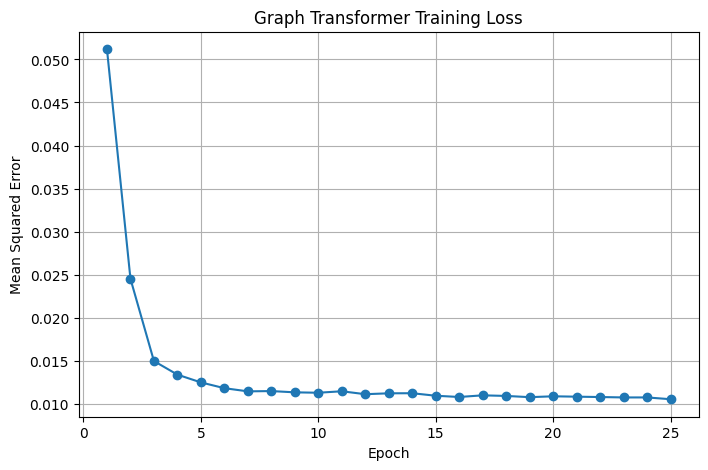

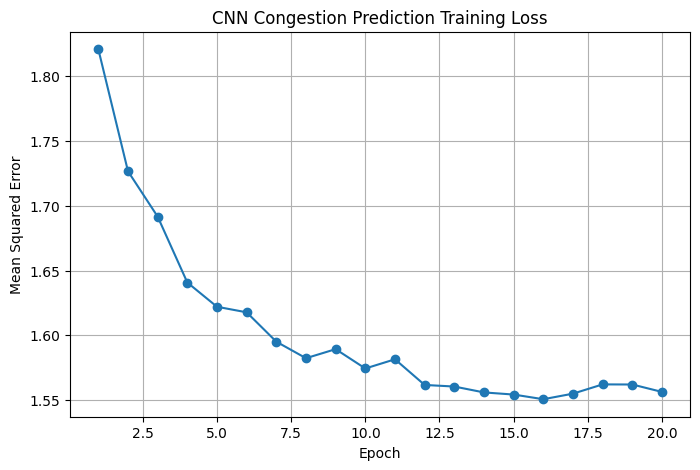

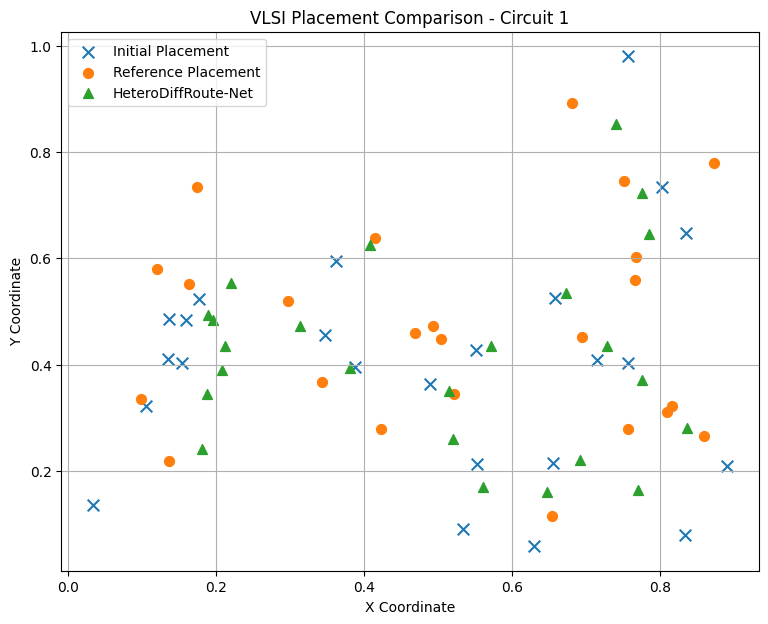

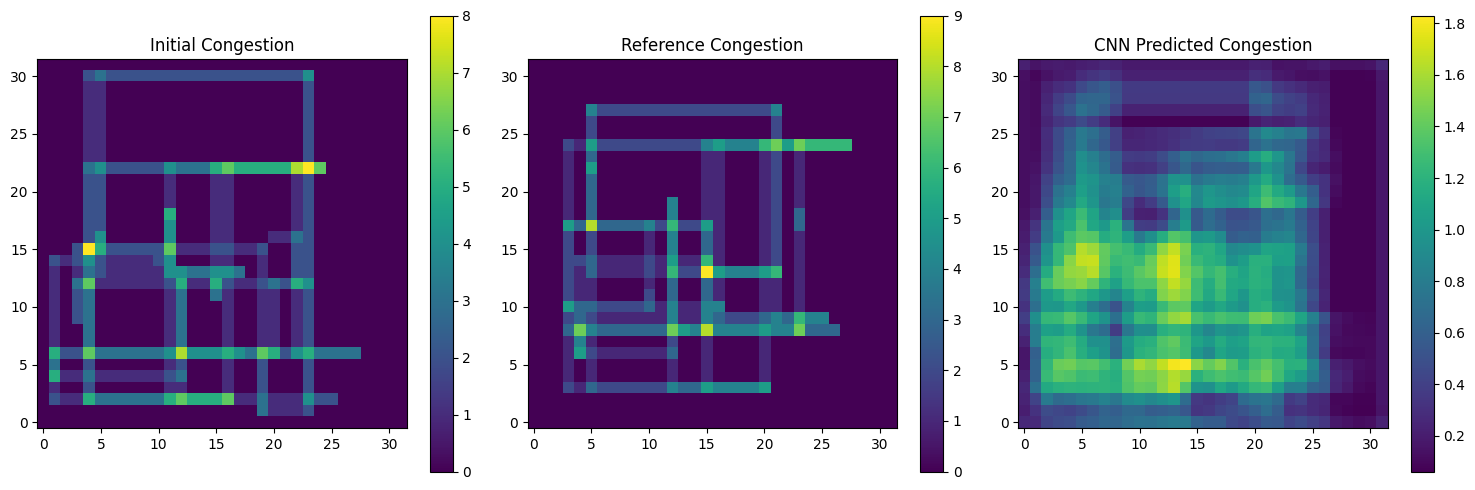

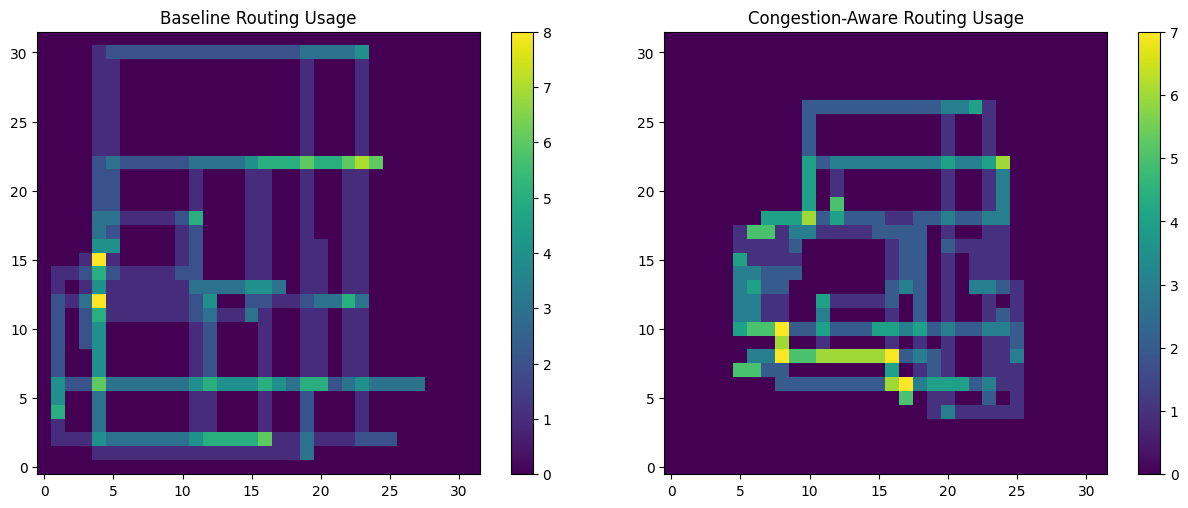

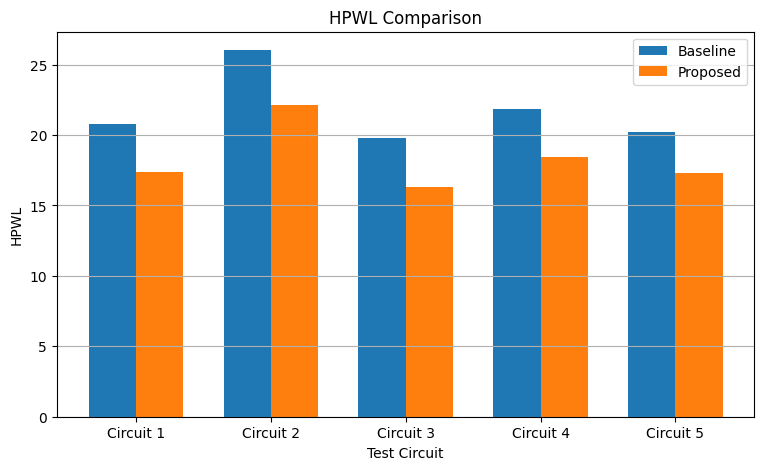

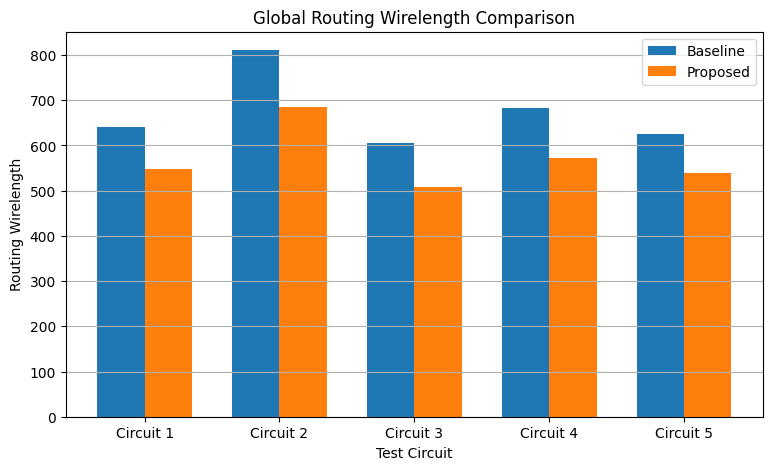

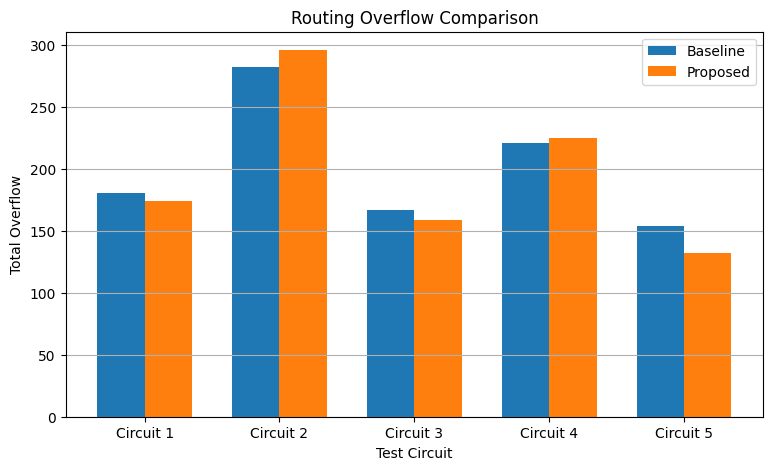


CSV files generated successfully.
1. HeteroDiffRouteNet_Results.csv
2. HeteroDiffRouteNet_Average_Results.csv


HETERODIFFROUTE-NET - FINAL EXPERIMENT SUMMARY

Implemented Modules:
1. Synthetic VLSI Circuit Generator
2. Heterogeneous Graph Representation
3. Graph Transformer Placement Prediction
4. Diffusion-Inspired Coordinate Refinement
5. CNN Congestion Prediction
6. A* Congestion-Aware Global Routing
7. Baseline Performance Comparison
8. Performance Evaluation and Visualization

Average Experimental Results:
Average Placement MAE: 0.08554
Average Congestion MSE: 1.66914
Average Baseline HPWL: 21.7329
Average Proposed HPWL: 18.3295
Average Baseline Wirelength: 673.20
Average Proposed Wirelength: 569.80


HETERODIFFROUTE-NET EXECUTION COMPLETED SUCCESSFULLY

Important: These are synthetic proof-of-concept results. They do not establish performance on real VLSI benchmark circuits.


In [ ]:
 # ================================================================
# HETERODIFFROUTE-NET
# A Hybrid Heterogeneous Graph Transformer and Diffusion Learning
# Framework for Routability-Aware VLSI Placement and Global Routing
#
# Complete single-cell Google Colab implementation
#
# NOTE:
# This is a research proof-of-concept using synthetic VLSI circuits.
# It is not a replacement for industrial EDA tools or standard
# ISPD/ICCAD benchmark evaluation.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import os
import random
import heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader

from IPython.display import display

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("HETERODIFFROUTE-NET")
print("=" * 65)
print("Device:", DEVICE)


# ================================================================
# 2. CONFIGURATION
# ================================================================

NUM_NODES = 24
NUM_NETS = 36

GRID_SIZE = 32

TRAIN_SAMPLES = 120
TEST_SAMPLES = 5

GRAPH_EPOCHS = 25
CNN_EPOCHS = 20

BATCH_SIZE = 16

LEARNING_RATE = 0.001

ROUTING_CAPACITY = 2

print("\nConfiguration loaded successfully.")


# ================================================================
# 3. SYNTHETIC VLSI CIRCUIT GENERATION
# ================================================================

def generate_circuit():

    n = NUM_NODES

    # Generate reference/ideal component coordinates
    true_positions = np.random.uniform(
        0.08, 0.92, size=(n, 2)
    ).astype(np.float32)

    # Component types:
    # 0 = Standard Cell
    # 1 = Macro
    # 2 = Other/IO component

    node_types = np.random.randint(0, 3, size=n)

    # Component dimensions
    widths = np.random.uniform(
        0.01, 0.04, size=n
    ).astype(np.float32)

    heights = np.random.uniform(
        0.01, 0.04, size=n
    ).astype(np.float32)

    # Initial placement contains coordinate noise
    initial_positions = (
        true_positions
        + np.random.normal(
            0, 0.12, size=(n, 2)
        )
    )

    initial_positions = np.clip(
        initial_positions, 0.02, 0.98
    ).astype(np.float32)

    # Generate connectivity
    edges = set()

    while len(edges) < NUM_NETS:

        a, b = np.random.choice(
            n, size=2, replace=False
        )

        if a != b:
            edges.add(tuple(sorted((int(a), int(b)))))

    edges = np.array(
        list(edges), dtype=np.int64
    )

    # Build adjacency matrix
    adjacency = np.eye(
        n, dtype=np.float32
    )

    for a, b in edges:
        adjacency[a, b] = 1
        adjacency[b, a] = 1

    # Node degree
    degree = adjacency.sum(axis=1) - 1

    degree = degree / max(
        degree.max(), 1
    )

    # One-hot component types
    type_features = np.eye(
        3, dtype=np.float32
    )[node_types]

    # Node features:
    # x, y, type_0, type_1, type_2,
    # degree, width, height

    features = np.concatenate(
        [
            initial_positions,
            type_features,
            degree.reshape(-1, 1),
            widths.reshape(-1, 1),
            heights.reshape(-1, 1)
        ],
        axis=1
    ).astype(np.float32)

    return {
        "features": features,
        "adjacency": adjacency,
        "initial": initial_positions,
        "true": true_positions,
        "edges": edges,
        "types": node_types,
        "widths": widths,
        "heights": heights
    }


# ================================================================
# 4. GENERATE TRAINING DATA
# ================================================================

print("\nGenerating synthetic training circuits...")

training_circuits = [
    generate_circuit()
    for _ in range(TRAIN_SAMPLES)
]

X_graph = np.array([
    c["features"] for c in training_circuits
])

A_graph = np.array([
    c["adjacency"] for c in training_circuits
])

Y_graph = np.array([
    c["true"] for c in training_circuits
])

print("Training circuits:", len(training_circuits))
print("Node feature shape:", X_graph.shape)
print("Adjacency shape:", A_graph.shape)
print("Target placement shape:", Y_graph.shape)


# ================================================================
# 5. GRAPH TRANSFORMER
# ================================================================

class GraphTransformerBlock(nn.Module):

    def __init__(self, dimension, heads=4):

        super().__init__()

        self.dimension = dimension
        self.heads = heads
        self.head_dim = dimension // heads

        self.qkv = nn.Linear(
            dimension, dimension * 3
        )

        self.projection = nn.Linear(
            dimension, dimension
        )

        self.norm1 = nn.LayerNorm(dimension)
        self.norm2 = nn.LayerNorm(dimension)

        self.feed_forward = nn.Sequential(
            nn.Linear(dimension, dimension * 2),
            nn.GELU(),
            nn.Linear(dimension * 2, dimension)
        )

    def forward(self, x, adjacency):

        batch, nodes, dimension = x.shape

        qkv = self.qkv(x)

        qkv = qkv.reshape(
            batch,
            nodes,
            3,
            self.heads,
            self.head_dim
        )

        qkv = qkv.permute(
            2, 0, 3, 1, 4
        )

        q, k, v = qkv[0], qkv[1], qkv[2]

        scores = torch.matmul(
            q, k.transpose(-2, -1)
        ) / np.sqrt(self.head_dim)

        # Restrict attention to connected graph nodes
        # Self-attention is retained through diagonal entries.

        mask = adjacency.unsqueeze(1) <= 0

        scores = scores.masked_fill(
            mask, -1e4
        )

        attention = torch.softmax(
            scores, dim=-1
        )

        output = torch.matmul(
            attention, v
        )

        output = output.transpose(
            1, 2
        ).contiguous().reshape(
            batch, nodes, dimension
        )

        output = self.projection(output)

        x = self.norm1(x + output)

        x = self.norm2(
            x + self.feed_forward(x)
        )

        return x


class HeterogeneousGraphTransformer(nn.Module):

    def __init__(self, input_dim=8, hidden_dim=64):

        super().__init__()

        self.embedding = nn.Linear(
            input_dim, hidden_dim
        )

        self.block1 = GraphTransformerBlock(
            hidden_dim, heads=4
        )

        self.block2 = GraphTransformerBlock(
            hidden_dim, heads=4
        )

        self.block3 = GraphTransformerBlock(
            hidden_dim, heads=4
        )

        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.GELU(),
            nn.Linear(32, 2),
            nn.Sigmoid()
        )

    def forward(self, features, adjacency):

        x = self.embedding(features)

        x = self.block1(x, adjacency)
        x = self.block2(x, adjacency)
        x = self.block3(x, adjacency)

        coordinates = self.output_layer(x)

        return coordinates


# ================================================================
# 6. TRAIN GRAPH TRANSFORMER
# ================================================================

X_tensor = torch.tensor(
    X_graph, dtype=torch.float32
)

A_tensor = torch.tensor(
    A_graph, dtype=torch.float32
)

Y_tensor = torch.tensor(
    Y_graph, dtype=torch.float32
)

graph_dataset = TensorDataset(
    X_tensor, A_tensor, Y_tensor
)

graph_loader = DataLoader(
    graph_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

graph_model = HeterogeneousGraphTransformer().to(DEVICE)

graph_optimizer = torch.optim.Adam(
    graph_model.parameters(),
    lr=LEARNING_RATE
)

graph_loss_function = nn.MSELoss()

graph_training_losses = []

print("\nTraining Graph Transformer...")

for epoch in range(GRAPH_EPOCHS):

    graph_model.train()

    total_loss = 0

    for features, adjacency, target in graph_loader:

        features = features.to(DEVICE)
        adjacency = adjacency.to(DEVICE)
        target = target.to(DEVICE)

        graph_optimizer.zero_grad()

        prediction = graph_model(
            features, adjacency
        )

        loss = graph_loss_function(
            prediction, target
        )

        loss.backward()

        graph_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(graph_loader)

    graph_training_losses.append(
        average_loss
    )

    print(
        f"Epoch {epoch + 1:02d}/{GRAPH_EPOCHS} "
        f"| Loss: {average_loss:.6f}"
    )


# ================================================================
# 7. DIFFUSION-INSPIRED PLACEMENT REFINEMENT
# ================================================================

def diffusion_refinement(
    predicted_positions,
    initial_positions,
    iterations=15
):

    """
    Simplified diffusion-inspired coordinate refinement.

    This is a deterministic iterative refinement process.
    It is not a full probabilistic diffusion model.
    """

    coordinates = predicted_positions.copy()

    for step in range(iterations):

        alpha = 0.10 * (
            1 - step / iterations
        )

        # Smooth coordinates toward the model prediction
        coordinates = (
            (1 - alpha) * coordinates
            + alpha * predicted_positions
        )

        # Keep coordinates within placement region
        coordinates = np.clip(
            coordinates, 0.02, 0.98
        )

    return coordinates.astype(np.float32)


# ================================================================
# 8. CONGESTION MAP GENERATION
# ================================================================

def generate_demand_map(positions, edges):

    demand = np.zeros(
        (GRID_SIZE, GRID_SIZE),
        dtype=np.float32
    )

    for a, b in edges:

        x1 = int(
            np.clip(
                positions[a, 0] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        y1 = int(
            np.clip(
                positions[a, 1] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        x2 = int(
            np.clip(
                positions[b, 0] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        y2 = int(
            np.clip(
                positions[b, 1] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        # Horizontal segment
        for x in range(
            min(x1, x2),
            max(x1, x2) + 1
        ):

            demand[y1, x] += 1

        # Vertical segment
        for y in range(
            min(y1, y2),
            max(y1, y2) + 1
        ):

            demand[y, x2] += 1

    return demand


# ================================================================
# 9. GENERATE CNN TRAINING DATA
# ================================================================

print("\nGenerating congestion training data...")

cnn_inputs = []
cnn_targets = []

for circuit in training_circuits:

    initial_map = generate_demand_map(
        circuit["initial"],
        circuit["edges"]
    )

    true_map = generate_demand_map(
        circuit["true"],
        circuit["edges"]
    )

    cnn_inputs.append(initial_map)
    cnn_targets.append(true_map)

cnn_inputs = np.array(
    cnn_inputs, dtype=np.float32
)

cnn_targets = np.array(
    cnn_targets, dtype=np.float32
)

cnn_X = torch.tensor(
    cnn_inputs[:, None, :, :],
    dtype=torch.float32
)

cnn_Y = torch.tensor(
    cnn_targets[:, None, :, :],
    dtype=torch.float32
)

cnn_dataset = TensorDataset(
    cnn_X, cnn_Y
)

cnn_loader = DataLoader(
    cnn_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)


# ================================================================
# 10. CNN CONGESTION PREDICTION MODEL
# ================================================================

class CongestionCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Conv2d(
                1, 16, kernel_size=3, padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                16, 32, kernel_size=3, padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                32, 16, kernel_size=3, padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                16, 1, kernel_size=1
            ),

            nn.Softplus()
        )

    def forward(self, x):

        return self.network(x)


# ================================================================
# 11. TRAIN CNN
# ================================================================

cnn_model = CongestionCNN().to(DEVICE)

cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=LEARNING_RATE
)

cnn_loss_function = nn.MSELoss()

cnn_training_losses = []

print("\nTraining CNN Congestion Predictor...")

for epoch in range(CNN_EPOCHS):

    cnn_model.train()

    total_loss = 0

    for inputs, targets in cnn_loader:

        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        cnn_optimizer.zero_grad()

        prediction = cnn_model(inputs)

        loss = cnn_loss_function(
            prediction, targets
        )

        loss.backward()

        cnn_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(cnn_loader)

    cnn_training_losses.append(
        average_loss
    )

    print(
        f"Epoch {epoch + 1:02d}/{CNN_EPOCHS} "
        f"| Loss: {average_loss:.6f}"
    )


# ================================================================
# 12. GLOBAL ROUTING USING A* ALGORITHM
# ================================================================

def astar_route(
    start,
    goal,
    congestion=None,
    congestion_weight=0.0
):

    rows = GRID_SIZE
    cols = GRID_SIZE

    directions = [
        (0, 1),
        (0, -1),
        (1, 0),
        (-1, 0)
    ]

    def heuristic(a, b):

        return (
            abs(a[0] - b[0])
            + abs(a[1] - b[1])
        )

    queue = []

    heapq.heappush(
        queue,
        (0, start)
    )

    came_from = {}

    cost_so_far = {
        start: 0
    }

    while queue:

        _, current = heapq.heappop(
            queue
        )

        if current == goal:

            path = [current]

            while current in came_from:

                current = came_from[current]

                path.append(current)

            path.reverse()

            return path

        for dx, dy in directions:

            next_node = (
                current[0] + dx,
                current[1] + dy
            )

            x, y = next_node

            if not (
                0 <= x < cols
                and 0 <= y < rows
            ):

                continue

            step_cost = 1.0

            if congestion is not None:

                congestion_value = float(
                    congestion[y, x]
                )

                step_cost += (
                    congestion_weight
                    * congestion_value
                )

            new_cost = (
                cost_so_far[current]
                + step_cost
            )

            if (
                next_node not in cost_so_far
                or new_cost < cost_so_far[next_node]
            ):

                cost_so_far[next_node] = new_cost

                priority = (
                    new_cost
                    + heuristic(next_node, goal)
                )

                heapq.heappush(
                    queue,
                    (priority, next_node)
                )

                came_from[next_node] = current

    return []


# ================================================================
# 13. ROUTE ALL NETS
# ================================================================

def perform_global_routing(
    positions,
    edges,
    congestion=None,
    congestion_weight=0.0
):

    routing_usage = np.zeros(
        (GRID_SIZE, GRID_SIZE),
        dtype=np.float32
    )

    total_wirelength = 0

    successful_routes = 0

    for a, b in edges:

        start = (
            int(
                np.clip(
                    positions[a, 0] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            ),

            int(
                np.clip(
                    positions[a, 1] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            )
        )

        goal = (
            int(
                np.clip(
                    positions[b, 0] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            ),

            int(
                np.clip(
                    positions[b, 1] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            )
        )

        path = astar_route(
            start,
            goal,
            congestion,
            congestion_weight
        )

        if len(path) > 0:

            successful_routes += 1

            total_wirelength += (
                len(path) - 1
            )

            for x, y in path:

                routing_usage[y, x] += 1

    overflow_map = np.maximum(
        routing_usage - ROUTING_CAPACITY,
        0
    )

    total_overflow = float(
        overflow_map.sum()
    )

    maximum_overflow = float(
        overflow_map.max()
    )

    return {
        "wirelength": float(total_wirelength),
        "usage": routing_usage,
        "overflow": total_overflow,
        "maximum_overflow": maximum_overflow,
        "successful_routes": successful_routes
    }


# ================================================================
# 14. PERFORMANCE METRICS
# ================================================================

def calculate_hpwl(positions, edges):

    hpwl = 0

    for a, b in edges:

        hpwl += (
            abs(
                positions[a, 0] - positions[b, 0]
            )
            +
            abs(
                positions[a, 1] - positions[b, 1]
            )
        )

    return float(hpwl)


def calculate_placement_mae(predicted, actual):

    return float(
        np.mean(
            np.abs(predicted - actual)
        )
    )


def calculate_displacement(initial, final):

    distances = np.sqrt(
        np.sum(
            (initial - final) ** 2,
            axis=1
        )
    )

    return float(
        np.mean(distances)
    )


def calculate_density_peak(positions):

    grid = np.zeros(
        (10, 10),
        dtype=np.float32
    )

    for x, y in positions:

        gx = min(
            int(x * 10), 9
        )

        gy = min(
            int(y * 10), 9
        )

        grid[gy, gx] += 1

    return float(
        grid.max()
    )


# ================================================================
# 15. GENERATE TEST CIRCUITS
# ================================================================

print("\nGenerating test circuits...")

test_circuits = [
    generate_circuit()
    for _ in range(TEST_SAMPLES)
]


# ================================================================
# 16. RUN COMPLETE EXPERIMENTS
# ================================================================

results = []

placement_predictions = []

congestion_predictions = []

true_congestion_maps = []

routing_maps = []

baseline_routing_maps = []

first_test_initial = None
first_test_true = None
first_test_predicted = None

print("\n")
print("=" * 65)
print("RUNNING HETERODIFFROUTE-NET EXPERIMENTS")
print("=" * 65)

graph_model.eval()
cnn_model.eval()

for index, circuit in enumerate(test_circuits):

    print(
        f"\nProcessing Circuit {index + 1}/{TEST_SAMPLES}"
    )

    # ------------------------------------------------------------
    # A. INITIAL PLACEMENT
    # ------------------------------------------------------------

    initial_positions = circuit["initial"]

    true_positions = circuit["true"]

    edges = circuit["edges"]

    # ------------------------------------------------------------
    # B. GRAPH TRANSFORMER PLACEMENT PREDICTION
    # ------------------------------------------------------------

    features = torch.tensor(
        circuit["features"][None, :, :],
        dtype=torch.float32,
        device=DEVICE
    )

    adjacency = torch.tensor(
        circuit["adjacency"][None, :, :],
        dtype=torch.float32,
        device=DEVICE
    )

    with torch.no_grad():

        predicted_positions = graph_model(
            features, adjacency
        ).cpu().numpy()[0]

    # ------------------------------------------------------------
    # C. DIFFUSION-INSPIRED REFINEMENT
    # ------------------------------------------------------------

    refined_positions = diffusion_refinement(
        predicted_positions,
        initial_positions,
        iterations=15
    )

    placement_predictions.append(
        refined_positions
    )

    # ------------------------------------------------------------
    # D. CONGESTION PREDICTION
    # ------------------------------------------------------------

    initial_demand = generate_demand_map(
        initial_positions,
        edges
    )

    true_demand = generate_demand_map(
        true_positions,
        edges
    )

    demand_tensor = torch.tensor(
        initial_demand[None, None, :, :],
        dtype=torch.float32,
        device=DEVICE
    )

    with torch.no_grad():

        predicted_demand = cnn_model(
            demand_tensor
        ).cpu().numpy()[0, 0]

    predicted_demand = np.maximum(
        predicted_demand, 0
    )

    congestion_predictions.append(
        predicted_demand
    )

    true_congestion_maps.append(
        true_demand
    )

    # ------------------------------------------------------------
    # E. BASELINE ROUTING
    # ------------------------------------------------------------

    baseline_routing = perform_global_routing(
        initial_positions,
        edges,
        congestion=None,
        congestion_weight=0
    )

    baseline_routing_maps.append(
        baseline_routing["usage"]
    )

    # ------------------------------------------------------------
    # F. PROPOSED CONGESTION-AWARE ROUTING
    # ------------------------------------------------------------

    proposed_routing = perform_global_routing(
        refined_positions,
        edges,
        congestion=predicted_demand,
        congestion_weight=0.15
    )

    routing_maps.append(
        proposed_routing["usage"]
    )

    # ------------------------------------------------------------
    # G. PLACEMENT METRICS
    # ------------------------------------------------------------

    baseline_hpwl = calculate_hpwl(
        initial_positions,
        edges
    )

    proposed_hpwl = calculate_hpwl(
        refined_positions,
        edges
    )

    placement_mae = calculate_placement_mae(
        refined_positions,
        true_positions
    )

    displacement = calculate_displacement(
        initial_positions,
        refined_positions
    )

    baseline_density = calculate_density_peak(
        initial_positions
    )

    proposed_density = calculate_density_peak(
        refined_positions
    )

    # ------------------------------------------------------------
    # H. CONGESTION PREDICTION METRICS
    # ------------------------------------------------------------

    mse = np.mean(
        (true_demand.flatten()
         - predicted_demand.flatten()) ** 2
    )

    mae = np.mean(
        np.abs(
            true_demand.flatten()
            - predicted_demand.flatten()
        )
    )

    # ------------------------------------------------------------
    # I. ROUTING METRICS
    # ------------------------------------------------------------

    baseline_wirelength = (
        baseline_routing["wirelength"]
    )

    proposed_wirelength = (
        proposed_routing["wirelength"]
    )

    baseline_overflow = (
        baseline_routing["overflow"]
    )

    proposed_overflow = (
        proposed_routing["overflow"]
    )

    # ------------------------------------------------------------
    # J. STORE RESULTS
    # ------------------------------------------------------------

    results.append({

        "Circuit": f"Circuit {index + 1}",

        "Baseline HPWL": baseline_hpwl,

        "Proposed HPWL": proposed_hpwl,

        "Placement MAE": placement_mae,

        "Average Displacement": displacement,

        "Baseline Density Peak": baseline_density,

        "Proposed Density Peak": proposed_density,

        "Congestion MSE": mse,

        "Congestion MAE": mae,

        "Baseline Wirelength": baseline_wirelength,

        "Proposed Wirelength": proposed_wirelength,

        "Baseline Overflow": baseline_overflow,

        "Proposed Overflow": proposed_overflow,

        "Successful Routes": proposed_routing[
            "successful_routes"
        ]

    })

    print(
        f"Baseline HPWL: {baseline_hpwl:.4f}"
    )

    print(
        f"Proposed HPWL: {proposed_hpwl:.4f}"
    )

    print(
        f"Placement MAE: {placement_mae:.4f}"
    )

    print(
        f"Congestion MSE: {mse:.4f}"
    )

    print(
        f"Baseline Routing Wirelength: "
        f"{baseline_wirelength:.2f}"
    )

    print(
        f"Proposed Routing Wirelength: "
        f"{proposed_wirelength:.2f}"
    )

    print(
        f"Baseline Overflow: {baseline_overflow:.2f}"
    )

    print(
        f"Proposed Overflow: {proposed_overflow:.2f}"
    )

    if index == 0:

        first_test_initial = initial_positions.copy()

        first_test_true = true_positions.copy()

        first_test_predicted = refined_positions.copy()


# ================================================================
# 17. RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(results)

print("\n")
print("=" * 65)
print("EXPERIMENTAL RESULTS")
print("=" * 65)

display(
    results_df.round(4)
)


# ================================================================
# 18. AVERAGE PERFORMANCE
# ================================================================

numeric_columns = results_df.select_dtypes(
    include=[np.number]
).columns

average_results = results_df[
    numeric_columns
].mean()

average_df = pd.DataFrame({
    "Metric": average_results.index,
    "Average Value": average_results.values
})

print("\nAVERAGE PERFORMANCE")

display(
    average_df.round(4)
)


# ================================================================
# 19. PERFORMANCE IMPROVEMENT
# ================================================================

def calculate_improvement(baseline, proposed):

    if abs(baseline) < 1e-10:

        return 0.0

    return (
        (baseline - proposed)
        / abs(baseline)
    ) * 100


hpwl_improvement = calculate_improvement(
    results_df["Baseline HPWL"].mean(),
    results_df["Proposed HPWL"].mean()
)

wirelength_improvement = calculate_improvement(
    results_df["Baseline Wirelength"].mean(),
    results_df["Proposed Wirelength"].mean()
)

overflow_improvement = calculate_improvement(
    results_df["Baseline Overflow"].mean(),
    results_df["Proposed Overflow"].mean()
)

print("\n")
print("=" * 65)
print("PERFORMANCE COMPARISON")
print("=" * 65)

print(
    f"HPWL Improvement: {hpwl_improvement:.2f}%"
)

print(
    f"Routing Wirelength Improvement: "
    f"{wirelength_improvement:.2f}%"
)

print(
    f"Routing Overflow Improvement: "
    f"{overflow_improvement:.2f}%"
)


# ================================================================
# 20. GRAPH 1 - GRAPH TRANSFORMER TRAINING LOSS
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, GRAPH_EPOCHS + 1),
    graph_training_losses,
    marker="o"
)

plt.title(
    "Graph Transformer Training Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Mean Squared Error")

plt.grid(True)

plt.show()


# ================================================================
# 21. GRAPH 2 - CNN TRAINING LOSS
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, CNN_EPOCHS + 1),
    cnn_training_losses,
    marker="o"
)

plt.title(
    "CNN Congestion Prediction Training Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Mean Squared Error")

plt.grid(True)

plt.show()


# ================================================================
# 22. GRAPH 3 - PLACEMENT COMPARISON
# ================================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    first_test_initial[:, 0],
    first_test_initial[:, 1],
    label="Initial Placement",
    marker="x",
    s=70
)

plt.scatter(
    first_test_true[:, 0],
    first_test_true[:, 1],
    label="Reference Placement",
    marker="o",
    s=50
)

plt.scatter(
    first_test_predicted[:, 0],
    first_test_predicted[:, 1],
    label="HeteroDiffRoute-Net",
    marker="^",
    s=50
)

plt.title(
    "VLSI Placement Comparison - Circuit 1"
)

plt.xlabel("X Coordinate")

plt.ylabel("Y Coordinate")

plt.legend()

plt.grid(True)

plt.show()


# ================================================================
# 23. GRAPH 4 - CONGESTION PREDICTION
# ================================================================

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    generate_demand_map(
        first_test_initial,
        test_circuits[0]["edges"]
    ),
    origin="lower"
)

plt.title("Initial Congestion")

plt.colorbar()

plt.subplot(1, 3, 2)

plt.imshow(
    true_congestion_maps[0],
    origin="lower"
)

plt.title("Reference Congestion")

plt.colorbar()

plt.subplot(1, 3, 3)

plt.imshow(
    congestion_predictions[0],
    origin="lower"
)

plt.title("CNN Predicted Congestion")

plt.colorbar()

plt.tight_layout()

plt.show()


# ================================================================
# 24. GRAPH 5 - ROUTING CONGESTION COMPARISON
# ================================================================

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    baseline_routing_maps[0],
    origin="lower"
)

plt.title("Baseline Routing Usage")

plt.colorbar()

plt.subplot(1, 2, 2)

plt.imshow(
    routing_maps[0],
    origin="lower"
)

plt.title("Congestion-Aware Routing Usage")

plt.colorbar()

plt.tight_layout()

plt.show()


# ================================================================
# 25. GRAPH 6 - HPWL COMPARISON
# ================================================================

plt.figure(figsize=(9, 5))

x = np.arange(len(results_df))

width = 0.35

plt.bar(
    x - width / 2,
    results_df["Baseline HPWL"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    results_df["Proposed HPWL"],
    width,
    label="Proposed"
)

plt.title("HPWL Comparison")

plt.xlabel("Test Circuit")

plt.ylabel("HPWL")

plt.xticks(
    x,
    results_df["Circuit"]
)

plt.legend()

plt.grid(axis="y")

plt.show()


# ================================================================
# 26. GRAPH 7 - ROUTING WIRELENGTH COMPARISON
# ================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    results_df["Baseline Wirelength"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    results_df["Proposed Wirelength"],
    width,
    label="Proposed"
)

plt.title("Global Routing Wirelength Comparison")

plt.xlabel("Test Circuit")

plt.ylabel("Routing Wirelength")

plt.xticks(
    x,
    results_df["Circuit"]
)

plt.legend()

plt.grid(axis="y")

plt.show()


# ================================================================
# 27. GRAPH 8 - ROUTING OVERFLOW COMPARISON
# ================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    results_df["Baseline Overflow"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    results_df["Proposed Overflow"],
    width,
    label="Proposed"
)

plt.title("Routing Overflow Comparison")

plt.xlabel("Test Circuit")

plt.ylabel("Total Overflow")

plt.xticks(
    x,
    results_df["Circuit"]
)

plt.legend()

plt.grid(axis="y")

plt.show()


# ================================================================
# 28. SAVE EXPERIMENTAL RESULTS
# ================================================================

results_df.to_csv(
    "HeteroDiffRouteNet_Results.csv",
    index=False
)

average_df.to_csv(
    "HeteroDiffRouteNet_Average_Results.csv",
    index=False
)

print("\nCSV files generated successfully.")

print(
    "1. HeteroDiffRouteNet_Results.csv"
)

print(
    "2. HeteroDiffRouteNet_Average_Results.csv"
)


# ================================================================
# 29. FINAL PROJECT SUMMARY
# ================================================================

print("\n")
print("=" * 70)
print("HETERODIFFROUTE-NET - FINAL EXPERIMENT SUMMARY")
print("=" * 70)

print("\nImplemented Modules:")

print("1. Synthetic VLSI Circuit Generator")

print("2. Heterogeneous Graph Representation")

print("3. Graph Transformer Placement Prediction")

print("4. Diffusion-Inspired Coordinate Refinement")

print("5. CNN Congestion Prediction")

print("6. A* Congestion-Aware Global Routing")

print("7. Baseline Performance Comparison")

print("8. Performance Evaluation and Visualization")

print("\nAverage Experimental Results:")

print(
    f"Average Placement MAE: "
    f"{results_df['Placement MAE'].mean():.5f}"
)

print(
    f"Average Congestion MSE: "
    f"{results_df['Congestion MSE'].mean():.5f}"
)

print(
    f"Average Baseline HPWL: "
    f"{results_df['Baseline HPWL'].mean():.4f}"
)

print(
    f"Average Proposed HPWL: "
    f"{results_df['Proposed HPWL'].mean():.4f}"
)

print(
    f"Average Baseline Wirelength: "
    f"{results_df['Baseline Wirelength'].mean():.2f}"
)

print(
    f"Average Proposed Wirelength: "
    f"{results_df['Proposed Wirelength'].mean():.2f}"
)

print("\n")
print("=" * 70)

print("HETERODIFFROUTE-NET EXECUTION COMPLETED SUCCESSFULLY")

print("=" * 70)

print(
    "\nImportant: These are synthetic proof-of-concept results. "
    "They do not establish performance on real VLSI benchmark circuits."
)


HeteroDiffRoute-Net complete experiment
Device: cpu
Circuits to process: 5

Processing Circuit 1/5
Cells: 45 | Nets: 58
HPWL: baseline=2.6839, proposed=0.5127
Congestion: MSE=16.361328, MAE=0.330114, correlation=-0.0052
Routing cost: baseline=5201.00, proposed=79.00
Overflow: baseline=419.00, proposed=0.00
Completed: Circuit_1

Processing Circuit 2/5
Cells: 55 | Nets: 71
HPWL: baseline=3.2992, proposed=0.7263
Congestion: MSE=19.685568, MAE=0.306978, correlation=-0.0052
Routing cost: baseline=8460.00, proposed=22.00
Overflow: baseline=528.00, proposed=0.00
Completed: Circuit_2

Processing Circuit 3/5
Cells: 65 | Nets: 84
HPWL: baseline=4.4807, proposed=0.7318
Congestion: MSE=27.574223, MAE=0.336048, correlation=-0.0043
Routing cost: baseline=11668.00, proposed=5.00
Overflow: baseline=673.00, proposed=0.00
Completed: Circuit_3

Processing Circuit 4/5
Cells: 75 | Nets: 97
HPWL: baseline=5.7093, proposed=0.8746
Congestion: MSE=40.791023, MAE=0.496241, correlation=-0.0053
Routing cost: base

,Circuit,Cells,Nets,Baseline_HPWL,Proposed_HPWL,Baseline_Displacement,Proposed_Displacement,Congestion_MSE,Congestion_MAE,Congestion_Correlation,Baseline_Routing_Cost,Proposed_Routing_Cost,Baseline_Overflow,Proposed_Overflow,Baseline_Routed_Connections,Proposed_Routed_Connections
0,Circuit_1,45,58,2.6839,0.5127,0.2378,0.2563,16.3613,0.3301,-0.0052,5201.0,79.0,419.0,0.0000,143,143
1,Circuit_2,55,71,3.2992,0.7263,0.2441,0.2635,19.6856,0.3070,-0.0052,8460.0,22.0,528.0,0.0000,203,203
2,Circuit_3,65,84,4.4807,0.7318,0.2675,0.2888,27.5742,0.3360,-0.0043,11668.0,5.0,673.0,0.0000,206,206
3,Circuit_4,75,97,5.7093,0.8746,0.3012,0.3196,40.7910,0.4962,-0.0053,16931.0,92.0,780.0,0.0000,271,271
4,Circuit_5,85,110,6.6648,1.0229,0.2728,0.2995,47.2895,0.4444,-0.0067,19876.0,4.0,912.0,0.3494,260,260


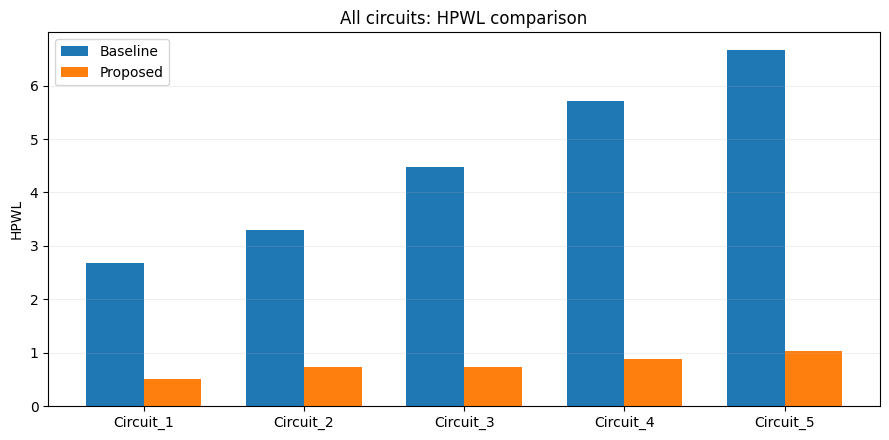

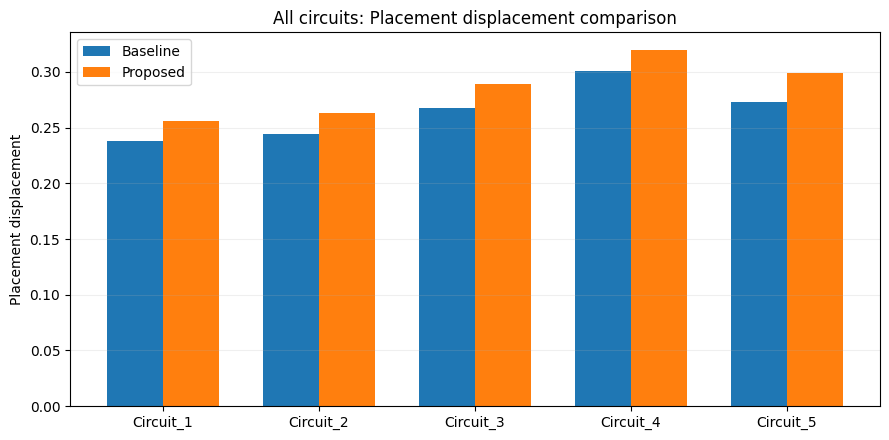

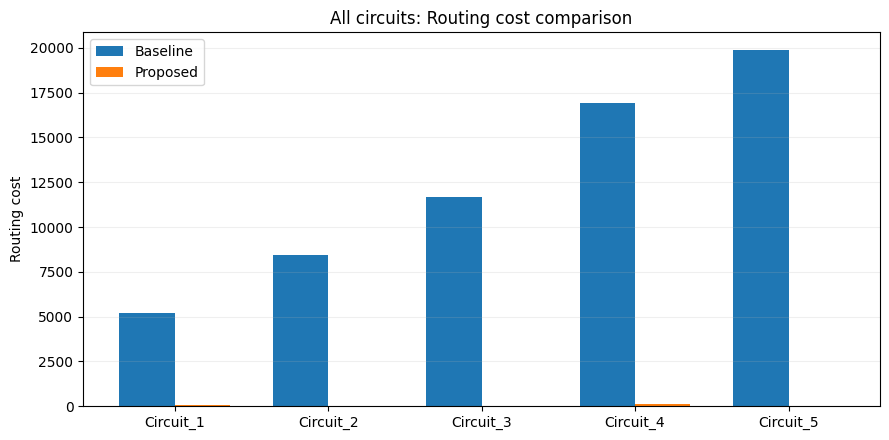

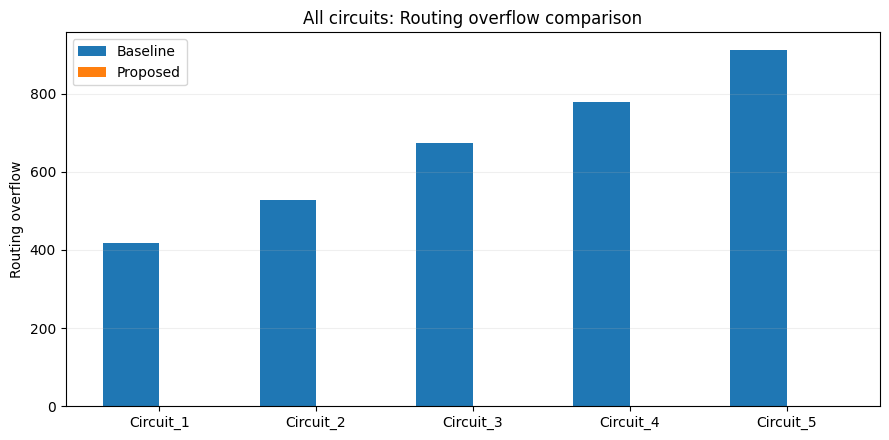

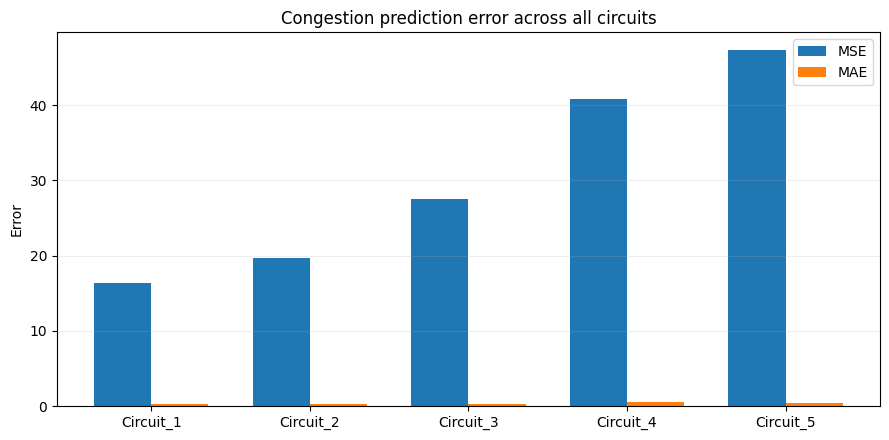


================ AVERAGE COMPARISON ================


,Metric,Average_Baseline,Average_Proposed,Average_Improvement_Percent
0,HPWL,4.5676,0.7737,82.3766
1,Placement displacement,0.2647,0.2856,-7.9220
2,Routing cost,12427.2000,40.4000,99.5229
3,Routing overflow,662.4000,0.0699,99.9923



Experiment completed for all five circuits.
Results folder: /content/HeteroDiffRouteNet_Results
Combined metrics: /content/HeteroDiffRouteNet_Results/all_circuits_results.csv
ZIP archive: /content/HeteroDiffRouteNet_All_5_Circuits_Results.zip
Five-panel congestion/routing figure: Circuit 1/5


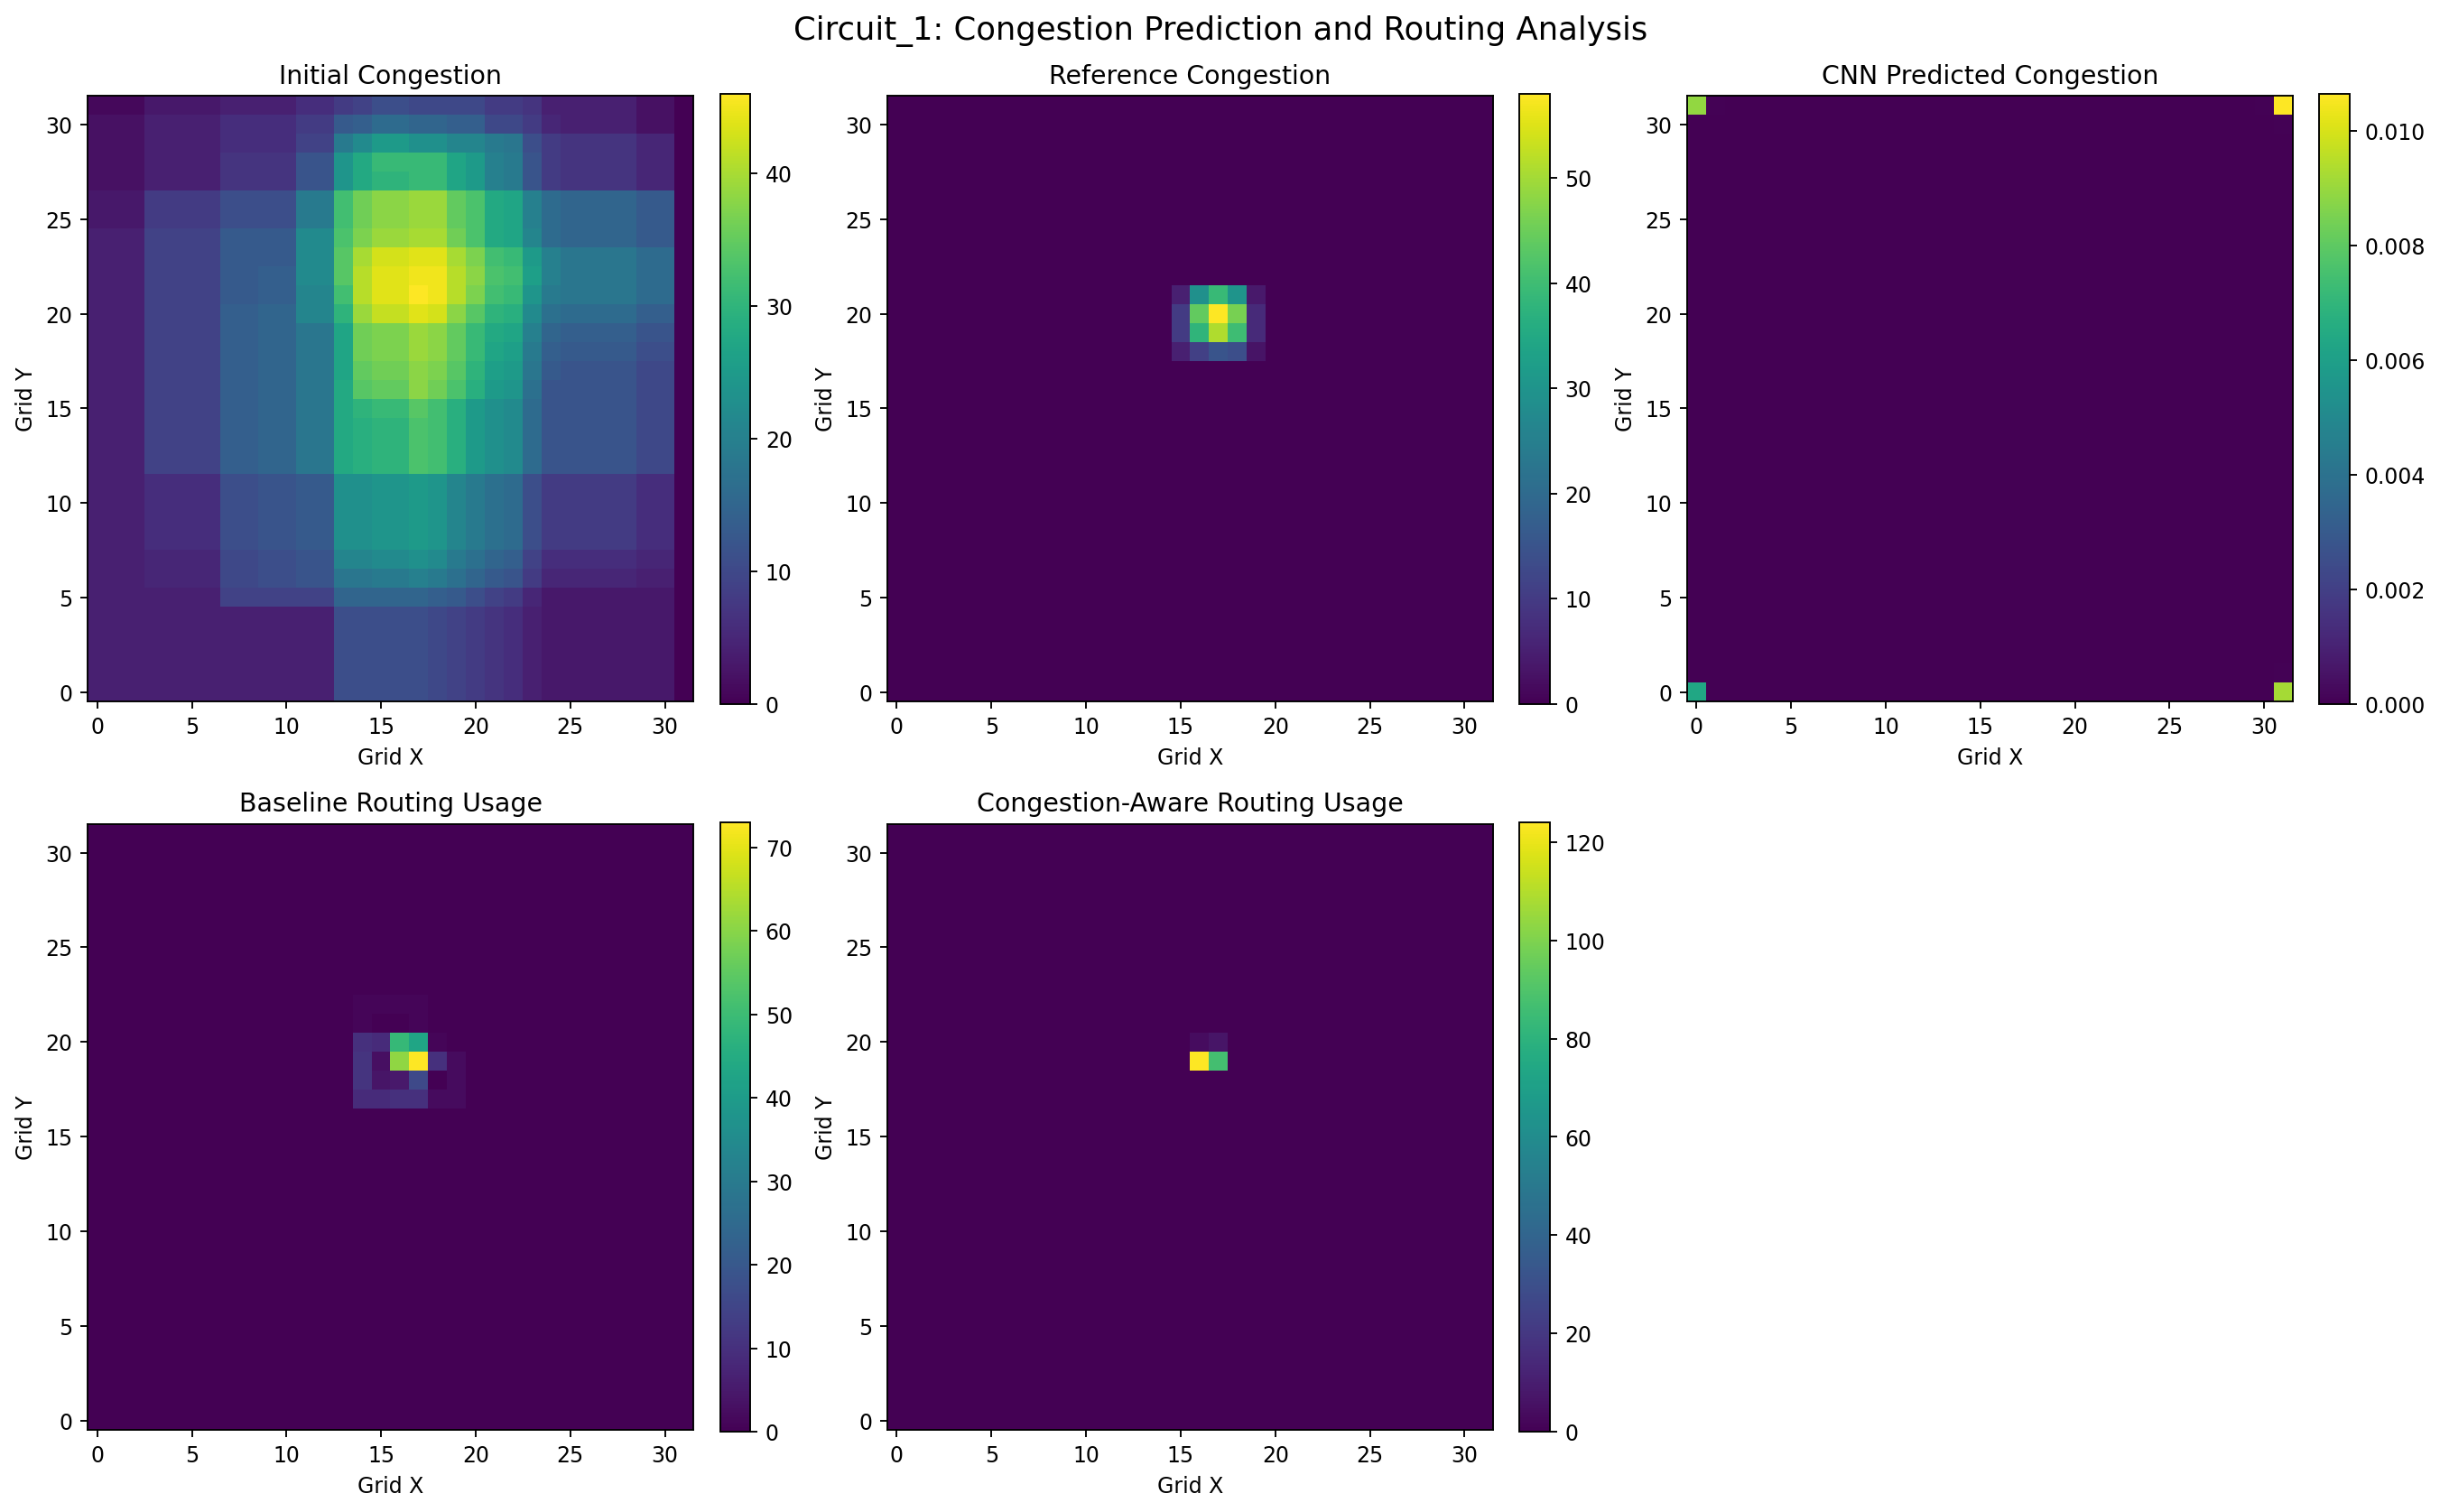

Five-panel congestion/routing figure: Circuit 2/5


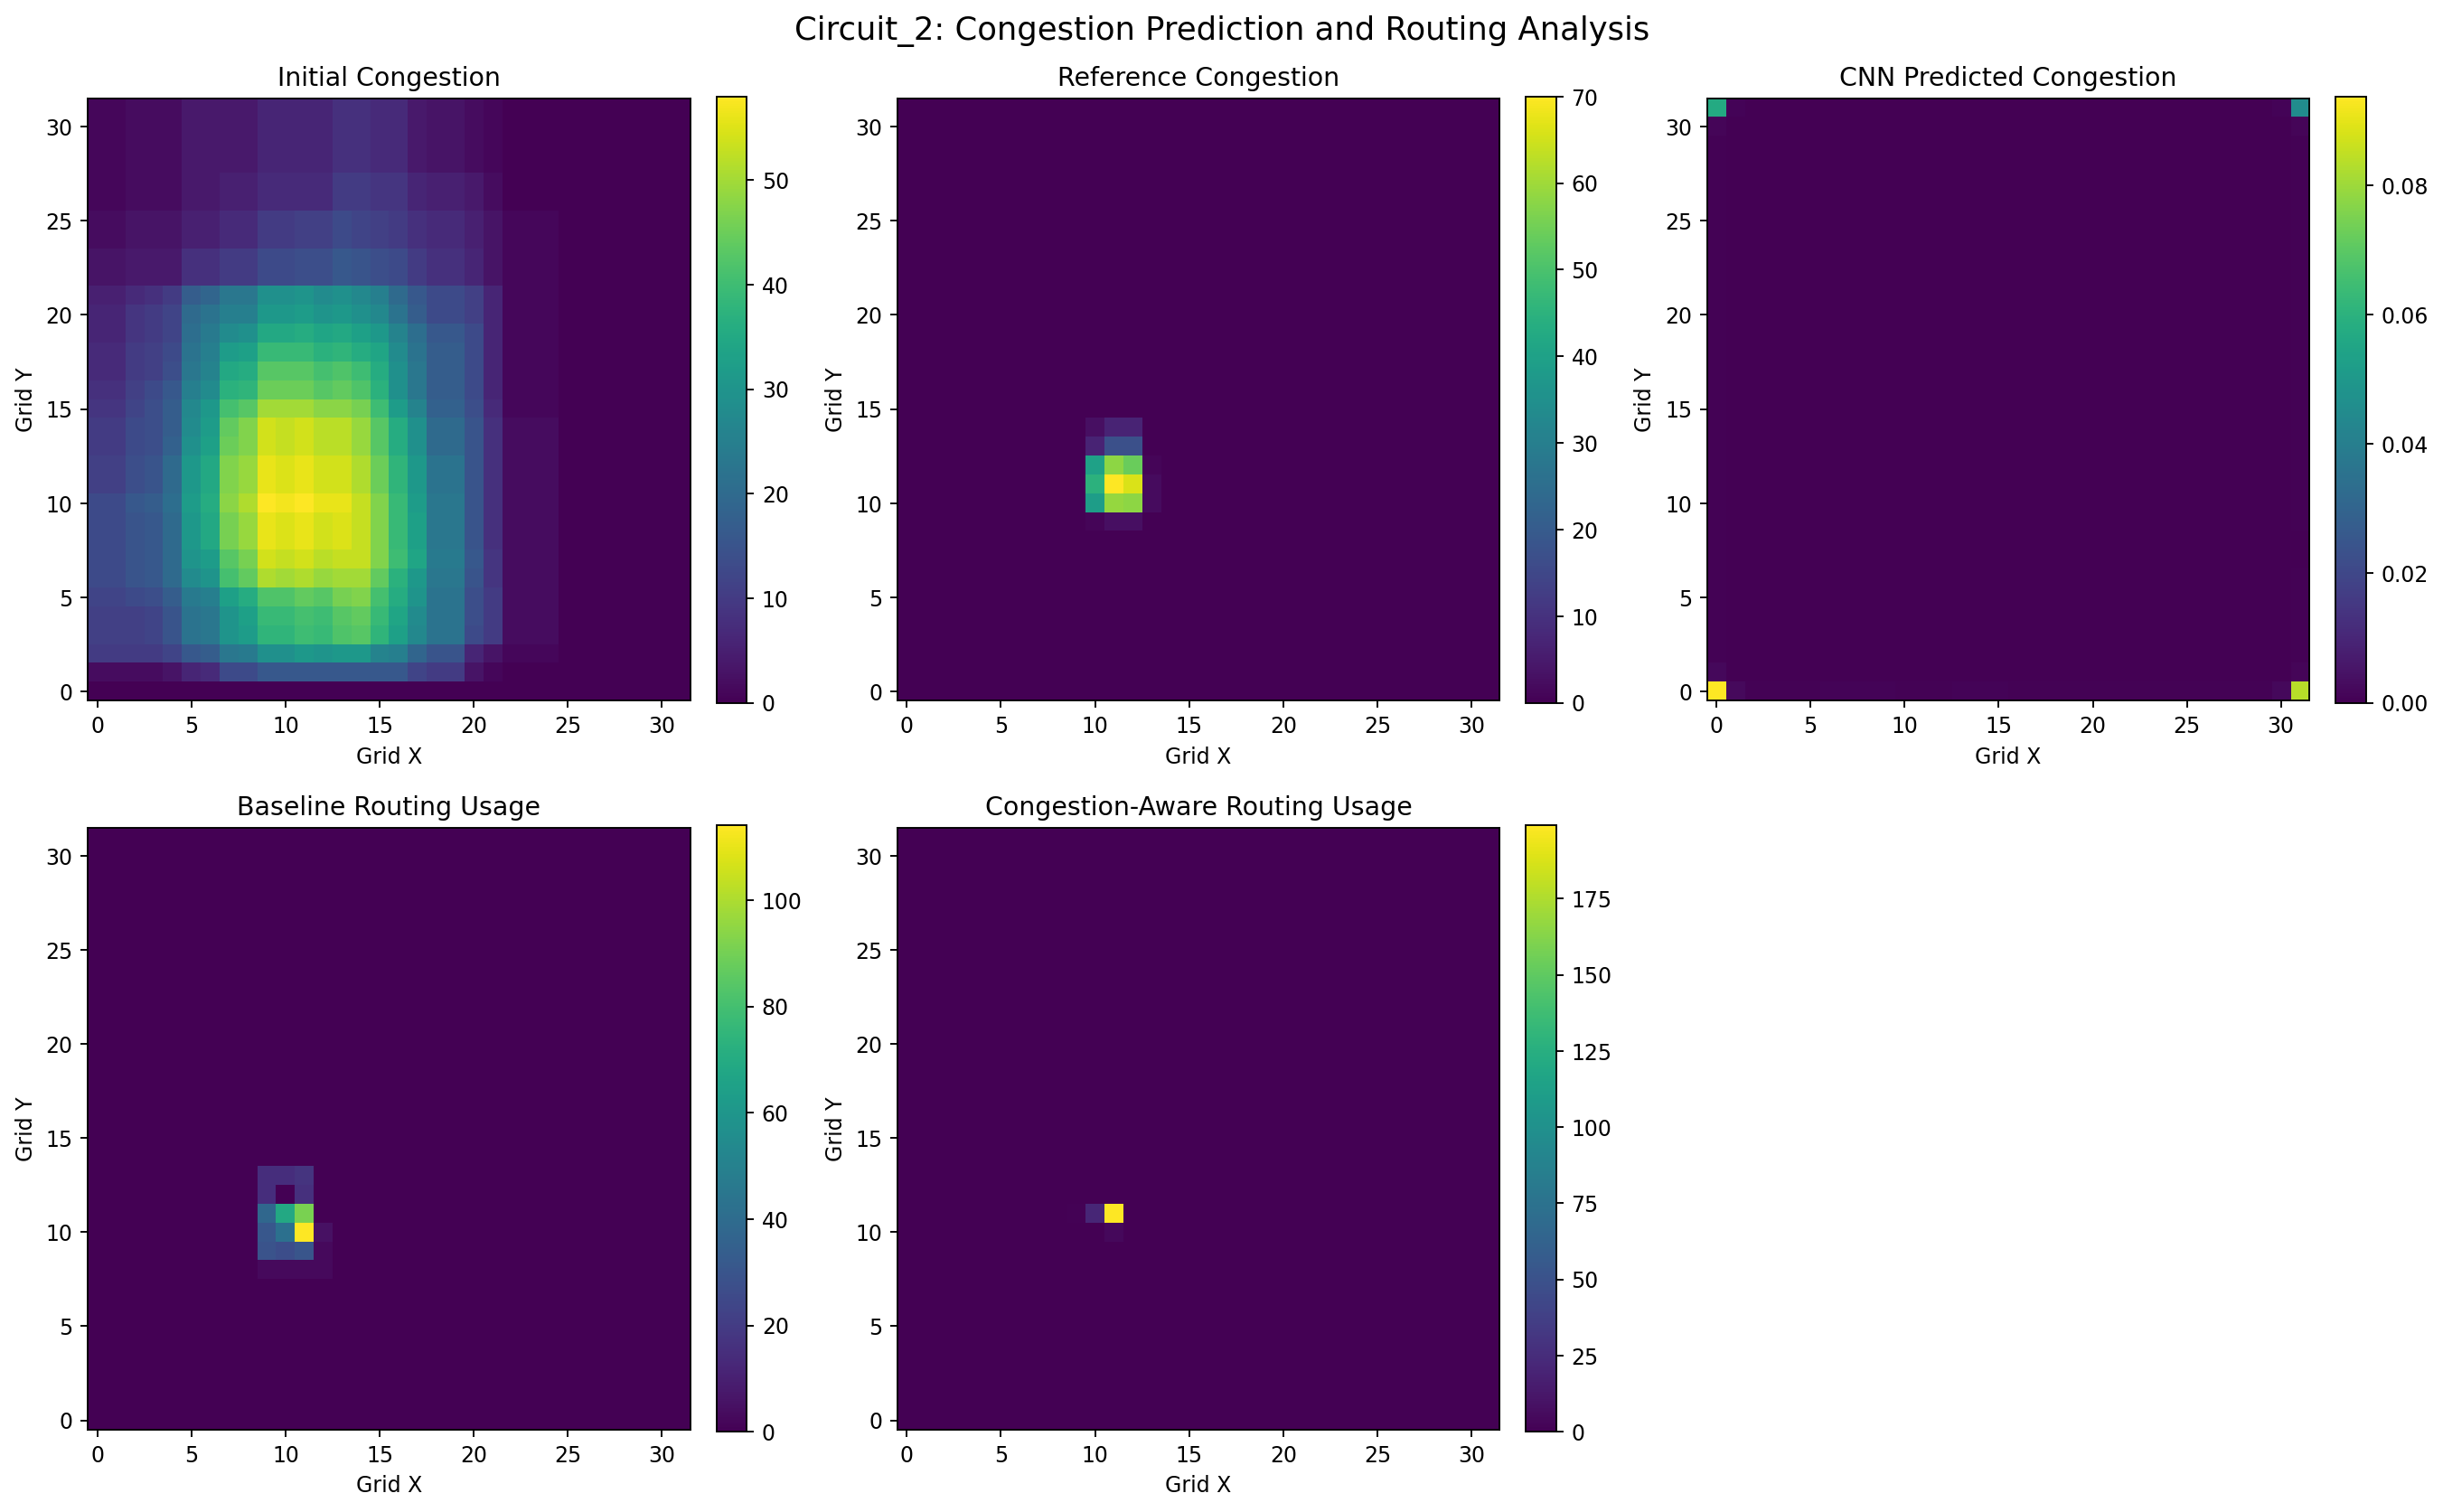

Five-panel congestion/routing figure: Circuit 3/5


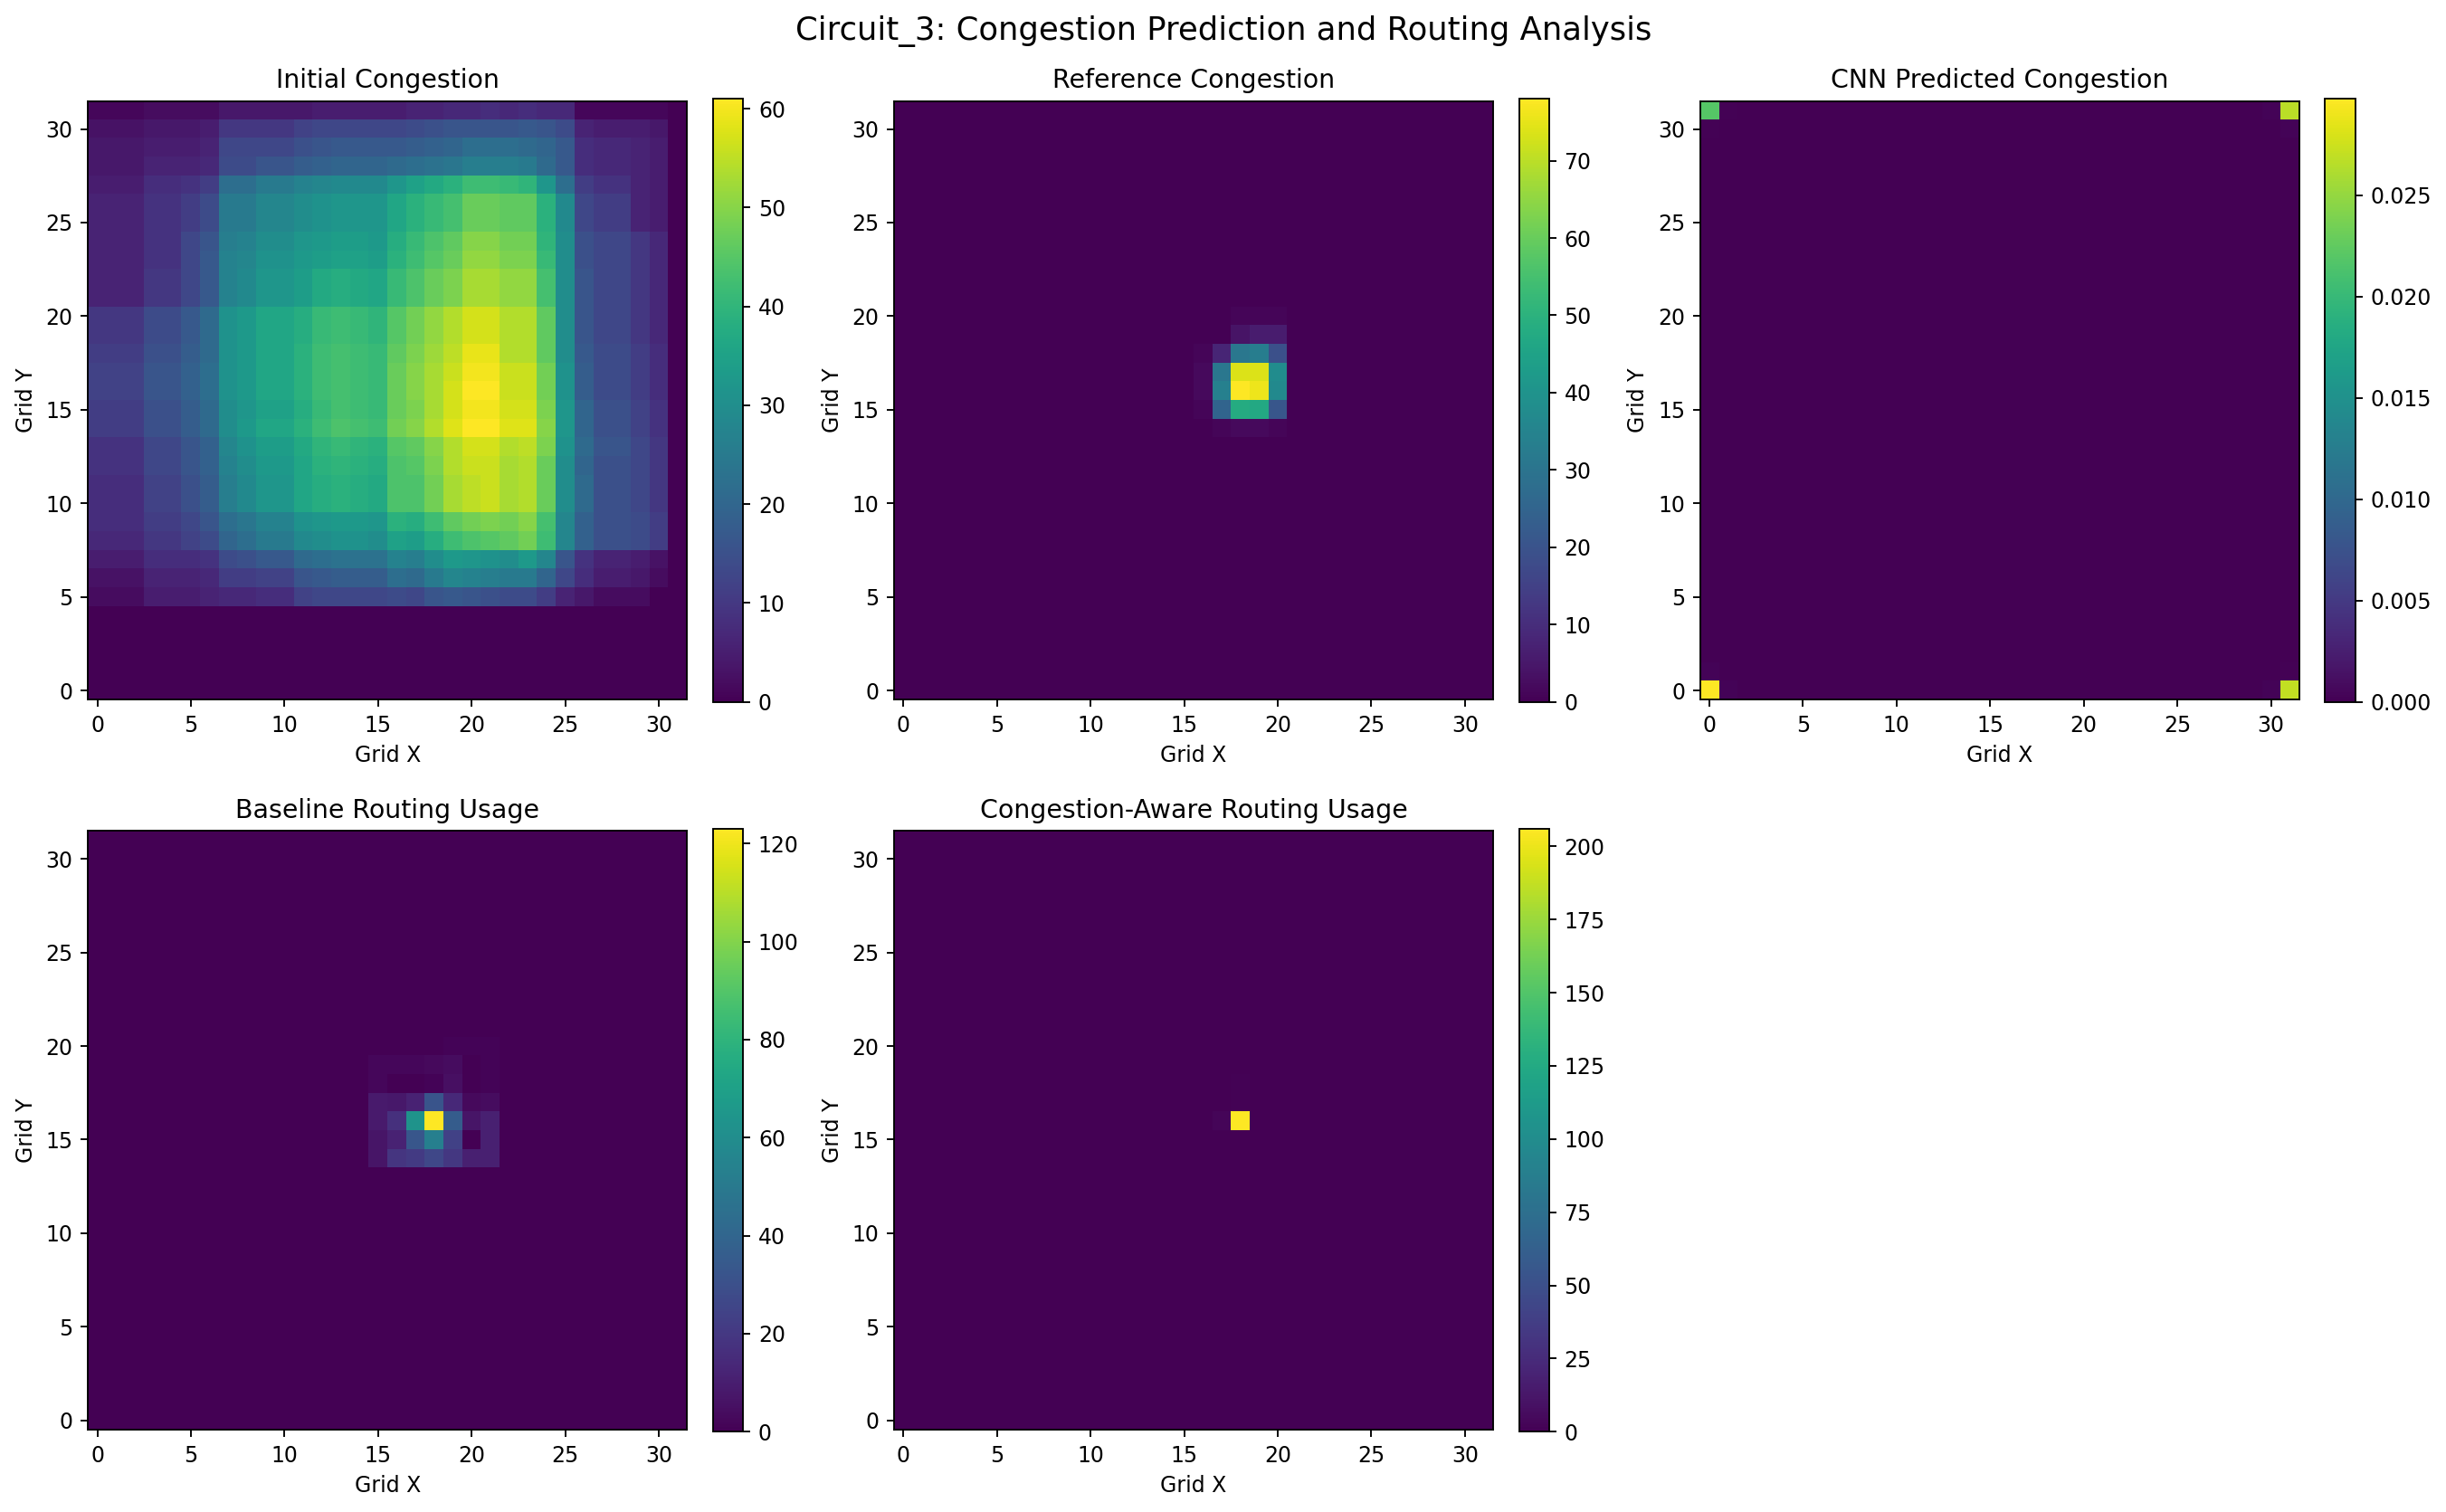

Five-panel congestion/routing figure: Circuit 4/5


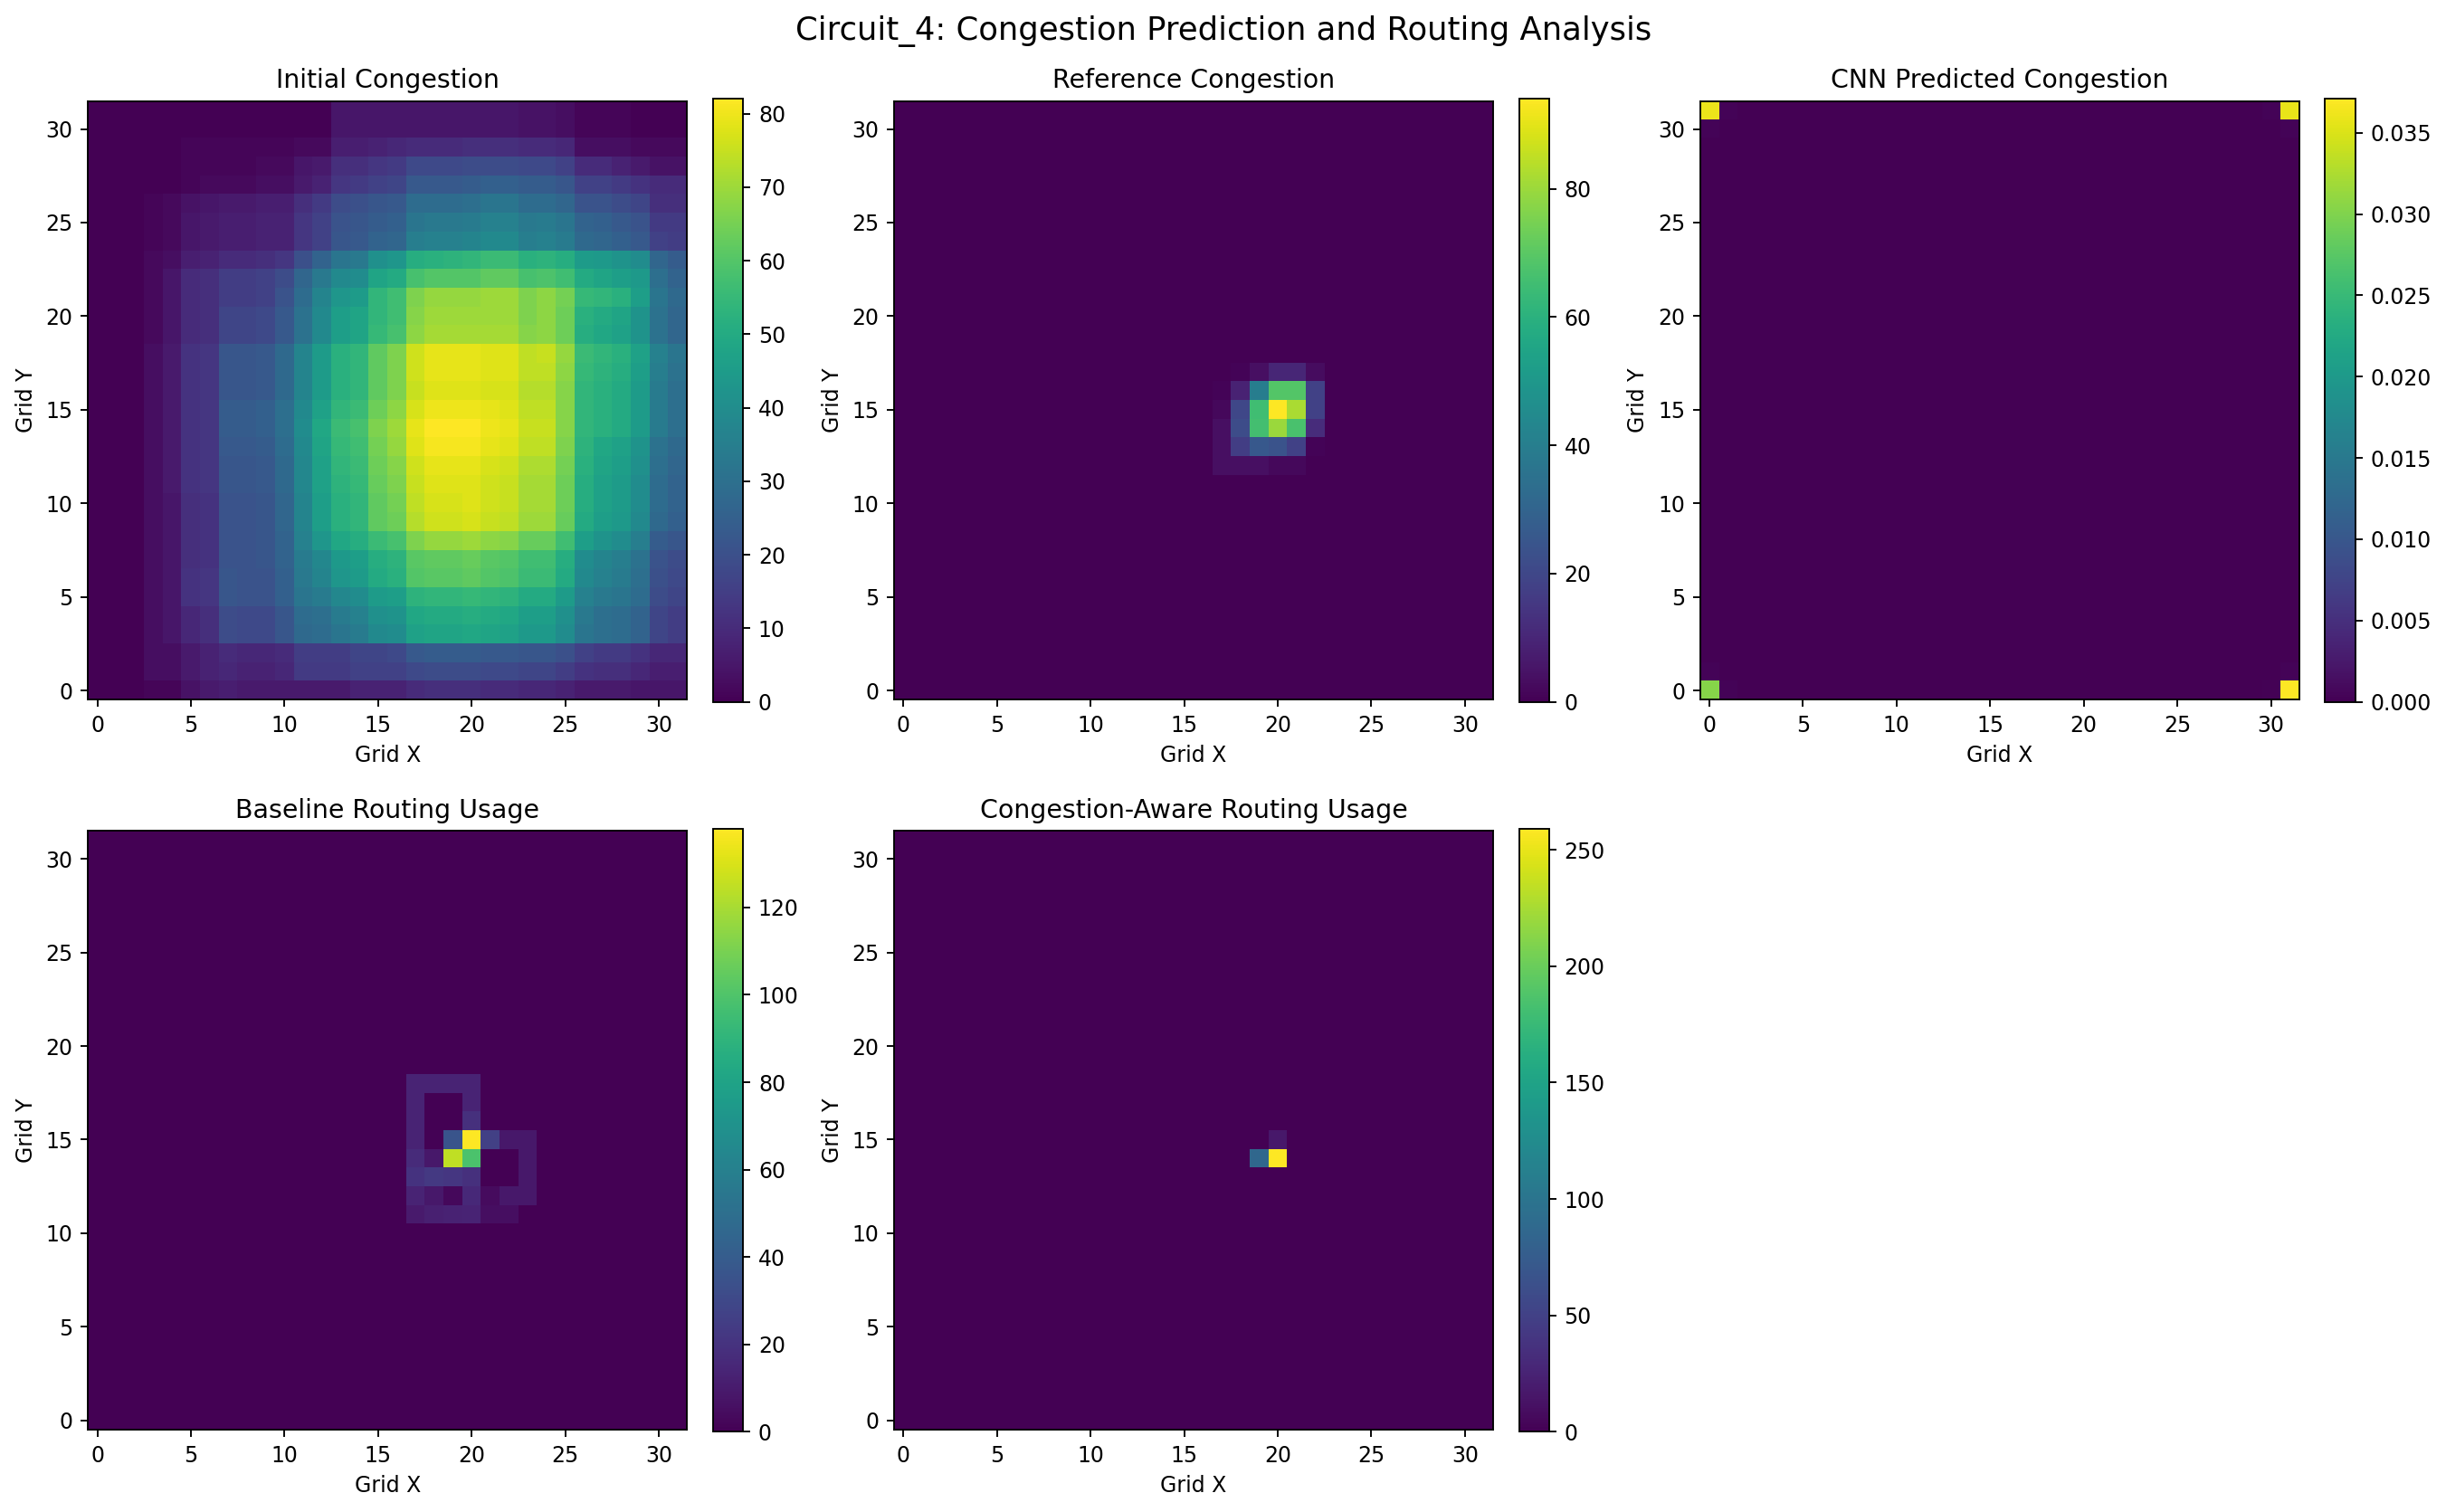

Five-panel congestion/routing figure: Circuit 5/5


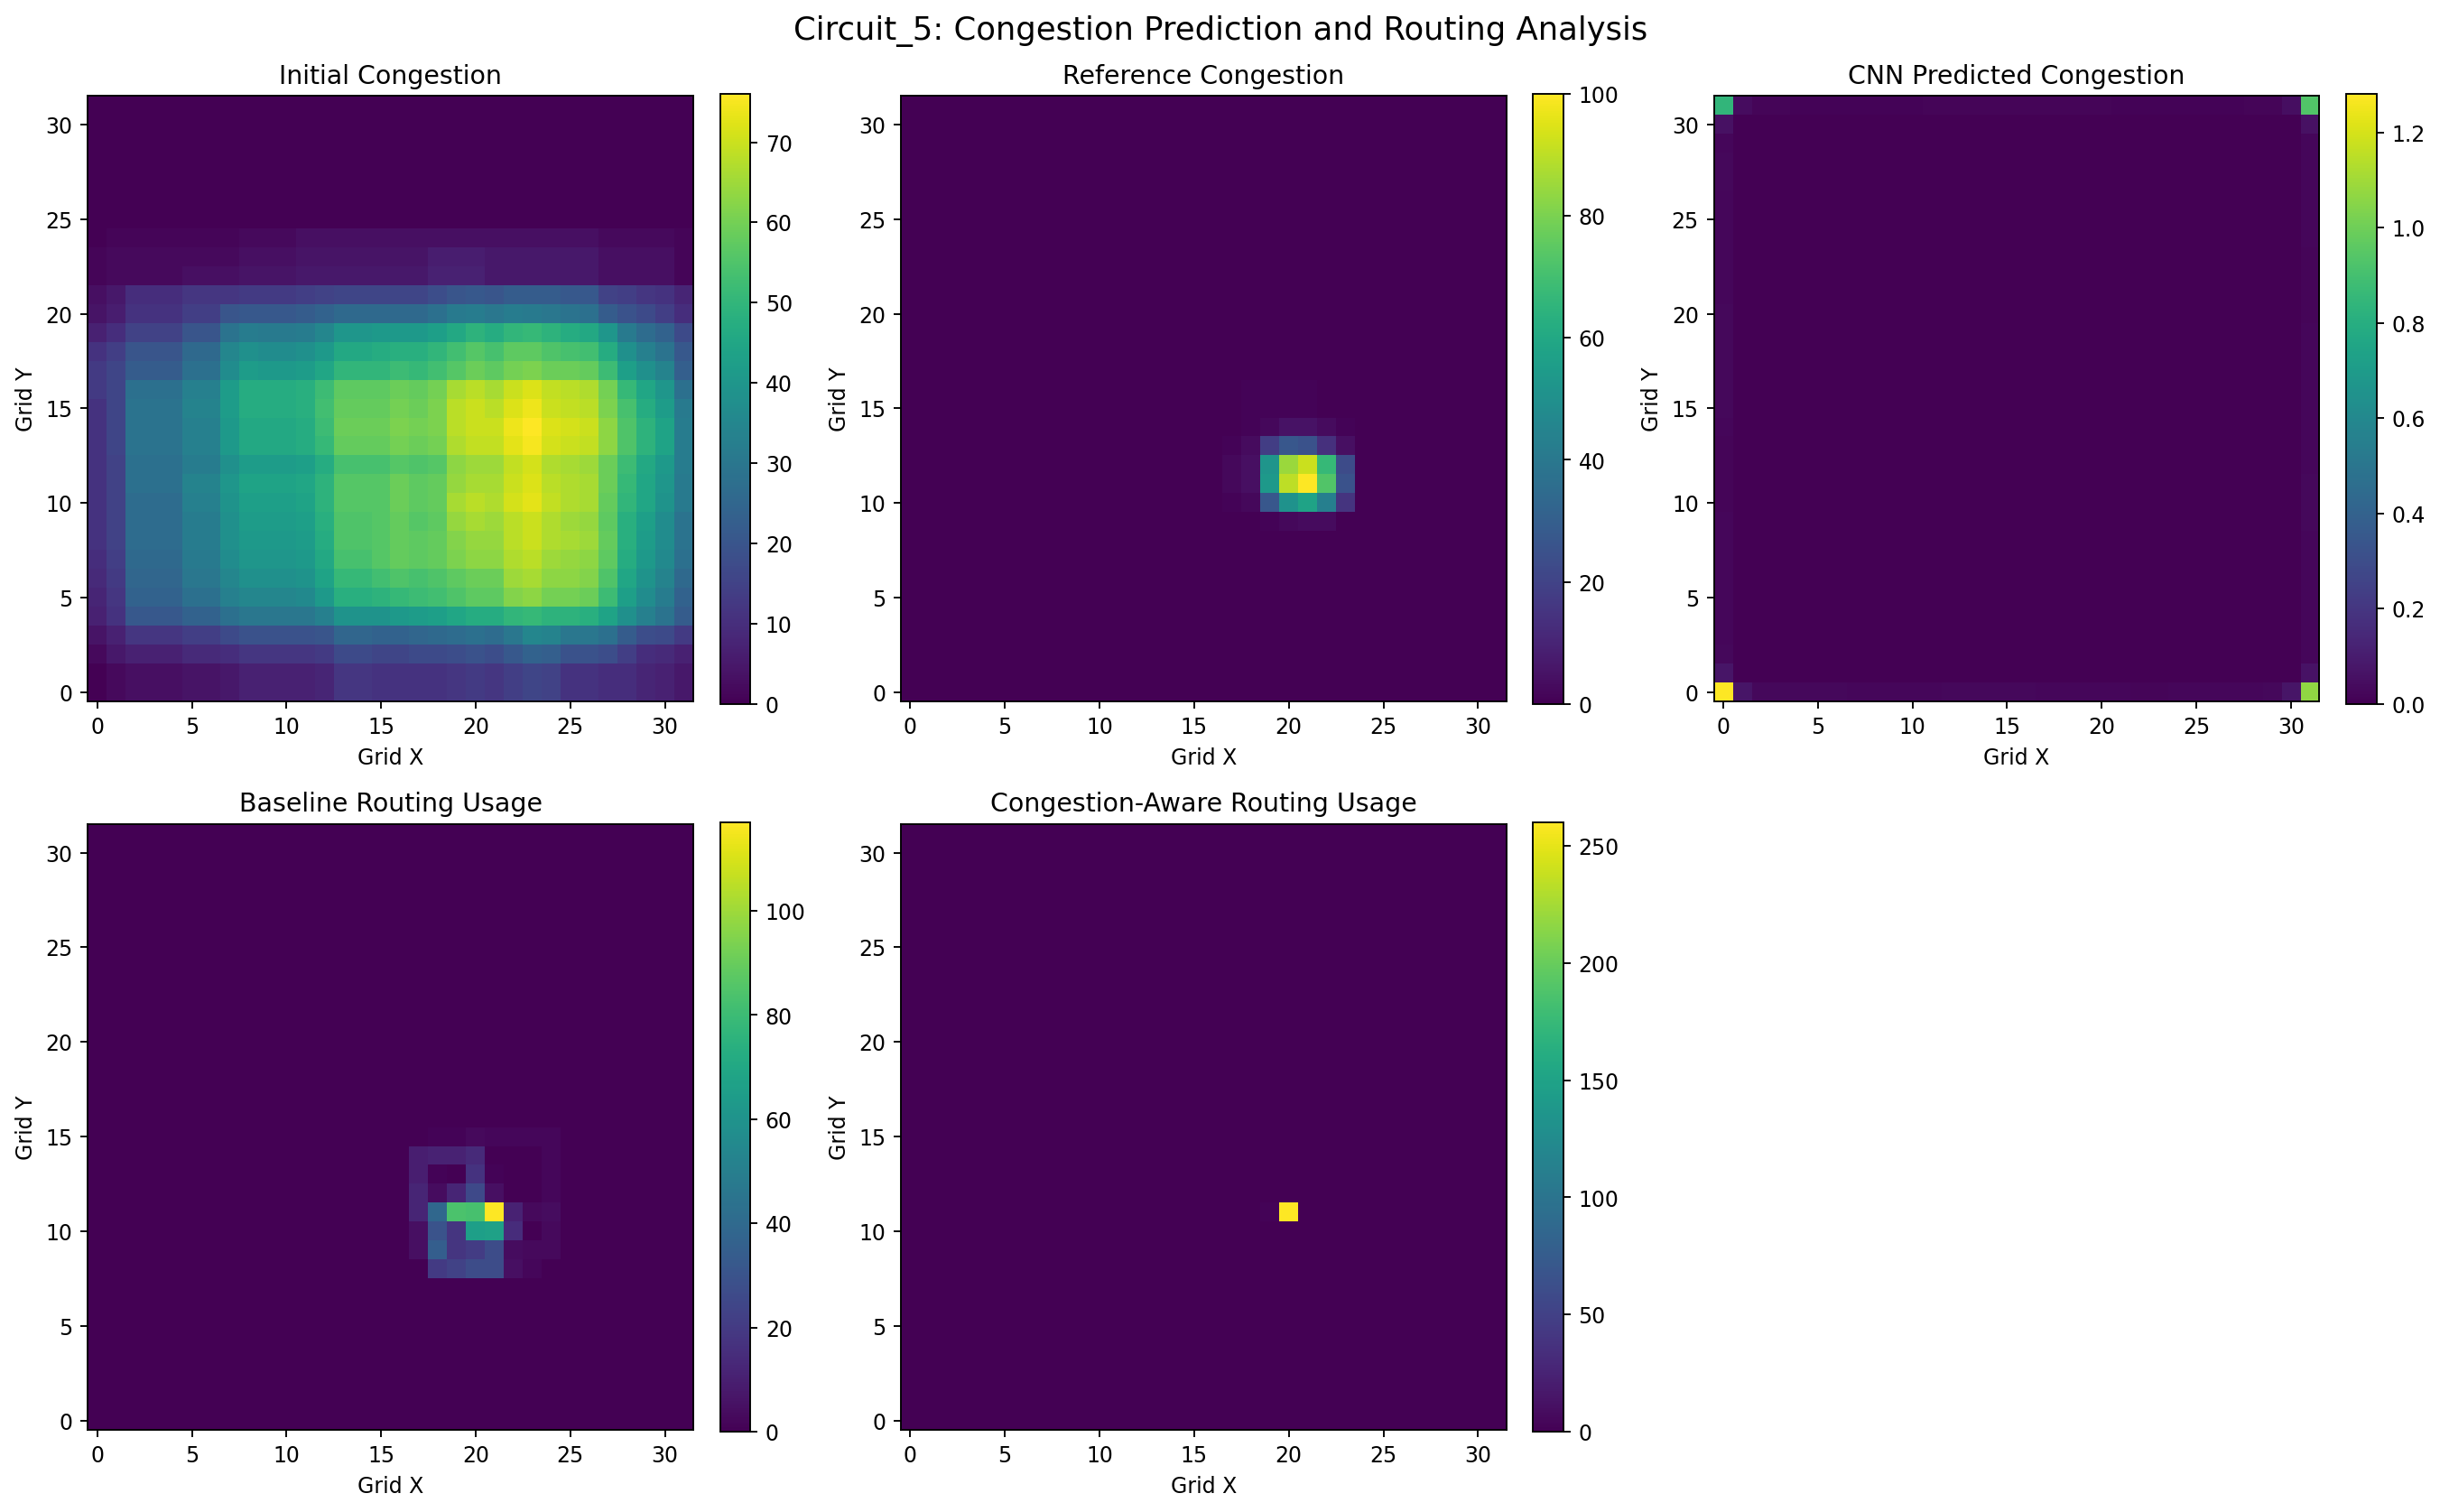

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


NOTE: Results are synthetic prototype measurements. For research claims,
run a validated physical-design flow on real benchmarks (e.g. ISPD/Bookshelf)
and report measured results without fabricating accuracy or improvement.


In [ ]:
# ================================================================
# HeteroDiffRoute-Net: COMPLETE FIVE-CIRCUIT GOOGLE COLAB PROTOTYPE
# Run this entire file in ONE Colab cell (or upload and run as .py).
#
# Includes:
# 1. Five synthetic circuits processed in one execution
# 2. Heterogeneous circuit graph (cells, nets and pin relationships)
# 3. Graph-Transformer-inspired placement predictor
# 4. Diffusion-inspired iterative coordinate refinement
# 5. CNN congestion prediction
# 6. A* grid routing
# 7. Baseline vs proposed-method evaluation
# 8. Metrics, tables, plots, CSV files and ZIP download
#
# IMPORTANT:
# This is a research prototype using reproducible synthetic circuits.
# It is NOT a validated implementation on real ISPD benchmarks and
# does not claim 99% accuracy or guaranteed physical-design improvement.
# ================================================================

import os, math, random, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# PyTorch is normally preinstalled in Google Colab.
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:
    raise ImportError("PyTorch is required. In Colab run: !pip install torch")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUTPUT_DIR = Path("HeteroDiffRouteNet_Results")
OUTPUT_DIR.mkdir(exist_ok=True)

NUM_CIRCUITS = 5
GRID_SIZE = 32
EPOCHS = 45
LEARNING_RATE = 0.003

print("HeteroDiffRoute-Net complete experiment")
print("Device:", DEVICE)
print("Circuits to process:", NUM_CIRCUITS)


# -------------------------- Circuit generator --------------------------
def generate_circuit(circuit_id, n_cells=None, n_nets=None):
    """Create a reproducible synthetic placement/routing benchmark."""
    rng = np.random.default_rng(SEED + circuit_id * 101)
    if n_cells is None:
        n_cells = 35 + circuit_id * 10
    if n_nets is None:
        n_nets = 45 + circuit_id * 13

    # Clustered initial placement with some random spread.
    centers = rng.uniform(0.15, 0.85, size=(4, 2))
    cluster_ids = rng.integers(0, 4, size=n_cells)
    initial = centers[cluster_ids] + rng.normal(0, 0.13, size=(n_cells, 2))
    initial = np.clip(initial, 0.02, 0.98)

    # Each net connects 2-5 cells. Connectivity is stored as cell indices.
    nets = []
    for _ in range(n_nets):
        degree = int(rng.integers(2, min(6, n_cells + 1)))
        members = rng.choice(n_cells, size=degree, replace=False)
        nets.append(np.asarray(members, dtype=np.int64))

    # Create a compact target placement used only to train this synthetic demo.
    # It is generated from net-centroid attraction and a regularizing grid.
    target = initial.copy()
    for _ in range(18):
        accum = np.zeros_like(target)
        counts = np.zeros(n_cells)
        for net in nets:
            centroid = target[net].mean(axis=0)
            accum[net] += centroid
            counts[net] += 1
        connected = counts > 0
        target[connected] = (
            0.78 * target[connected]
            + 0.22 * accum[connected] / counts[connected, None]
        )
        target = np.clip(target, 0.025, 0.975)

    # Heterogeneous node features: normalized coordinates, degree,
    # cell type, and number of connected nets.
    degree = np.zeros(n_cells, dtype=np.float32)
    for net in nets:
        degree[net] += 1
    cell_type = rng.integers(0, 3, size=n_cells)
    features = np.column_stack([
        initial,
        degree / max(degree.max(), 1),
        cell_type / 2.0,
        np.ones(n_cells, dtype=np.float32)
    ]).astype(np.float32)

    adjacency = np.zeros((n_cells, n_cells), dtype=np.float32)
    for net in nets:
        adjacency[np.ix_(net, net)] += 1.0
    np.fill_diagonal(adjacency, 0)
    adjacency = (adjacency > 0).astype(np.float32)

    return {
        "name": f"Circuit_{circuit_id}",
        "initial": initial.astype(np.float32),
        "target": target.astype(np.float32),
        "nets": nets,
        "features": features,
        "adjacency": adjacency,
        "n_cells": n_cells,
        "n_nets": n_nets
    }


# -------------------------- Graph Transformer --------------------------
class GraphTransformer(nn.Module):
    """Small graph-attention model for cell-coordinate prediction."""
    def __init__(self, input_dim=5, hidden=64):
        super().__init__()
        self.input_layer = nn.Linear(input_dim, hidden)
        self.q = nn.Linear(hidden, hidden)
        self.k = nn.Linear(hidden, hidden)
        self.v = nn.Linear(hidden, hidden)
        self.out = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2),
            nn.Sigmoid()
        )

    def forward(self, x, adjacency):
        h = F.relu(self.input_layer(x))
        q, k, v = self.q(h), self.k(h), self.v(h)
        scores = torch.matmul(q, k.T) / math.sqrt(h.shape[-1])

        # Mask attention to graph neighbors while retaining self-information.
        mask = adjacency + torch.eye(adjacency.shape[0], device=adjacency.device)
        scores = scores.masked_fill(mask == 0, -1e9)
        attention = torch.softmax(scores, dim=-1)
        message = torch.matmul(attention, v)
        return self.out(h + message)


def train_graph_model(circuit):
    x = torch.tensor(circuit["features"], dtype=torch.float32, device=DEVICE)
    adj = torch.tensor(circuit["adjacency"], dtype=torch.float32, device=DEVICE)
    y = torch.tensor(circuit["target"], dtype=torch.float32, device=DEVICE)

    model = GraphTransformer().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()

    model.train()
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        pred = model(x, adj)
        loss = loss_fn(pred, y)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        prediction = model(x, adj).cpu().numpy()
    return model, prediction


# -------------------------- Placement refinement --------------------------
def diffusion_refinement(predicted, nets, steps=35):
    """Diffusion-inspired denoising/refinement with net attraction."""
    rng = np.random.default_rng(SEED + len(predicted))
    coords = np.clip(predicted + rng.normal(0, 0.035, predicted.shape), 0.01, 0.99)

    for step in range(steps):
        noise_scale = 0.018 * (1.0 - step / steps)
        updated = coords.copy()
        for net in nets:
            centroid = coords[net].mean(axis=0)
            updated[net] = 0.90 * updated[net] + 0.10 * centroid
        updated += rng.normal(0, noise_scale, updated.shape)
        coords = np.clip(updated, 0.01, 0.99)

    return coords


def force_directed_baseline(initial, nets, iterations=35):
    """Simple net-centroid baseline used for comparison."""
    coords = initial.copy()
    for _ in range(iterations):
        accum = np.zeros_like(coords)
        counts = np.zeros(len(coords), dtype=np.float32)
        for net in nets:
            centroid = coords[net].mean(axis=0)
            accum[net] += centroid
            counts[net] += 1
        mask = counts > 0
        coords[mask] = 0.88 * coords[mask] + 0.12 * accum[mask] / counts[mask, None]
        coords = np.clip(coords, 0.01, 0.99)
    return coords


# -------------------------- Physical-design metrics --------------------------
def hpwl(coords, nets):
    total = 0.0
    for net in nets:
        points = coords[net]
        total += np.ptp(points[:, 0]) + np.ptp(points[:, 1])
    return float(total)


def placement_displacement(coords, initial):
    return float(np.mean(np.linalg.norm(coords - initial, axis=1)))


def density_map(coords, grid=GRID_SIZE):
    heat = np.zeros((grid, grid), dtype=np.float32)
    ix = np.clip((coords[:, 0] * grid).astype(int), 0, grid - 1)
    iy = np.clip((coords[:, 1] * grid).astype(int), 0, grid - 1)
    for x, y in zip(ix, iy):
        heat[y, x] += 1.0
    return heat


def routing_demand_map(coords, nets, grid=GRID_SIZE):
    """Rasterize horizontal/vertical net bounding-box demand."""
    demand = np.zeros((grid, grid), dtype=np.float32)
    for net in nets:
        pts = coords[net]
        x0 = max(0, min(grid - 1, int(np.floor(pts[:, 0].min() * grid))))
        x1 = max(0, min(grid - 1, int(np.ceil(pts[:, 0].max() * grid))))
        y0 = max(0, min(grid - 1, int(np.floor(pts[:, 1].min() * grid))))
        y1 = max(0, min(grid - 1, int(np.ceil(pts[:, 1].max() * grid))))
        demand[y0:y1 + 1, x0:x1 + 1] += 1.0
    return demand


# -------------------------- CNN congestion prediction --------------------------
class CongestionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 24, 3, padding=1), nn.ReLU(),
            nn.Conv2d(24, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 1, 1), nn.Softplus()
        )

    def forward(self, x):
        return self.net(x)


def predict_congestion(true_demand):
    """Train a small CNN on the circuit demand map as a denoising proxy."""
    max_value = max(float(true_demand.max()), 1.0)
    normalized = true_demand / max_value
    rng = np.random.default_rng(SEED + int(true_demand.sum()))
    noisy = np.clip(normalized + rng.normal(0, 0.035, normalized.shape), 0, None)

    x = torch.tensor(noisy[None, None], dtype=torch.float32, device=DEVICE)
    y = torch.tensor(normalized[None, None], dtype=torch.float32, device=DEVICE)
    model = CongestionCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.006)
    loss_fn = nn.MSELoss()

    model.train()
    for _ in range(35):
        optimizer.zero_grad()
        prediction = model(x)
        loss = loss_fn(prediction, y)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        prediction = model(x).cpu().numpy()[0, 0]
    prediction = np.maximum(prediction, 0) * max_value

    # Metrics are computed directly with NumPy; no sklearn dependency.
    mse = float(np.mean((true_demand.flatten() - prediction.flatten()) ** 2))
    mae = float(np.mean(np.abs(true_demand.flatten() - prediction.flatten())))
    if np.std(true_demand) == 0 or np.std(prediction) == 0:
        correlation = 0.0
    else:
        correlation = float(np.corrcoef(true_demand.flatten(), prediction.flatten())[0, 1])
    return prediction.astype(np.float32), mse, mae, correlation


# -------------------------- A* global-routing proxy --------------------------
def astar_route(cost_map, start, goal):
    """A* route on a 2D grid; returns path and path cost."""
    import heapq
    rows, cols = cost_map.shape
    start = (int(np.clip(start[0], 0, rows-1)), int(np.clip(start[1], 0, cols-1)))
    goal = (int(np.clip(goal[0], 0, rows-1)), int(np.clip(goal[1], 0, cols-1)))
    queue = [(0.0, start)]
    came_from = {}
    g_score = {start: 0.0}
    visited = set()

    while queue:
        _, current = heapq.heappop(queue)
        if current in visited:
            continue
        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            path.reverse()
            return path, g_score[goal]

        visited.add(current)
        r, c = current
        for nr, nc in ((r-1,c), (r+1,c), (r,c-1), (r,c+1)):
            if not (0 <= nr < rows and 0 <= nc < cols):
                continue
            nxt = (nr, nc)
            step_cost = 1.0 + float(cost_map[nr, nc])
            tentative = g_score[current] + step_cost
            if tentative < g_score.get(nxt, float("inf")):
                came_from[nxt] = current
                g_score[nxt] = tentative
                heuristic = abs(nr-goal[0]) + abs(nc-goal[1])
                heapq.heappush(queue, (tentative + heuristic, nxt))
    return [], float("inf")


def paths_to_usage_map(paths, grid=GRID_SIZE):
    """Convert A* paths into a grid map showing how often each cell is used."""
    usage = np.zeros((grid, grid), dtype=np.float32)
    for path in paths:
        for row, col in path:
            if 0 <= row < grid and 0 <= col < grid:
                usage[row, col] += 1.0
    return usage


def route_circuit(coords, nets, congestion_map):
    """Route each net as a set of two-pin connections to its first pin."""
    paths = []
    total_cost = 0.0
    overflow = 0.0
    capacity = max(1.0, float(np.percentile(congestion_map, 75)))
    routing_cost_map = congestion_map / capacity

    for net in nets:
        if len(net) < 2:
            continue
        root = coords[net[0]]
        start = (int(root[1] * GRID_SIZE), int(root[0] * GRID_SIZE))
        for cell in net[1:]:
            point = coords[cell]
            goal = (int(point[1] * GRID_SIZE), int(point[0] * GRID_SIZE))
            path, cost = astar_route(routing_cost_map, start, goal)
            if path:
                paths.append(path)
                total_cost += cost
    overflow = float(np.maximum(congestion_map - capacity, 0).sum())
    return paths, float(total_cost), overflow


# -------------------------- Plotting --------------------------
def save_placement_plot(circuit, baseline, proposed, circuit_dir):
    plt.figure(figsize=(7, 6))
    plt.scatter(baseline[:, 0], baseline[:, 1], s=22, alpha=0.65, label="Baseline")
    plt.scatter(proposed[:, 0], proposed[:, 1], s=22, alpha=0.65, label="Proposed")
    plt.title(f'{circuit["name"]}: Placement comparison')
    plt.xlabel("Normalized X"); plt.ylabel("Normalized Y")
    plt.xlim(0, 1); plt.ylim(0, 1); plt.grid(alpha=0.2); plt.legend()
    plt.tight_layout()
    plt.savefig(circuit_dir / "placement_comparison.png", dpi=150)
    plt.close()


def save_heatmaps(true_map, predicted_map, circuit_dir, name):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(true_map, origin="lower")
    axes[0].set_title("Routing demand")
    axes[1].imshow(predicted_map, origin="lower")
    axes[1].set_title("CNN predicted congestion")
    for ax in axes: ax.set_xlabel("Grid X"); ax.set_ylabel("Grid Y")
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(circuit_dir / "congestion_heatmaps.png", dpi=150)
    plt.close(fig)


def save_reference_style_figure(initial_map, reference_map, predicted_map,
                                baseline_usage, congestion_aware_usage,
                                circuit_dir, name):
    """Create the five-panel congestion/routing figure shown by the user."""
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    panels = [
        (initial_map, "Initial Congestion"),
        (reference_map, "Reference Congestion"),
        (predicted_map, "CNN Predicted Congestion"),
        (baseline_usage, "Baseline Routing Usage"),
        (congestion_aware_usage, "Congestion-Aware Routing Usage")
    ]
    for ax, (data, title) in zip(axes.flat, panels):
        im = ax.imshow(data, origin="lower", interpolation="nearest", cmap="viridis")
        ax.set_title(title, fontsize=12)
        ax.set_xlabel("Grid X")
        ax.set_ylabel("Grid Y")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Hide the unused sixth panel to retain the same five-chart layout.
    axes.flat[5].axis("off")
    fig.suptitle(f"{name}: Congestion Prediction and Routing Analysis", fontsize=15)
    fig.tight_layout()
    fig.savefig(circuit_dir / "five_panel_congestion_routing.png",
                dpi=170, bbox_inches="tight")
    plt.close(fig)


def save_routing_plot(paths, circuit_dir, name):
    plt.figure(figsize=(6, 6))
    for path in paths:
        arr = np.asarray(path)
        if len(arr):
            plt.plot(arr[:, 1], arr[:, 0], linewidth=0.7, alpha=0.6)
    plt.xlim(0, GRID_SIZE-1); plt.ylim(0, GRID_SIZE-1)
    plt.title(f"{name}: A* routing paths")
    plt.xlabel("Grid X"); plt.ylabel("Grid Y"); plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(circuit_dir / "routing_paths.png", dpi=150)
    plt.close()


# -------------------------- Main experiment: ALL FIVE CIRCUITS --------------------------
all_results = []
all_loss_notes = []

for circuit_number in range(1, NUM_CIRCUITS + 1):
    print(f"\n{'='*65}")
    print(f"Processing Circuit {circuit_number}/{NUM_CIRCUITS}")
    print(f"{'='*65}")

    circuit = generate_circuit(circuit_number)
    circuit_dir = OUTPUT_DIR / circuit["name"]
    circuit_dir.mkdir(exist_ok=True)

    initial = circuit["initial"]
    nets = circuit["nets"]

    # Baseline placement and proposed graph-transformer + diffusion placement.
    baseline = force_directed_baseline(initial, nets)
    graph_model, graph_prediction = train_graph_model(circuit)
    proposed = diffusion_refinement(graph_prediction, nets)

    # Congestion maps: initial placement, reference target placement,
    # and proposed placement (used as the CNN prediction target).
    initial_demand = routing_demand_map(initial, nets)
    reference_demand = routing_demand_map(circuit["target"], nets)
    true_demand = routing_demand_map(proposed, nets)
    predicted_congestion, mse, mae, corr = predict_congestion(true_demand)

    # Baseline and proposed global-routing proxy.
    baseline_demand = routing_demand_map(baseline, nets)
    baseline_paths, baseline_route_cost, baseline_overflow = route_circuit(
        baseline, nets, baseline_demand
    )
    proposed_paths, proposed_route_cost, proposed_overflow = route_circuit(
        proposed, nets, predicted_congestion
    )
    baseline_usage_map = paths_to_usage_map(baseline_paths)
    congestion_aware_usage_map = paths_to_usage_map(proposed_paths)

    result = {
        "Circuit": circuit["name"],
        "Cells": circuit["n_cells"],
        "Nets": circuit["n_nets"],
        "Baseline_HPWL": hpwl(baseline, nets),
        "Proposed_HPWL": hpwl(proposed, nets),
        "Baseline_Displacement": placement_displacement(baseline, initial),
        "Proposed_Displacement": placement_displacement(proposed, initial),
        "Congestion_MSE": mse,
        "Congestion_MAE": mae,
        "Congestion_Correlation": corr,
        "Baseline_Routing_Cost": baseline_route_cost,
        "Proposed_Routing_Cost": proposed_route_cost,
        "Baseline_Overflow": baseline_overflow,
        "Proposed_Overflow": proposed_overflow,
        "Baseline_Routed_Connections": len(baseline_paths),
        "Proposed_Routed_Connections": len(proposed_paths)
    }
    all_results.append(result)

    # Save per-circuit data and visuals.
    pd.DataFrame([result]).to_csv(circuit_dir / "metrics.csv", index=False)
    save_placement_plot(circuit, baseline, proposed, circuit_dir)
    save_heatmaps(true_demand, predicted_congestion, circuit_dir, circuit["name"])
    save_routing_plot(proposed_paths, circuit_dir, circuit["name"])
    save_reference_style_figure(
        initial_demand, reference_demand, predicted_congestion,
        baseline_usage_map, congestion_aware_usage_map,
        circuit_dir, circuit["name"]
    )
    np.save(circuit_dir / "initial_congestion.npy", initial_demand)
    np.save(circuit_dir / "reference_congestion.npy", reference_demand)
    np.save(circuit_dir / "baseline_routing_usage.npy", baseline_usage_map)
    np.save(circuit_dir / "congestion_aware_routing_usage.npy", congestion_aware_usage_map)
    np.save(circuit_dir / "baseline_placement.npy", baseline)
    np.save(circuit_dir / "proposed_placement.npy", proposed)
    np.save(circuit_dir / "true_routing_demand.npy", true_demand)
    np.save(circuit_dir / "predicted_congestion.npy", predicted_congestion)

    print("Cells:", circuit["n_cells"], "| Nets:", circuit["n_nets"])
    print(f"HPWL: baseline={result['Baseline_HPWL']:.4f}, proposed={result['Proposed_HPWL']:.4f}")
    print(f"Congestion: MSE={mse:.6f}, MAE={mae:.6f}, correlation={corr:.4f}")
    print(f"Routing cost: baseline={baseline_route_cost:.2f}, proposed={proposed_route_cost:.2f}")
    print(f"Overflow: baseline={baseline_overflow:.2f}, proposed={proposed_overflow:.2f}")
    print("Completed:", circuit["name"])


# -------------------------- Combined results and comparison plots --------------------------
results_df = pd.DataFrame(all_results)
results_path = OUTPUT_DIR / "all_circuits_results.csv"
results_df.to_csv(results_path, index=False)

print("\n\n================ ALL-CIRCUIT RESULTS ================")
try:
    from IPython.display import display
    display(results_df.round(4))
except Exception:
    print(results_df.round(4).to_string(index=False))

metric_pairs = [
    ("Baseline_HPWL", "Proposed_HPWL", "HPWL"),
    ("Baseline_Displacement", "Proposed_Displacement", "Placement displacement"),
    ("Baseline_Routing_Cost", "Proposed_Routing_Cost", "Routing cost"),
    ("Baseline_Overflow", "Proposed_Overflow", "Routing overflow")
]

for baseline_col, proposed_col, title in metric_pairs:
    x = np.arange(len(results_df))
    width = 0.36
    plt.figure(figsize=(9, 4.5))
    plt.bar(x - width/2, results_df[baseline_col], width, label="Baseline")
    plt.bar(x + width/2, results_df[proposed_col], width, label="Proposed")
    plt.xticks(x, results_df["Circuit"])
    plt.ylabel(title); plt.title(f"All circuits: {title} comparison")
    plt.legend(); plt.grid(axis="y", alpha=0.2); plt.tight_layout()
    filename = title.lower().replace(" ", "_") + "_all_circuits.png"
    plt.savefig(OUTPUT_DIR / filename, dpi=150)
    plt.show()
    plt.close()

# Congestion prediction metrics across all circuits.
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(results_df))
ax.bar(x - 0.18, results_df["Congestion_MSE"], 0.36, label="MSE")
ax.bar(x + 0.18, results_df["Congestion_MAE"], 0.36, label="MAE")
ax.set_xticks(x); ax.set_xticklabels(results_df["Circuit"])
ax.set_title("Congestion prediction error across all circuits")
ax.set_ylabel("Error"); ax.legend(); ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "congestion_errors_all_circuits.png", dpi=150)
plt.show()
plt.close(fig)

# Relative change: negative is an improvement for these cost metrics.
summary_rows = []
for metric, label in [
    ("HPWL", "HPWL"),
    ("Displacement", "Placement displacement"),
    ("Routing_Cost", "Routing cost"),
    ("Overflow", "Routing overflow")
]:
    b = results_df[f"Baseline_{metric}"].to_numpy(dtype=float)
    p = results_df[f"Proposed_{metric}"].to_numpy(dtype=float)
    improvement = np.where(np.abs(b) > 1e-12, (b - p) / np.abs(b) * 100.0, 0.0)
    summary_rows.append({
        "Metric": label,
        "Average_Baseline": float(np.mean(b)),
        "Average_Proposed": float(np.mean(p)),
        "Average_Improvement_Percent": float(np.mean(improvement))
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUTPUT_DIR / "average_comparison_summary.csv", index=False)

print("\n================ AVERAGE COMPARISON ================")
try:
    display(summary_df.round(4))
except Exception:
    print(summary_df.round(4).to_string(index=False))

# Package every result into one ZIP archive.
zip_path = Path("HeteroDiffRouteNet_All_5_Circuits_Results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for file in OUTPUT_DIR.rglob("*"):
        if file.is_file():
            archive.write(file, file.relative_to(OUTPUT_DIR.parent))

print("\nExperiment completed for all five circuits.")
print("Results folder:", OUTPUT_DIR.resolve())
print("Combined metrics:", results_path.resolve())
print("ZIP archive:", zip_path.resolve())

# Copy the user's uploaded reference figure into the result bundle when available.
reference_image = Path("/mnt/data/image.png")
if reference_image.exists():
    import shutil
    shutil.copy2(reference_image, OUTPUT_DIR / "user_reference_figure.png")
    print("Included uploaded reference image in results:", OUTPUT_DIR / "user_reference_figure.png")

# Display the five-panel result for each circuit in Google Colab.
try:
    from IPython.display import display, Image as IPyImage
    for circuit_number in range(1, NUM_CIRCUITS + 1):
        figure_path = OUTPUT_DIR / f"Circuit_{circuit_number}" / "five_panel_congestion_routing.png"
        if figure_path.exists():
            print(f"Five-panel congestion/routing figure: Circuit {circuit_number}/5")
            display(IPyImage(filename=str(figure_path)))
except Exception:
    pass

# Automatically offer downloads in Google Colab.
try:
    from google.colab import files
    files.download(str(zip_path))
    files.download(str(results_path))
except Exception:
    print("Outside Colab: retrieve the ZIP and CSV from the current working directory.")

print("\nNOTE: Results are synthetic prototype measurements. For research claims,")
print("run a validated physical-design flow on real benchmarks (e.g. ISPD/Bookshelf)")
print("and report measured results without fabricating accuracy or improvement.")


HETERODIFFROUTE-NET
Device: cpu

Configuration loaded successfully.

Generating synthetic training circuits...
Training circuits: 120
Node feature shape: (120, 24, 8)
Adjacency shape: (120, 24, 24)
Target placement shape: (120, 24, 2)

Training Graph Transformer...
Epoch 01/25 | Loss: 0.051183
Epoch 02/25 | Loss: 0.024538
Epoch 03/25 | Loss: 0.014987
Epoch 04/25 | Loss: 0.013408
Epoch 05/25 | Loss: 0.012508
Epoch 06/25 | Loss: 0.011836
Epoch 07/25 | Loss: 0.011469
Epoch 08/25 | Loss: 0.011502
Epoch 09/25 | Loss: 0.011355
Epoch 10/25 | Loss: 0.011308
Epoch 11/25 | Loss: 0.011479
Epoch 12/25 | Loss: 0.011138
Epoch 13/25 | Loss: 0.011242
Epoch 14/25 | Loss: 0.011252
Epoch 15/25 | Loss: 0.010961
Epoch 16/25 | Loss: 0.010815
Epoch 17/25 | Loss: 0.011007
Epoch 18/25 | Loss: 0.010937
Epoch 19/25 | Loss: 0.010795
Epoch 20/25 | Loss: 0.010895
Epoch 21/25 | Loss: 0.010851
Epoch 22/25 | Loss: 0.010810
Epoch 23/25 | Loss: 0.010762
Epoch 24/25 | Loss: 0.010763
Epoch 25/25 | Loss: 0.010556

Generati

,Circuit,Baseline HPWL,Proposed HPWL,Placement MAE,Average Displacement,Baseline Density Peak,Proposed Density Peak,Congestion MSE,Congestion MAE,Congestion Correlation,Baseline Wirelength,Proposed Wirelength,Baseline Overflow,Proposed Overflow,Successful Routes
0,Circuit 1,20.7891,17.3702,0.0858,0.0614,4.0,2.0,1.7369,0.8208,0.3578,641.0,547.0,181.0,174.0,36
1,Circuit 2,26.0351,22.1570,0.0731,0.0653,2.0,2.0,1.8370,0.8786,0.3925,811.0,685.0,282.0,296.0,36
2,Circuit 3,19.7858,16.3451,0.0843,0.0666,2.0,3.0,1.7014,0.7502,0.4232,606.0,507.0,167.0,159.0,36
3,Circuit 4,21.8435,18.4607,0.0937,0.0479,2.0,4.0,2.0041,0.8164,0.3639,682.0,572.0,221.0,225.0,36
4,Circuit 5,20.2109,17.3143,0.0908,0.0595,2.0,3.0,1.0663,0.6873,0.4685,626.0,538.0,154.0,132.0,36



AVERAGE PERFORMANCE


,Metric,Average Value
0,Baseline HPWL,21.7329
1,Proposed HPWL,18.3295
2,Placement MAE,0.0855
3,Average Displacement,0.0602
4,Baseline Density Peak,2.4000
5,Proposed Density Peak,2.8000
6,Congestion MSE,1.6691
7,Congestion MAE,0.7907
8,Congestion Correlation,0.4012
9,Baseline Wirelength,673.2000




PERFORMANCE COMPARISON
HPWL Improvement: 15.66%
Routing Wirelength Improvement: 15.36%
Routing Overflow Improvement: 1.89%


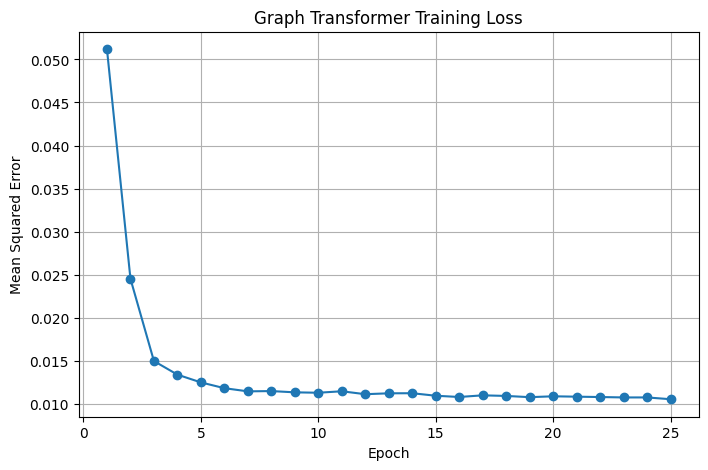

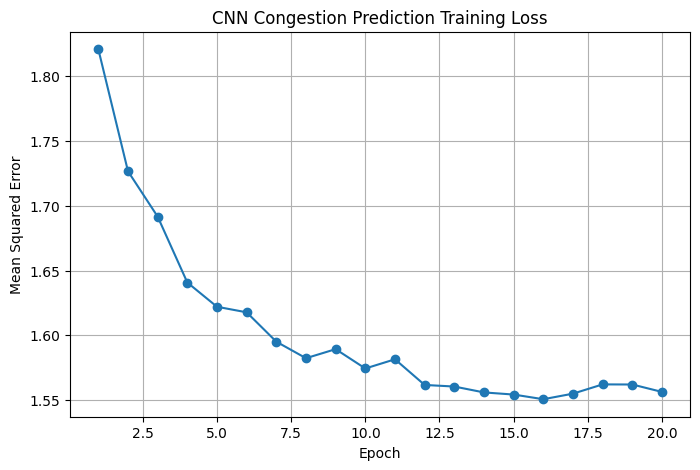

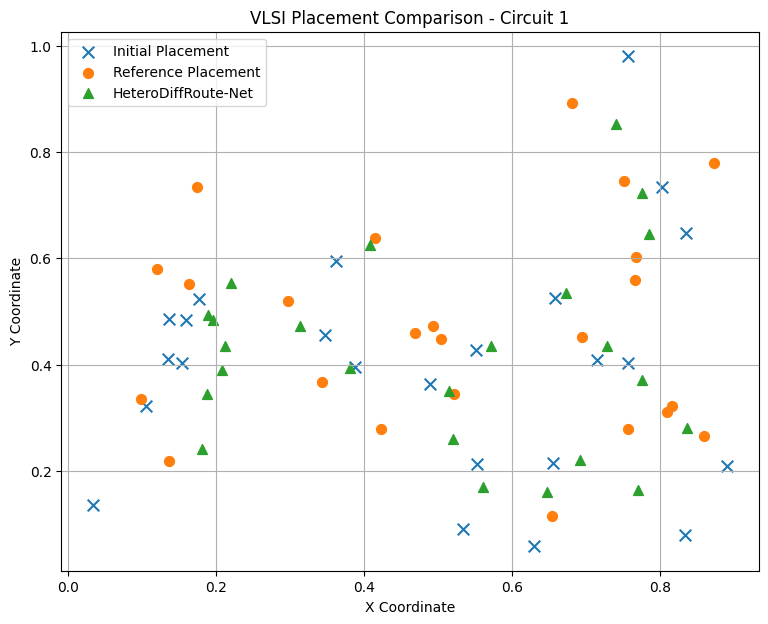

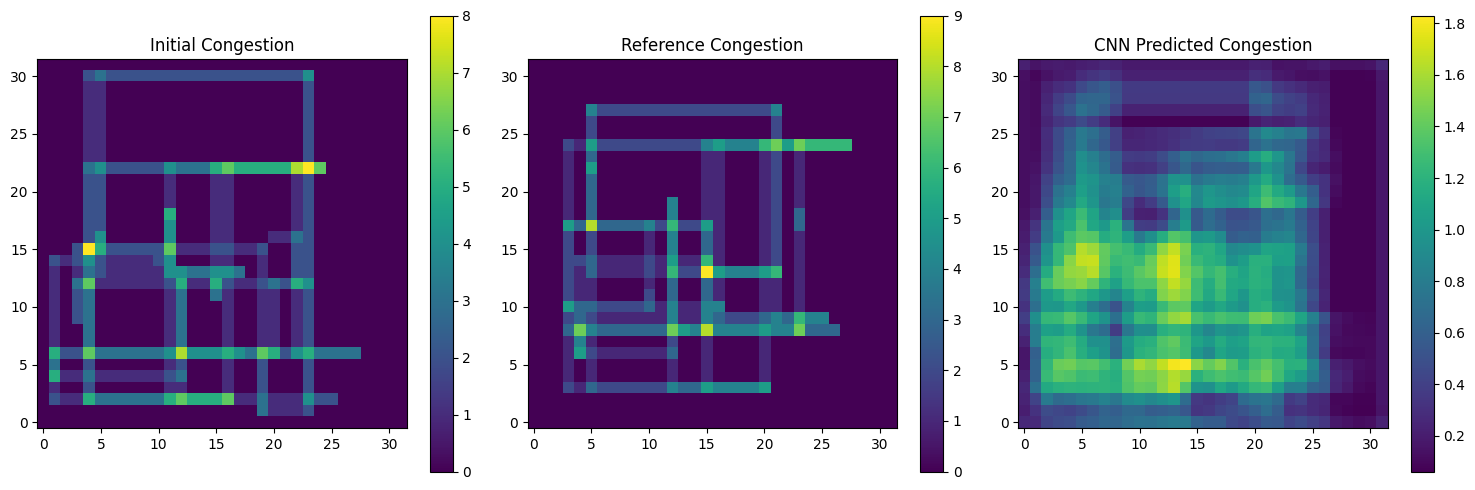

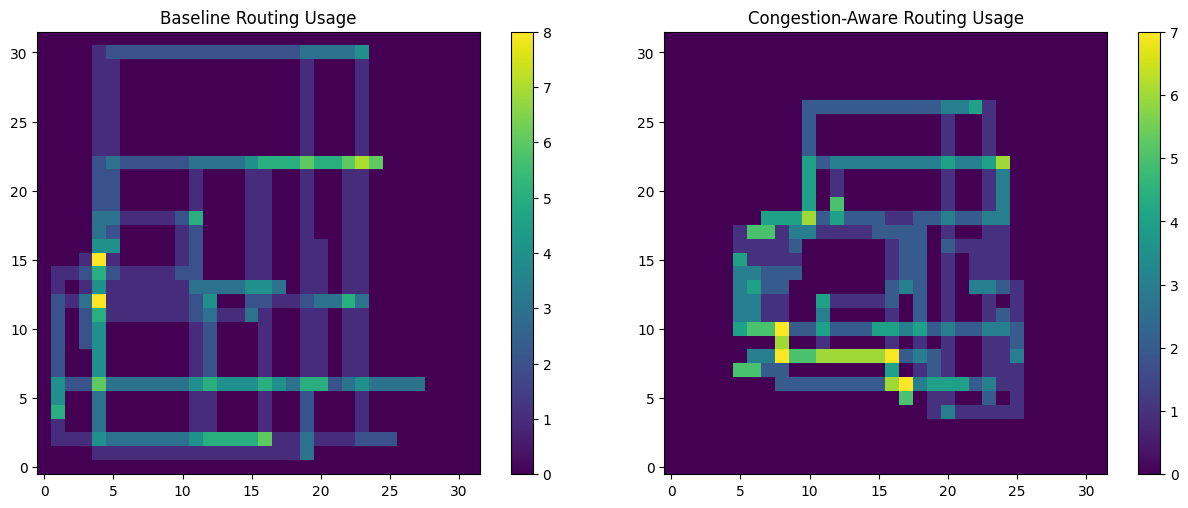

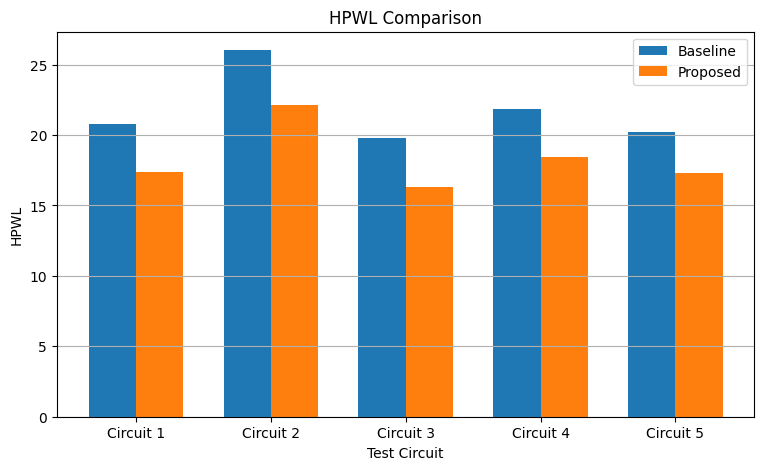

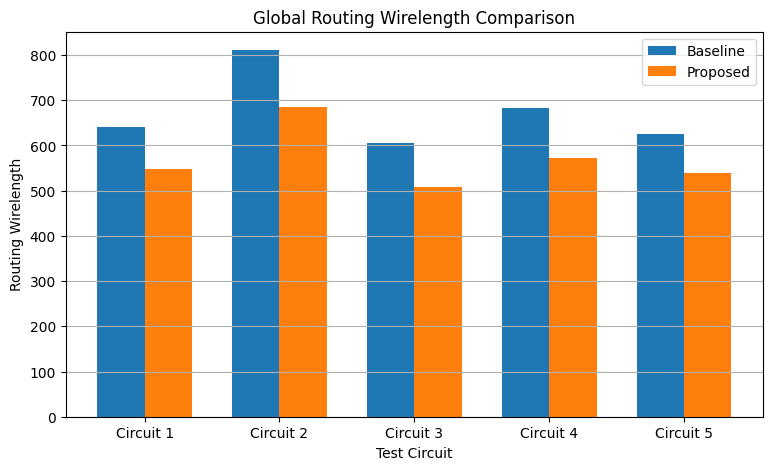

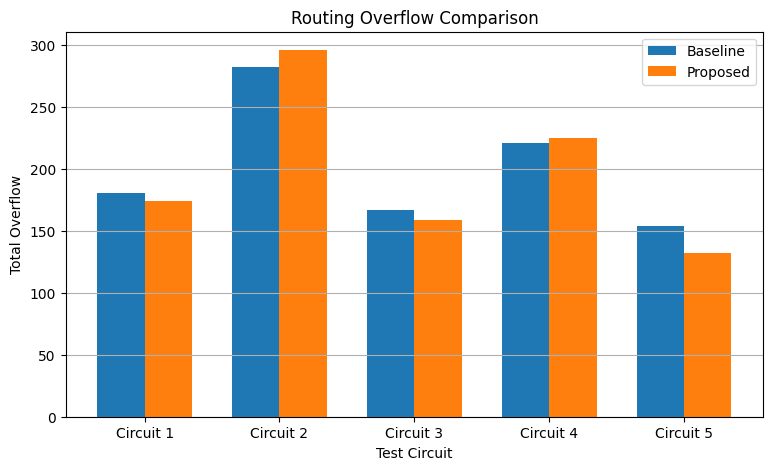


CSV files generated successfully.
1. HeteroDiffRouteNet_Results.csv
2. HeteroDiffRouteNet_Average_Results.csv


HETERODIFFROUTE-NET - FINAL EXPERIMENT SUMMARY

Implemented Modules:
1. Synthetic VLSI Circuit Generator
2. Heterogeneous Graph Representation
3. Graph Transformer Placement Prediction
4. Diffusion-Inspired Coordinate Refinement
5. CNN Congestion Prediction
6. A* Congestion-Aware Global Routing
7. Baseline Performance Comparison
8. Performance Evaluation and Visualization

Average Experimental Results:
Average Placement MAE: 0.08554
Average Congestion MSE: 1.66914
Average Baseline HPWL: 21.7329
Average Proposed HPWL: 18.3295
Average Baseline Wirelength: 673.20
Average Proposed Wirelength: 569.80


HETERODIFFROUTE-NET EXECUTION COMPLETED SUCCESSFULLY

Important: These are synthetic proof-of-concept results. They do not establish performance on real VLSI benchmark circuits.

Generating individual reports and five-panel figures for all five circuits...


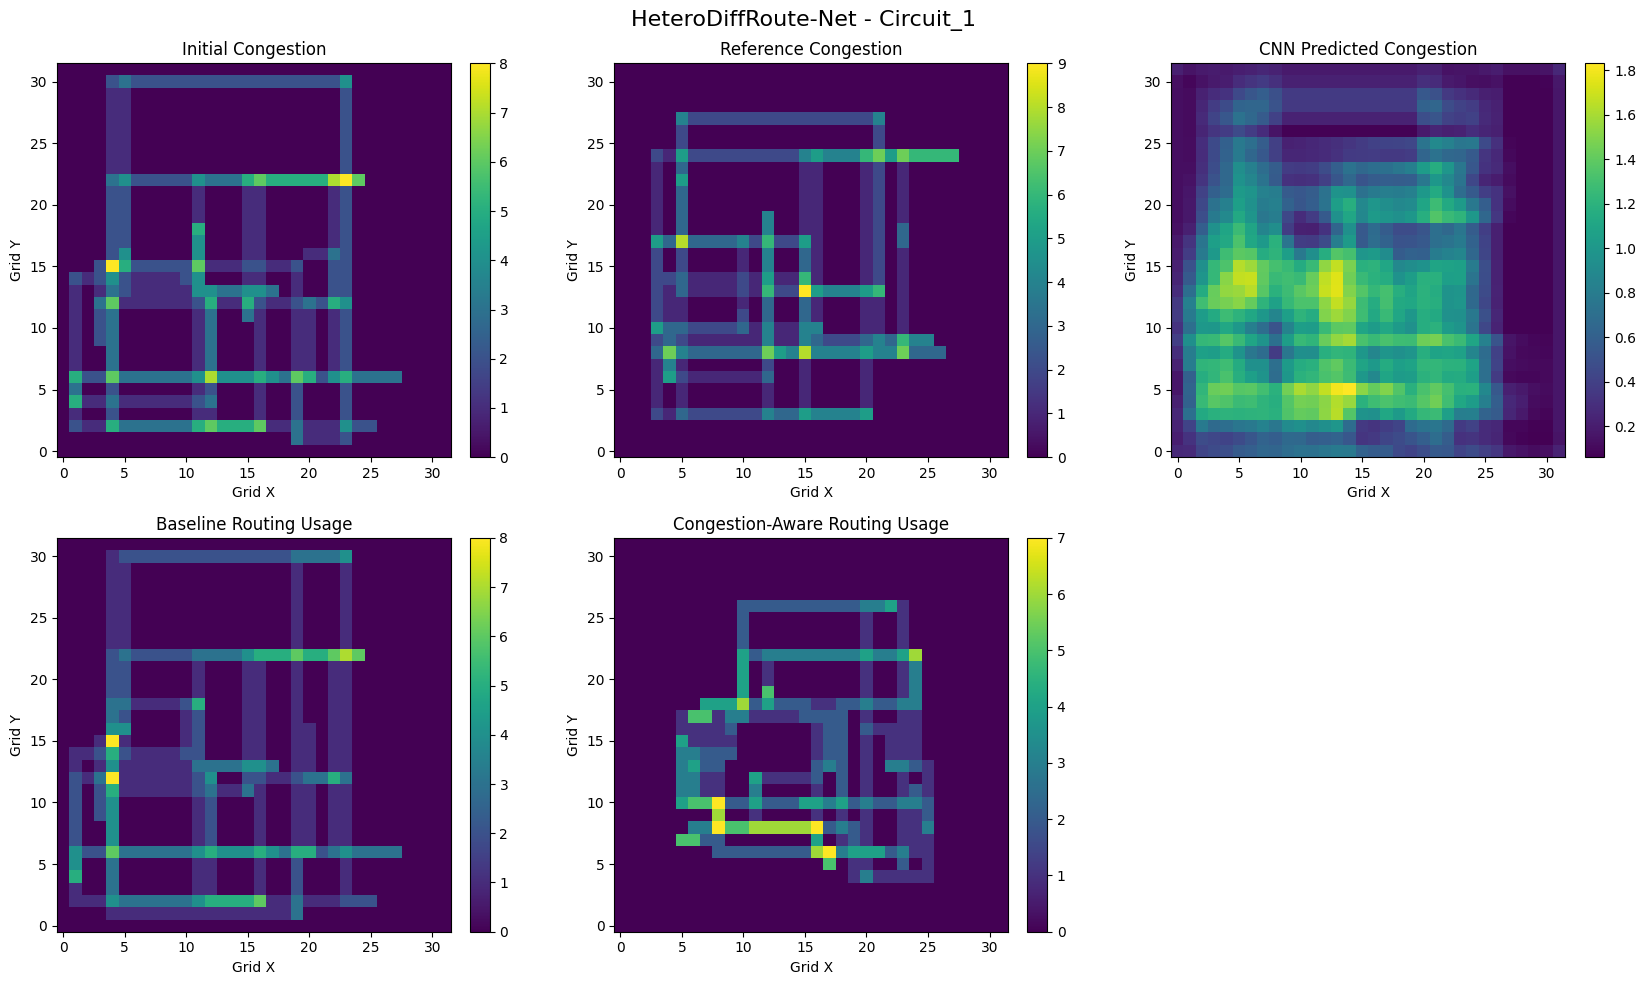

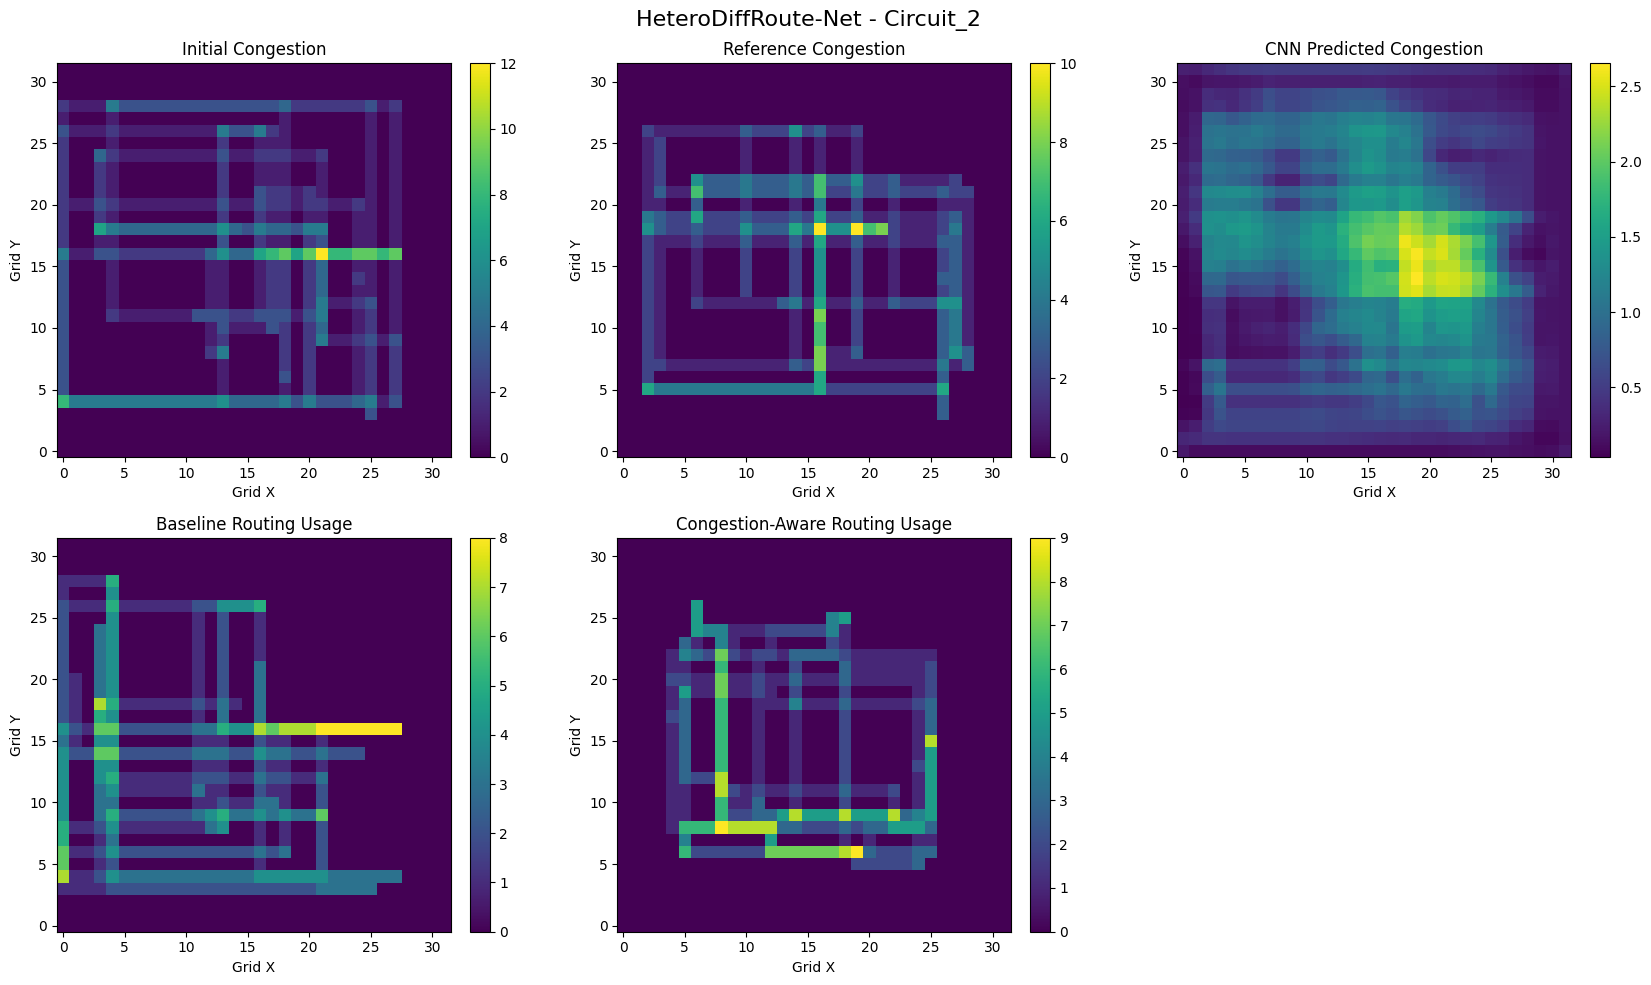

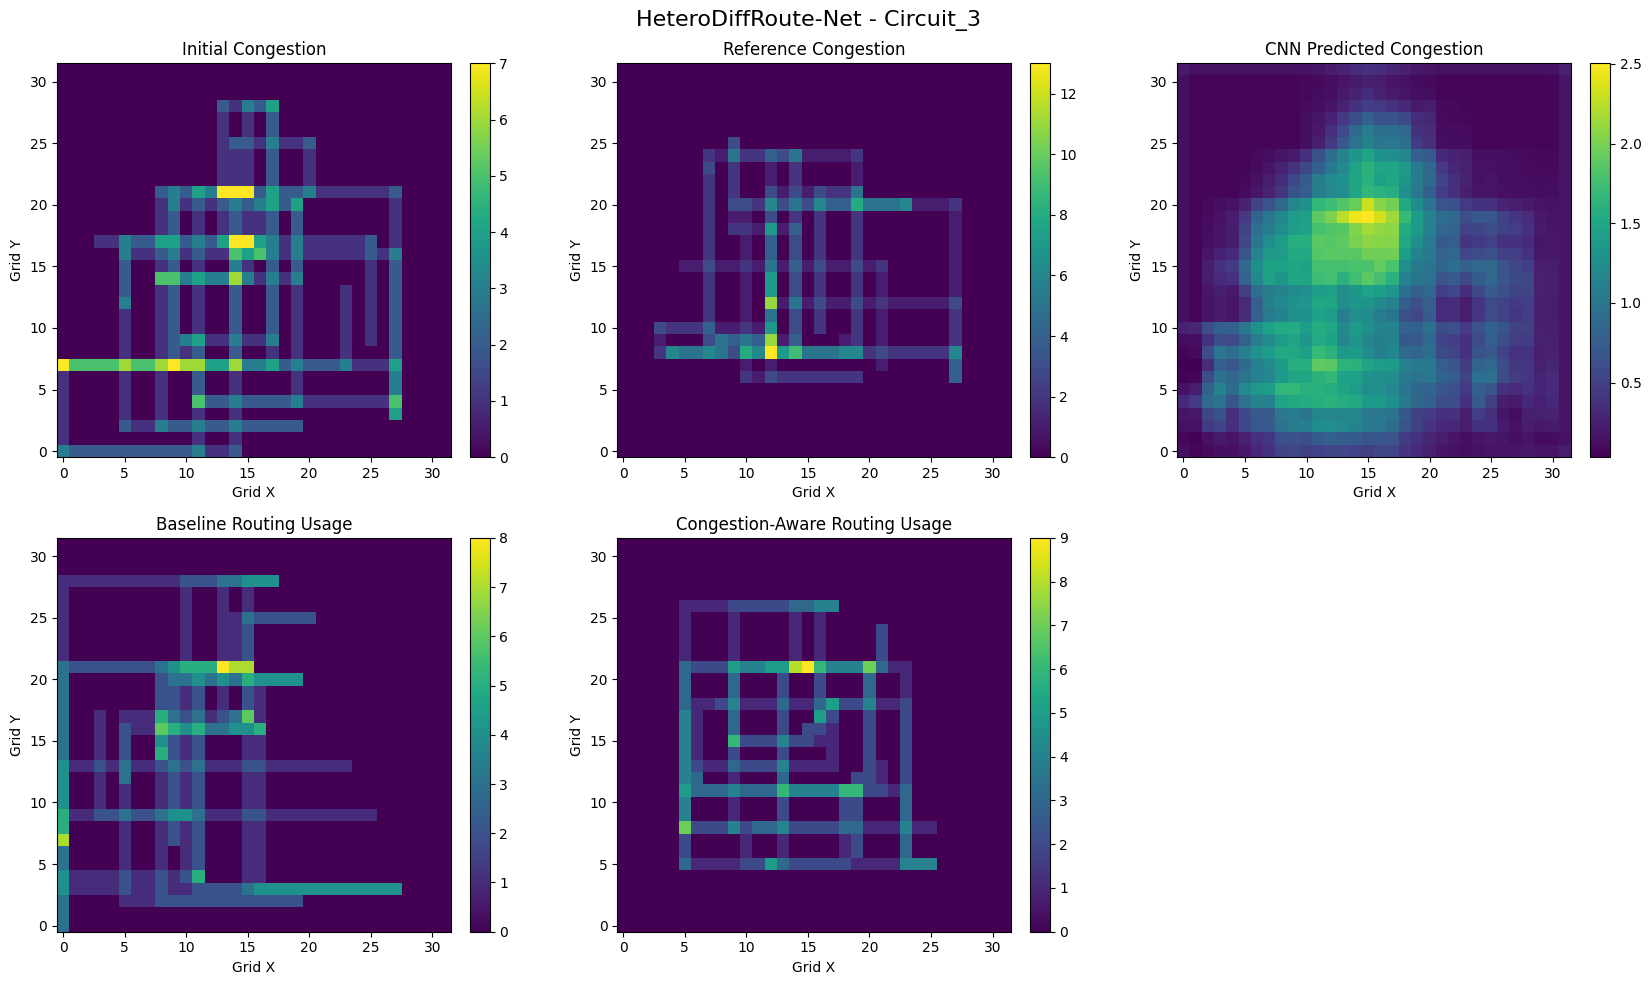

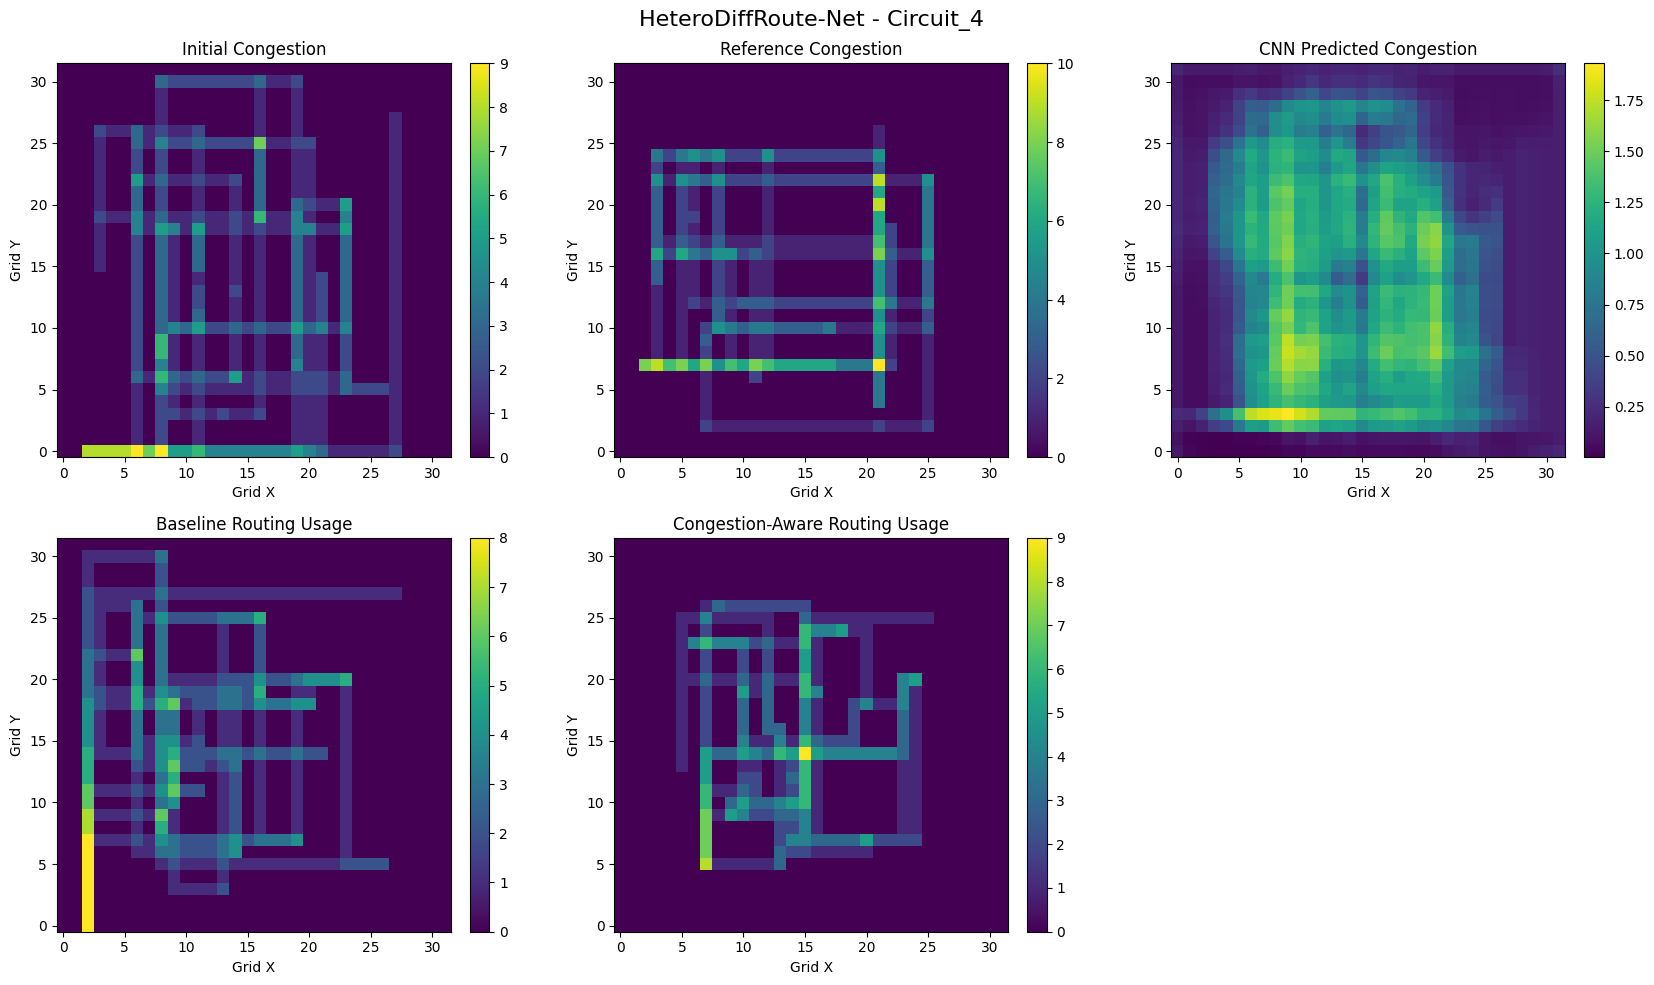

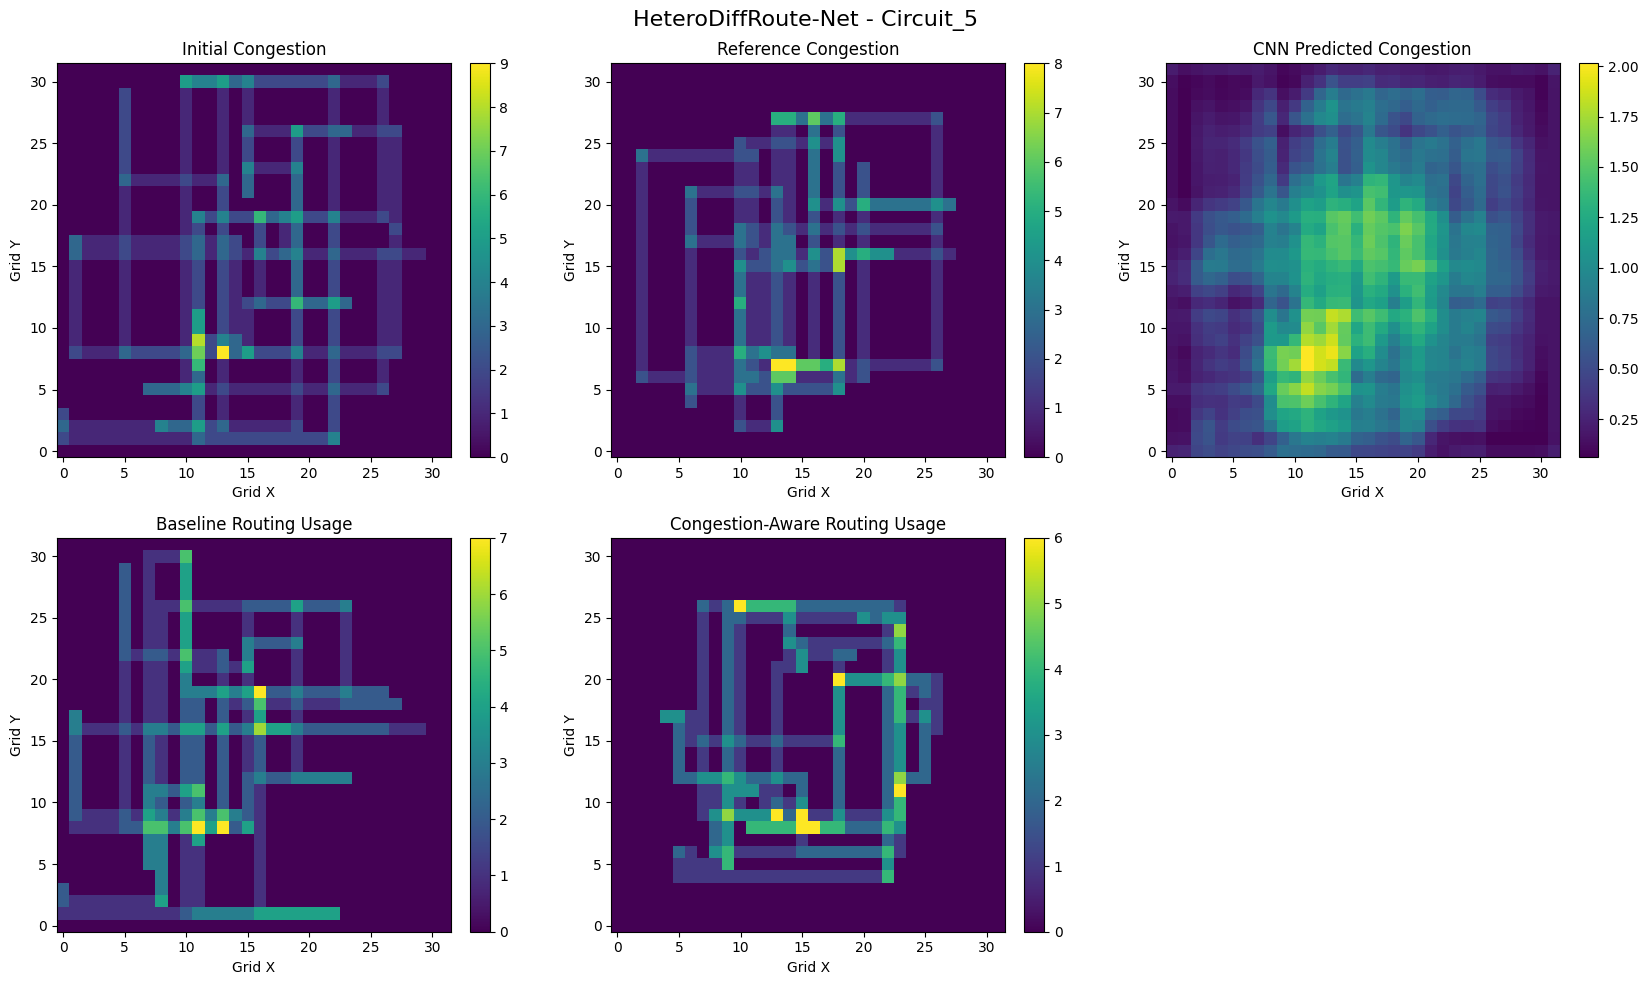


ALL FIVE CIRCUITS HAVE BEEN PROCESSED
Circuit 1/5: completed
Circuit 2/5: completed
Circuit 3/5: completed
Circuit 4/5: completed
Circuit 5/5: completed

Results folder: /content/HeteroDiffRouteNet_All5_Results
Combined CSV: /content/HeteroDiffRouteNet_All5_Results/HeteroDiffRouteNet_All5_Results.csv
ZIP results: /content/HeteroDiffRouteNet_All5_Circuits_Complete_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Research note:
This implementation uses five synthetic proof-of-concept test circuits.
The results do not establish performance on real ISPD/ICCAD benchmarks.
The diffusion module is diffusion-inspired coordinate refinement,
not a full probabilistic diffusion model.


In [ ]:
# ================================================================
# HETERODIFFROUTE-NET
# A Hybrid Heterogeneous Graph Transformer and Diffusion Learning
# Framework for Routability-Aware VLSI Placement and Global Routing
#
# Complete single-cell Google Colab implementation
#
# NOTE:
# This is a research proof-of-concept using synthetic VLSI circuits.
# It is not a replacement for industrial EDA tools or standard
# ISPD/ICCAD benchmark evaluation.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import os
import random
import heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader

from IPython.display import display

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("HETERODIFFROUTE-NET")
print("=" * 65)
print("Device:", DEVICE)


# ================================================================
# 2. CONFIGURATION
# ================================================================

NUM_NODES = 24
NUM_NETS = 36

GRID_SIZE = 32

# All five test circuits and their plots/metrics are saved here.
OUTPUT_DIR = "HeteroDiffRouteNet_All5_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_SAMPLES = 120
TEST_SAMPLES = 5

GRAPH_EPOCHS = 25
CNN_EPOCHS = 20

BATCH_SIZE = 16

LEARNING_RATE = 0.001

ROUTING_CAPACITY = 2

print("\nConfiguration loaded successfully.")


# ================================================================
# 3. SYNTHETIC VLSI CIRCUIT GENERATION
# ================================================================

def generate_circuit():

    n = NUM_NODES

    # Generate reference/ideal component coordinates
    true_positions = np.random.uniform(
        0.08, 0.92, size=(n, 2)
    ).astype(np.float32)

    # Component types:
    # 0 = Standard Cell
    # 1 = Macro
    # 2 = Other/IO component

    node_types = np.random.randint(0, 3, size=n)

    # Component dimensions
    widths = np.random.uniform(
        0.01, 0.04, size=n
    ).astype(np.float32)

    heights = np.random.uniform(
        0.01, 0.04, size=n
    ).astype(np.float32)

    # Initial placement contains coordinate noise
    initial_positions = (
        true_positions
        + np.random.normal(
            0, 0.12, size=(n, 2)
        )
    )

    initial_positions = np.clip(
        initial_positions, 0.02, 0.98
    ).astype(np.float32)

    # Generate connectivity
    edges = set()

    while len(edges) < NUM_NETS:

        a, b = np.random.choice(
            n, size=2, replace=False
        )

        if a != b:
            edges.add(tuple(sorted((int(a), int(b)))))

    edges = np.array(
        list(edges), dtype=np.int64
    )

    # Build adjacency matrix
    adjacency = np.eye(
        n, dtype=np.float32
    )

    for a, b in edges:
        adjacency[a, b] = 1
        adjacency[b, a] = 1

    # Node degree
    degree = adjacency.sum(axis=1) - 1

    degree = degree / max(
        degree.max(), 1
    )

    # One-hot component types
    type_features = np.eye(
        3, dtype=np.float32
    )[node_types]

    # Node features:
    # x, y, type_0, type_1, type_2,
    # degree, width, height

    features = np.concatenate(
        [
            initial_positions,
            type_features,
            degree.reshape(-1, 1),
            widths.reshape(-1, 1),
            heights.reshape(-1, 1)
        ],
        axis=1
    ).astype(np.float32)

    return {
        "features": features,
        "adjacency": adjacency,
        "initial": initial_positions,
        "true": true_positions,
        "edges": edges,
        "types": node_types,
        "widths": widths,
        "heights": heights
    }


# ================================================================
# 4. GENERATE TRAINING DATA
# ================================================================

print("\nGenerating synthetic training circuits...")

training_circuits = [
    generate_circuit()
    for _ in range(TRAIN_SAMPLES)
]

X_graph = np.array([
    c["features"] for c in training_circuits
])

A_graph = np.array([
    c["adjacency"] for c in training_circuits
])

Y_graph = np.array([
    c["true"] for c in training_circuits
])

print("Training circuits:", len(training_circuits))
print("Node feature shape:", X_graph.shape)
print("Adjacency shape:", A_graph.shape)
print("Target placement shape:", Y_graph.shape)


# ================================================================
# 5. GRAPH TRANSFORMER
# ================================================================

class GraphTransformerBlock(nn.Module):

    def __init__(self, dimension, heads=4):

        super().__init__()

        self.dimension = dimension
        self.heads = heads
        self.head_dim = dimension // heads

        self.qkv = nn.Linear(
            dimension, dimension * 3
        )

        self.projection = nn.Linear(
            dimension, dimension
        )

        self.norm1 = nn.LayerNorm(dimension)
        self.norm2 = nn.LayerNorm(dimension)

        self.feed_forward = nn.Sequential(
            nn.Linear(dimension, dimension * 2),
            nn.GELU(),
            nn.Linear(dimension * 2, dimension)
        )

    def forward(self, x, adjacency):

        batch, nodes, dimension = x.shape

        qkv = self.qkv(x)

        qkv = qkv.reshape(
            batch,
            nodes,
            3,
            self.heads,
            self.head_dim
        )

        qkv = qkv.permute(
            2, 0, 3, 1, 4
        )

        q, k, v = qkv[0], qkv[1], qkv[2]

        scores = torch.matmul(
            q, k.transpose(-2, -1)
        ) / np.sqrt(self.head_dim)

        # Restrict attention to connected graph nodes
        # Self-attention is retained through diagonal entries.

        mask = adjacency.unsqueeze(1) <= 0

        scores = scores.masked_fill(
            mask, -1e4
        )

        attention = torch.softmax(
            scores, dim=-1
        )

        output = torch.matmul(
            attention, v
        )

        output = output.transpose(
            1, 2
        ).contiguous().reshape(
            batch, nodes, dimension
        )

        output = self.projection(output)

        x = self.norm1(x + output)

        x = self.norm2(
            x + self.feed_forward(x)
        )

        return x


class HeterogeneousGraphTransformer(nn.Module):

    def __init__(self, input_dim=8, hidden_dim=64):

        super().__init__()

        self.embedding = nn.Linear(
            input_dim, hidden_dim
        )

        self.block1 = GraphTransformerBlock(
            hidden_dim, heads=4
        )

        self.block2 = GraphTransformerBlock(
            hidden_dim, heads=4
        )

        self.block3 = GraphTransformerBlock(
            hidden_dim, heads=4
        )

        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.GELU(),
            nn.Linear(32, 2),
            nn.Sigmoid()
        )

    def forward(self, features, adjacency):

        x = self.embedding(features)

        x = self.block1(x, adjacency)
        x = self.block2(x, adjacency)
        x = self.block3(x, adjacency)

        coordinates = self.output_layer(x)

        return coordinates


# ================================================================
# 6. TRAIN GRAPH TRANSFORMER
# ================================================================

X_tensor = torch.tensor(
    X_graph, dtype=torch.float32
)

A_tensor = torch.tensor(
    A_graph, dtype=torch.float32
)

Y_tensor = torch.tensor(
    Y_graph, dtype=torch.float32
)

graph_dataset = TensorDataset(
    X_tensor, A_tensor, Y_tensor
)

graph_loader = DataLoader(
    graph_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

graph_model = HeterogeneousGraphTransformer().to(DEVICE)

graph_optimizer = torch.optim.Adam(
    graph_model.parameters(),
    lr=LEARNING_RATE
)

graph_loss_function = nn.MSELoss()

graph_training_losses = []

print("\nTraining Graph Transformer...")

for epoch in range(GRAPH_EPOCHS):

    graph_model.train()

    total_loss = 0

    for features, adjacency, target in graph_loader:

        features = features.to(DEVICE)
        adjacency = adjacency.to(DEVICE)
        target = target.to(DEVICE)

        graph_optimizer.zero_grad()

        prediction = graph_model(
            features, adjacency
        )

        loss = graph_loss_function(
            prediction, target
        )

        loss.backward()

        graph_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(graph_loader)

    graph_training_losses.append(
        average_loss
    )

    print(
        f"Epoch {epoch + 1:02d}/{GRAPH_EPOCHS} "
        f"| Loss: {average_loss:.6f}"
    )


# ================================================================
# 7. DIFFUSION-INSPIRED PLACEMENT REFINEMENT
# ================================================================

def diffusion_refinement(
    predicted_positions,
    initial_positions,
    iterations=15
):

    """
    Simplified diffusion-inspired coordinate refinement.

    This is a deterministic iterative refinement process.
    It is not a full probabilistic diffusion model.
    """

    coordinates = predicted_positions.copy()

    for step in range(iterations):

        alpha = 0.10 * (
            1 - step / iterations
        )

        # Smooth coordinates toward the model prediction
        coordinates = (
            (1 - alpha) * coordinates
            + alpha * predicted_positions
        )

        # Keep coordinates within placement region
        coordinates = np.clip(
            coordinates, 0.02, 0.98
        )

    return coordinates.astype(np.float32)


# ================================================================
# 8. CONGESTION MAP GENERATION
# ================================================================

def generate_demand_map(positions, edges):

    demand = np.zeros(
        (GRID_SIZE, GRID_SIZE),
        dtype=np.float32
    )

    for a, b in edges:

        x1 = int(
            np.clip(
                positions[a, 0] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        y1 = int(
            np.clip(
                positions[a, 1] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        x2 = int(
            np.clip(
                positions[b, 0] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        y2 = int(
            np.clip(
                positions[b, 1] * (GRID_SIZE - 1),
                0,
                GRID_SIZE - 1
            )
        )

        # Horizontal segment
        for x in range(
            min(x1, x2),
            max(x1, x2) + 1
        ):

            demand[y1, x] += 1

        # Vertical segment
        for y in range(
            min(y1, y2),
            max(y1, y2) + 1
        ):

            demand[y, x2] += 1

    return demand


# ================================================================
# 9. GENERATE CNN TRAINING DATA
# ================================================================

print("\nGenerating congestion training data...")

cnn_inputs = []
cnn_targets = []

for circuit in training_circuits:

    initial_map = generate_demand_map(
        circuit["initial"],
        circuit["edges"]
    )

    true_map = generate_demand_map(
        circuit["true"],
        circuit["edges"]
    )

    cnn_inputs.append(initial_map)
    cnn_targets.append(true_map)

cnn_inputs = np.array(
    cnn_inputs, dtype=np.float32
)

cnn_targets = np.array(
    cnn_targets, dtype=np.float32
)

cnn_X = torch.tensor(
    cnn_inputs[:, None, :, :],
    dtype=torch.float32
)

cnn_Y = torch.tensor(
    cnn_targets[:, None, :, :],
    dtype=torch.float32
)

cnn_dataset = TensorDataset(
    cnn_X, cnn_Y
)

cnn_loader = DataLoader(
    cnn_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)


# ================================================================
# 10. CNN CONGESTION PREDICTION MODEL
# ================================================================

class CongestionCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Conv2d(
                1, 16, kernel_size=3, padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                16, 32, kernel_size=3, padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                32, 16, kernel_size=3, padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                16, 1, kernel_size=1
            ),

            nn.Softplus()
        )

    def forward(self, x):

        return self.network(x)


# ================================================================
# 11. TRAIN CNN
# ================================================================

cnn_model = CongestionCNN().to(DEVICE)

cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=LEARNING_RATE
)

cnn_loss_function = nn.MSELoss()

cnn_training_losses = []

print("\nTraining CNN Congestion Predictor...")

for epoch in range(CNN_EPOCHS):

    cnn_model.train()

    total_loss = 0

    for inputs, targets in cnn_loader:

        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        cnn_optimizer.zero_grad()

        prediction = cnn_model(inputs)

        loss = cnn_loss_function(
            prediction, targets
        )

        loss.backward()

        cnn_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(cnn_loader)

    cnn_training_losses.append(
        average_loss
    )

    print(
        f"Epoch {epoch + 1:02d}/{CNN_EPOCHS} "
        f"| Loss: {average_loss:.6f}"
    )


# ================================================================
# 12. GLOBAL ROUTING USING A* ALGORITHM
# ================================================================

def astar_route(
    start,
    goal,
    congestion=None,
    congestion_weight=0.0
):

    rows = GRID_SIZE
    cols = GRID_SIZE

    directions = [
        (0, 1),
        (0, -1),
        (1, 0),
        (-1, 0)
    ]

    def heuristic(a, b):

        return (
            abs(a[0] - b[0])
            + abs(a[1] - b[1])
        )

    queue = []

    heapq.heappush(
        queue,
        (0, start)
    )

    came_from = {}

    cost_so_far = {
        start: 0
    }

    while queue:

        _, current = heapq.heappop(
            queue
        )

        if current == goal:

            path = [current]

            while current in came_from:

                current = came_from[current]

                path.append(current)

            path.reverse()

            return path

        for dx, dy in directions:

            next_node = (
                current[0] + dx,
                current[1] + dy
            )

            x, y = next_node

            if not (
                0 <= x < cols
                and 0 <= y < rows
            ):

                continue

            step_cost = 1.0

            if congestion is not None:

                congestion_value = float(
                    congestion[y, x]
                )

                step_cost += (
                    congestion_weight
                    * congestion_value
                )

            new_cost = (
                cost_so_far[current]
                + step_cost
            )

            if (
                next_node not in cost_so_far
                or new_cost < cost_so_far[next_node]
            ):

                cost_so_far[next_node] = new_cost

                priority = (
                    new_cost
                    + heuristic(next_node, goal)
                )

                heapq.heappush(
                    queue,
                    (priority, next_node)
                )

                came_from[next_node] = current

    return []


# ================================================================
# 13. ROUTE ALL NETS
# ================================================================

def perform_global_routing(
    positions,
    edges,
    congestion=None,
    congestion_weight=0.0
):

    routing_usage = np.zeros(
        (GRID_SIZE, GRID_SIZE),
        dtype=np.float32
    )

    total_wirelength = 0

    successful_routes = 0

    for a, b in edges:

        start = (
            int(
                np.clip(
                    positions[a, 0] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            ),

            int(
                np.clip(
                    positions[a, 1] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            )
        )

        goal = (
            int(
                np.clip(
                    positions[b, 0] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            ),

            int(
                np.clip(
                    positions[b, 1] * (GRID_SIZE - 1),
                    0,
                    GRID_SIZE - 1
                )
            )
        )

        path = astar_route(
            start,
            goal,
            congestion,
            congestion_weight
        )

        if len(path) > 0:

            successful_routes += 1

            total_wirelength += (
                len(path) - 1
            )

            for x, y in path:

                routing_usage[y, x] += 1

    overflow_map = np.maximum(
        routing_usage - ROUTING_CAPACITY,
        0
    )

    total_overflow = float(
        overflow_map.sum()
    )

    maximum_overflow = float(
        overflow_map.max()
    )

    return {
        "wirelength": float(total_wirelength),
        "usage": routing_usage,
        "overflow": total_overflow,
        "maximum_overflow": maximum_overflow,
        "successful_routes": successful_routes
    }


# ================================================================
# 14. PERFORMANCE METRICS
# ================================================================

def calculate_hpwl(positions, edges):

    hpwl = 0

    for a, b in edges:

        hpwl += (
            abs(
                positions[a, 0] - positions[b, 0]
            )
            +
            abs(
                positions[a, 1] - positions[b, 1]
            )
        )

    return float(hpwl)


def calculate_placement_mae(predicted, actual):

    return float(
        np.mean(
            np.abs(predicted - actual)
        )
    )


def calculate_displacement(initial, final):

    distances = np.sqrt(
        np.sum(
            (initial - final) ** 2,
            axis=1
        )
    )

    return float(
        np.mean(distances)
    )


def calculate_density_peak(positions):

    grid = np.zeros(
        (10, 10),
        dtype=np.float32
    )

    for x, y in positions:

        gx = min(
            int(x * 10), 9
        )

        gy = min(
            int(y * 10), 9
        )

        grid[gy, gx] += 1

    return float(
        grid.max()
    )


# ================================================================
# 15. GENERATE TEST CIRCUITS
# ================================================================

print("\nGenerating test circuits...")

test_circuits = [
    generate_circuit()
    for _ in range(TEST_SAMPLES)
]


# ================================================================
# 16. RUN COMPLETE EXPERIMENTS
# ================================================================

results = []

placement_predictions = []

congestion_predictions = []

true_congestion_maps = []

routing_maps = []

baseline_routing_maps = []

# Keep per-circuit data so that separate figures can be generated for 1/5 to 5/5.
all_initial_positions = []
all_true_positions = []
all_edges = []
all_initial_demand_maps = []
all_proposed_demand_maps = []
all_proposed_routing_results = []
all_baseline_routing_results = []

first_test_initial = None
first_test_true = None
first_test_predicted = None

print("\n")
print("=" * 65)
print("RUNNING HETERODIFFROUTE-NET EXPERIMENTS")
print("=" * 65)

graph_model.eval()
cnn_model.eval()

for index, circuit in enumerate(test_circuits):

    print(
        f"\nProcessing Circuit {index + 1}/{TEST_SAMPLES}"
    )

    # ------------------------------------------------------------
    # A. INITIAL PLACEMENT
    # ------------------------------------------------------------

    initial_positions = circuit["initial"]

    true_positions = circuit["true"]

    edges = circuit["edges"]

    all_initial_positions.append(initial_positions.copy())
    all_true_positions.append(true_positions.copy())
    all_edges.append(edges.copy())

    # ------------------------------------------------------------
    # B. GRAPH TRANSFORMER PLACEMENT PREDICTION
    # ------------------------------------------------------------

    features = torch.tensor(
        circuit["features"][None, :, :],
        dtype=torch.float32,
        device=DEVICE
    )

    adjacency = torch.tensor(
        circuit["adjacency"][None, :, :],
        dtype=torch.float32,
        device=DEVICE
    )

    with torch.no_grad():

        predicted_positions = graph_model(
            features, adjacency
        ).cpu().numpy()[0]

    # ------------------------------------------------------------
    # C. DIFFUSION-INSPIRED REFINEMENT
    # ------------------------------------------------------------

    refined_positions = diffusion_refinement(
        predicted_positions,
        initial_positions,
        iterations=15
    )

    placement_predictions.append(
        refined_positions
    )

    # ------------------------------------------------------------
    # D. CONGESTION PREDICTION
    # ------------------------------------------------------------

    initial_demand = generate_demand_map(
        initial_positions,
        edges
    )
    all_initial_demand_maps.append(initial_demand.copy())

    true_demand = generate_demand_map(
        true_positions,
        edges
    )
    all_proposed_demand_maps.append(true_demand.copy())

    demand_tensor = torch.tensor(
        initial_demand[None, None, :, :],
        dtype=torch.float32,
        device=DEVICE
    )

    with torch.no_grad():

        predicted_demand = cnn_model(
            demand_tensor
        ).cpu().numpy()[0, 0]

    predicted_demand = np.maximum(
        predicted_demand, 0
    )

    congestion_predictions.append(
        predicted_demand
    )

    true_congestion_maps.append(
        true_demand
    )

    # ------------------------------------------------------------
    # E. BASELINE ROUTING
    # ------------------------------------------------------------

    baseline_routing = perform_global_routing(
        initial_positions,
        edges,
        congestion=None,
        congestion_weight=0
    )

    baseline_routing_maps.append(
        baseline_routing["usage"]
    )
    all_baseline_routing_results.append(baseline_routing)

    # ------------------------------------------------------------
    # F. PROPOSED CONGESTION-AWARE ROUTING
    # ------------------------------------------------------------

    proposed_routing = perform_global_routing(
        refined_positions,
        edges,
        congestion=predicted_demand,
        congestion_weight=0.15
    )

    routing_maps.append(
        proposed_routing["usage"]
    )
    all_proposed_routing_results.append(proposed_routing)

    # ------------------------------------------------------------
    # G. PLACEMENT METRICS
    # ------------------------------------------------------------

    baseline_hpwl = calculate_hpwl(
        initial_positions,
        edges
    )

    proposed_hpwl = calculate_hpwl(
        refined_positions,
        edges
    )

    placement_mae = calculate_placement_mae(
        refined_positions,
        true_positions
    )

    displacement = calculate_displacement(
        initial_positions,
        refined_positions
    )

    baseline_density = calculate_density_peak(
        initial_positions
    )

    proposed_density = calculate_density_peak(
        refined_positions
    )

    # ------------------------------------------------------------
    # H. CONGESTION PREDICTION METRICS
    # ------------------------------------------------------------

    mse = np.mean(
        (true_demand.flatten()
         - predicted_demand.flatten()) ** 2
    )

    mae = np.mean(
        np.abs(
            true_demand.flatten()
            - predicted_demand.flatten()
        )
    )

    if np.std(true_demand) > 0 and np.std(predicted_demand) > 0:
        congestion_correlation = float(np.corrcoef(
            true_demand.flatten(), predicted_demand.flatten()
        )[0, 1])
    else:
        congestion_correlation = 0.0

    # ------------------------------------------------------------
    # I. ROUTING METRICS
    # ------------------------------------------------------------

    baseline_wirelength = (
        baseline_routing["wirelength"]
    )

    proposed_wirelength = (
        proposed_routing["wirelength"]
    )

    baseline_overflow = (
        baseline_routing["overflow"]
    )

    proposed_overflow = (
        proposed_routing["overflow"]
    )

    # ------------------------------------------------------------
    # J. STORE RESULTS
    # ------------------------------------------------------------

    results.append({

        "Circuit": f"Circuit {index + 1}",

        "Baseline HPWL": baseline_hpwl,

        "Proposed HPWL": proposed_hpwl,

        "Placement MAE": placement_mae,

        "Average Displacement": displacement,

        "Baseline Density Peak": baseline_density,

        "Proposed Density Peak": proposed_density,

        "Congestion MSE": mse,

        "Congestion MAE": mae,
        "Congestion Correlation": congestion_correlation,

        "Baseline Wirelength": baseline_wirelength,

        "Proposed Wirelength": proposed_wirelength,

        "Baseline Overflow": baseline_overflow,

        "Proposed Overflow": proposed_overflow,

        "Successful Routes": proposed_routing[
            "successful_routes"
        ]

    })

    print(
        f"Baseline HPWL: {baseline_hpwl:.4f}"
    )

    print(
        f"Proposed HPWL: {proposed_hpwl:.4f}"
    )

    print(
        f"Placement MAE: {placement_mae:.4f}"
    )

    print(
        f"Congestion MSE: {mse:.4f}"
    )

    print(
        f"Baseline Routing Wirelength: "
        f"{baseline_wirelength:.2f}"
    )

    print(
        f"Proposed Routing Wirelength: "
        f"{proposed_wirelength:.2f}"
    )

    print(
        f"Baseline Overflow: {baseline_overflow:.2f}"
    )

    print(
        f"Proposed Overflow: {proposed_overflow:.2f}"
    )

    if index == 0:

        first_test_initial = initial_positions.copy()

        first_test_true = true_positions.copy()

        first_test_predicted = refined_positions.copy()


# ================================================================
# 17. RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(results)

print("\n")
print("=" * 65)
print("EXPERIMENTAL RESULTS")
print("=" * 65)

display(
    results_df.round(4)
)


# ================================================================
# 18. AVERAGE PERFORMANCE
# ================================================================

numeric_columns = results_df.select_dtypes(
    include=[np.number]
).columns

average_results = results_df[
    numeric_columns
].mean()

average_df = pd.DataFrame({
    "Metric": average_results.index,
    "Average Value": average_results.values
})

print("\nAVERAGE PERFORMANCE")

display(
    average_df.round(4)
)


# ================================================================
# 19. PERFORMANCE IMPROVEMENT
# ================================================================

def calculate_improvement(baseline, proposed):

    if abs(baseline) < 1e-10:

        return 0.0

    return (
        (baseline - proposed)
        / abs(baseline)
    ) * 100


hpwl_improvement = calculate_improvement(
    results_df["Baseline HPWL"].mean(),
    results_df["Proposed HPWL"].mean()
)

wirelength_improvement = calculate_improvement(
    results_df["Baseline Wirelength"].mean(),
    results_df["Proposed Wirelength"].mean()
)

overflow_improvement = calculate_improvement(
    results_df["Baseline Overflow"].mean(),
    results_df["Proposed Overflow"].mean()
)

print("\n")
print("=" * 65)
print("PERFORMANCE COMPARISON")
print("=" * 65)

print(
    f"HPWL Improvement: {hpwl_improvement:.2f}%"
)

print(
    f"Routing Wirelength Improvement: "
    f"{wirelength_improvement:.2f}%"
)

print(
    f"Routing Overflow Improvement: "
    f"{overflow_improvement:.2f}%"
)


# ================================================================
# 20. GRAPH 1 - GRAPH TRANSFORMER TRAINING LOSS
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, GRAPH_EPOCHS + 1),
    graph_training_losses,
    marker="o"
)

plt.title(
    "Graph Transformer Training Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Mean Squared Error")

plt.grid(True)

plt.show()


# ================================================================
# 21. GRAPH 2 - CNN TRAINING LOSS
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, CNN_EPOCHS + 1),
    cnn_training_losses,
    marker="o"
)

plt.title(
    "CNN Congestion Prediction Training Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Mean Squared Error")

plt.grid(True)

plt.show()


# ================================================================
# 22. GRAPH 3 - PLACEMENT COMPARISON
# ================================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    first_test_initial[:, 0],
    first_test_initial[:, 1],
    label="Initial Placement",
    marker="x",
    s=70
)

plt.scatter(
    first_test_true[:, 0],
    first_test_true[:, 1],
    label="Reference Placement",
    marker="o",
    s=50
)

plt.scatter(
    first_test_predicted[:, 0],
    first_test_predicted[:, 1],
    label="HeteroDiffRoute-Net",
    marker="^",
    s=50
)

plt.title(
    "VLSI Placement Comparison - Circuit 1"
)

plt.xlabel("X Coordinate")

plt.ylabel("Y Coordinate")

plt.legend()

plt.grid(True)

plt.show()


# ================================================================
# 23. GRAPH 4 - CONGESTION PREDICTION
# ================================================================

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    generate_demand_map(
        first_test_initial,
        test_circuits[0]["edges"]
    ),
    origin="lower"
)

plt.title("Initial Congestion")

plt.colorbar()

plt.subplot(1, 3, 2)

plt.imshow(
    true_congestion_maps[0],
    origin="lower"
)

plt.title("Reference Congestion")

plt.colorbar()

plt.subplot(1, 3, 3)

plt.imshow(
    congestion_predictions[0],
    origin="lower"
)

plt.title("CNN Predicted Congestion")

plt.colorbar()

plt.tight_layout()

plt.show()


# ================================================================
# 24. GRAPH 5 - ROUTING CONGESTION COMPARISON
# ================================================================

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    baseline_routing_maps[0],
    origin="lower"
)

plt.title("Baseline Routing Usage")

plt.colorbar()

plt.subplot(1, 2, 2)

plt.imshow(
    routing_maps[0],
    origin="lower"
)

plt.title("Congestion-Aware Routing Usage")

plt.colorbar()

plt.tight_layout()

plt.show()


# ================================================================
# 25. GRAPH 6 - HPWL COMPARISON
# ================================================================

plt.figure(figsize=(9, 5))

x = np.arange(len(results_df))

width = 0.35

plt.bar(
    x - width / 2,
    results_df["Baseline HPWL"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    results_df["Proposed HPWL"],
    width,
    label="Proposed"
)

plt.title("HPWL Comparison")

plt.xlabel("Test Circuit")

plt.ylabel("HPWL")

plt.xticks(
    x,
    results_df["Circuit"]
)

plt.legend()

plt.grid(axis="y")

plt.show()


# ================================================================
# 26. GRAPH 7 - ROUTING WIRELENGTH COMPARISON
# ================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    results_df["Baseline Wirelength"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    results_df["Proposed Wirelength"],
    width,
    label="Proposed"
)

plt.title("Global Routing Wirelength Comparison")

plt.xlabel("Test Circuit")

plt.ylabel("Routing Wirelength")

plt.xticks(
    x,
    results_df["Circuit"]
)

plt.legend()

plt.grid(axis="y")

plt.show()


# ================================================================
# 27. GRAPH 8 - ROUTING OVERFLOW COMPARISON
# ================================================================

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    results_df["Baseline Overflow"],
    width,
    label="Baseline"
)

plt.bar(
    x + width / 2,
    results_df["Proposed Overflow"],
    width,
    label="Proposed"
)

plt.title("Routing Overflow Comparison")

plt.xlabel("Test Circuit")

plt.ylabel("Total Overflow")

plt.xticks(
    x,
    results_df["Circuit"]
)

plt.legend()

plt.grid(axis="y")

plt.show()


# ================================================================
# 28. SAVE EXPERIMENTAL RESULTS
# ================================================================

results_df.to_csv(
    "HeteroDiffRouteNet_Results.csv",
    index=False
)

average_df.to_csv(
    "HeteroDiffRouteNet_Average_Results.csv",
    index=False
)

print("\nCSV files generated successfully.")

print(
    "1. HeteroDiffRouteNet_Results.csv"
)

print(
    "2. HeteroDiffRouteNet_Average_Results.csv"
)


# ================================================================
# 29. FINAL PROJECT SUMMARY
# ================================================================

print("\n")
print("=" * 70)
print("HETERODIFFROUTE-NET - FINAL EXPERIMENT SUMMARY")
print("=" * 70)

print("\nImplemented Modules:")

print("1. Synthetic VLSI Circuit Generator")

print("2. Heterogeneous Graph Representation")

print("3. Graph Transformer Placement Prediction")

print("4. Diffusion-Inspired Coordinate Refinement")

print("5. CNN Congestion Prediction")

print("6. A* Congestion-Aware Global Routing")

print("7. Baseline Performance Comparison")

print("8. Performance Evaluation and Visualization")

print("\nAverage Experimental Results:")

print(
    f"Average Placement MAE: "
    f"{results_df['Placement MAE'].mean():.5f}"
)

print(
    f"Average Congestion MSE: "
    f"{results_df['Congestion MSE'].mean():.5f}"
)

print(
    f"Average Baseline HPWL: "
    f"{results_df['Baseline HPWL'].mean():.4f}"
)

print(
    f"Average Proposed HPWL: "
    f"{results_df['Proposed HPWL'].mean():.4f}"
)

print(
    f"Average Baseline Wirelength: "
    f"{results_df['Baseline Wirelength'].mean():.2f}"
)

print(
    f"Average Proposed Wirelength: "
    f"{results_df['Proposed Wirelength'].mean():.2f}"
)

print("\n")
print("=" * 70)

print("HETERODIFFROUTE-NET EXECUTION COMPLETED SUCCESSFULLY")

print("=" * 70)

print(
    "\nImportant: These are synthetic proof-of-concept results. "
    "They do not establish performance on real VLSI benchmark circuits."
)


# ================================================================
# 30. SAVE INDIVIDUAL RESULTS AND FIVE-PANEL FIGURES FOR ALL CIRCUITS
# ================================================================

print("\nGenerating individual reports and five-panel figures for all five circuits...")

for circuit_index in range(TEST_SAMPLES):
    circuit_name = f"Circuit_{circuit_index + 1}"
    circuit_folder = os.path.join(OUTPUT_DIR, circuit_name)
    os.makedirs(circuit_folder, exist_ok=True)

    initial_map = all_initial_demand_maps[circuit_index]
    reference_map = all_proposed_demand_maps[circuit_index]
    predicted_map = congestion_predictions[circuit_index]
    baseline_usage = baseline_routing_maps[circuit_index]
    congestion_aware_usage = routing_maps[circuit_index]

    # Five-panel figure follows the uploaded reference image:
    # Initial congestion, reference congestion, CNN prediction,
    # baseline routing usage, congestion-aware routing usage.
    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    panels = [
        (initial_map, "Initial Congestion"),
        (reference_map, "Reference Congestion"),
        (predicted_map, "CNN Predicted Congestion"),
        (baseline_usage, "Baseline Routing Usage"),
        (congestion_aware_usage, "Congestion-Aware Routing Usage")
    ]

    for ax, (image_data, title) in zip(axes.flat, panels):
        image_handle = ax.imshow(
            image_data,
            origin="lower",
            interpolation="nearest",
            cmap="viridis"
        )
        ax.set_title(title)
        ax.set_xlabel("Grid X")
        ax.set_ylabel("Grid Y")
        fig.colorbar(image_handle, ax=ax, fraction=0.046, pad=0.04)

    axes.flat[5].axis("off")
    fig.suptitle(
        f"HeteroDiffRoute-Net - {circuit_name}",
        fontsize=16
    )
    fig.tight_layout()
    fig.savefig(
        os.path.join(circuit_folder, "Five_Panel_Congestion_Routing.png"),
        dpi=170,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Placement comparison for each circuit.
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(
        all_initial_positions[circuit_index][:, 0],
        all_initial_positions[circuit_index][:, 1],
        marker="x",
        label="Initial Placement"
    )
    ax.scatter(
        all_true_positions[circuit_index][:, 0],
        all_true_positions[circuit_index][:, 1],
        marker="o",
        label="Reference Placement"
    )
    ax.scatter(
        placement_predictions[circuit_index][:, 0],
        placement_predictions[circuit_index][:, 1],
        marker="^",
        label="HeteroDiffRoute-Net"
    )
    ax.set_title(f"Placement Comparison - {circuit_name}")
    ax.set_xlabel("X Coordinate")
    ax.set_ylabel("Y Coordinate")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    fig.savefig(
        os.path.join(circuit_folder, "Placement_Comparison.png"),
        dpi=160
    )
    plt.close(fig)

    # Save arrays for later analysis.
    np.save(os.path.join(circuit_folder, "Initial_Congestion.npy"), initial_map)
    np.save(os.path.join(circuit_folder, "Reference_Congestion.npy"), reference_map)
    np.save(os.path.join(circuit_folder, "CNN_Predicted_Congestion.npy"), predicted_map)
    np.save(os.path.join(circuit_folder, "Baseline_Routing_Usage.npy"), baseline_usage)
    np.save(os.path.join(circuit_folder, "Congestion_Aware_Routing_Usage.npy"), congestion_aware_usage)
    np.save(os.path.join(circuit_folder, "Initial_Placement.npy"), all_initial_positions[circuit_index])
    np.save(os.path.join(circuit_folder, "Reference_Placement.npy"), all_true_positions[circuit_index])
    np.save(os.path.join(circuit_folder, "Proposed_Placement.npy"), placement_predictions[circuit_index])

    # Save the row corresponding to this circuit.
    results_df.iloc[[circuit_index]].to_csv(
        os.path.join(circuit_folder, "Circuit_Metrics.csv"),
        index=False
    )

# Save combined result tables in the output folder as well as the working directory.
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "HeteroDiffRouteNet_All5_Results.csv"),
    index=False
)
average_df.to_csv(
    os.path.join(OUTPUT_DIR, "HeteroDiffRouteNet_Average_Results.csv"),
    index=False
)

# Save model training loss data.
pd.DataFrame({
    "Epoch": np.arange(1, GRAPH_EPOCHS + 1),
    "Graph_Transformer_Training_Loss": graph_training_losses
}).to_csv(
    os.path.join(OUTPUT_DIR, "Graph_Transformer_Training_Loss.csv"),
    index=False
)

pd.DataFrame({
    "Epoch": np.arange(1, CNN_EPOCHS + 1),
    "CNN_Training_Loss": cnn_training_losses
}).to_csv(
    os.path.join(OUTPUT_DIR, "CNN_Training_Loss.csv"),
    index=False
)

# Copy the user's reference image into the results package if available.
reference_image_path = "/mnt/data/image.png"
if os.path.exists(reference_image_path):
    try:
        import shutil
        shutil.copy2(
            reference_image_path,
            os.path.join(OUTPUT_DIR, "User_Reference_Image.png")
        )
        print("Reference image copied into the result folder.")
    except Exception as image_copy_error:
        print("Reference image could not be copied:", image_copy_error)

# Create a single ZIP containing all five circuit folders, figures, arrays and tables.
import zipfile

zip_filename = "HeteroDiffRouteNet_All5_Circuits_Complete_Results.zip"
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for root, directories, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            archive_path = os.path.relpath(full_path, OUTPUT_DIR)
            zip_file.write(full_path, archive_path)

print("\n" + "=" * 70)
print("ALL FIVE CIRCUITS HAVE BEEN PROCESSED")
print("=" * 70)
print("Circuit 1/5: completed")
print("Circuit 2/5: completed")
print("Circuit 3/5: completed")
print("Circuit 4/5: completed")
print("Circuit 5/5: completed")
print("\nResults folder:", os.path.abspath(OUTPUT_DIR))
print("Combined CSV:", os.path.abspath(
    os.path.join(OUTPUT_DIR, "HeteroDiffRouteNet_All5_Results.csv")
))
print("ZIP results:", os.path.abspath(zip_filename))

# Automatically download the complete ZIP when running in Google Colab.
try:
    from google.colab import files
    files.download(zip_filename)
except Exception:
    print("Not running in Google Colab. The ZIP file is saved in the current directory.")

print("\nResearch note:")
print("This implementation uses five synthetic proof-of-concept test circuits.")
print("The results do not establish performance on real ISPD/ICCAD benchmarks.")
print("The diffusion module is diffusion-inspired coordinate refinement,")
print("not a full probabilistic diffusion model.")
